<!-- repro-header -->
> **Reproducibility header**
>
> - **Aim:** Detailed uRNA exploration of the Xenium 5k mouse brain ROI (gene scatters, stainings, density).
> - **Manuscript panels:** Supporting plots for Fig. 1-2 (mouse brain)
> - **Inputs:** Annotated xenium_msbrain_5k zarr
> - **Outputs:** Per-gene scatters, staining composites
> - **Environment / kernel:** `troutpy_drvi`
> - Data root: `/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy` (ROIs on Zenodo 10.5281/zenodo.17446348). 


# Xenium_msbrain_5k_analysis

In [1]:
import spatialdata_io
import spatialdata as sd
import troutpy
import scanpy as sc
from spatialdata import SpatialData
import matplotlib.pyplot as plt
from spatialdata.transformations import get_transformation
import matplotlib.patches as patches
import os
import numpy as np
import sys
import seaborn as sns
from pathlib import Path

/home/icb/sergio.salas/miniconda3/envs/troutpy_drvi/lib/python3.10/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(
/home/icb/sergio.salas/miniconda3/envs/troutpy_drvi/lib/python3.10/site-packages/xarray_schema/__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound, get_distribution
/home/icb/sergio.salas/miniconda3/envs/troutpy_drvi/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_te

In [3]:
# Import local pipeline submodules directly
from troutpy import pl
from troutpy import tl
from troutpy import pp

In [ ]:
# Define base directories
data_dir = Path("/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/rois/rois/xenium_msbrain_5k")
saving_path = Path("/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_msbrain_5k")
from pathlib import Path

Path(saving_path).mkdir(parents=True, exist_ok=True)

# Read spatial data using the / operator for clean path joining
sdata = sd.read_zarr(data_dir / "data_with_source_score.zarr")

version mismatch: detected: RasterFormatV02, requested: FormatV04


# General plots

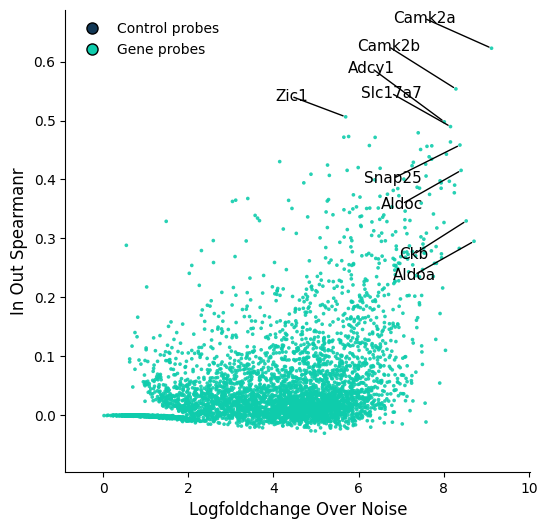

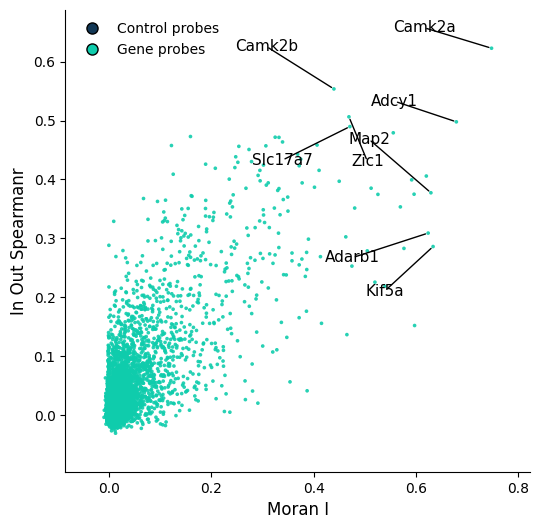

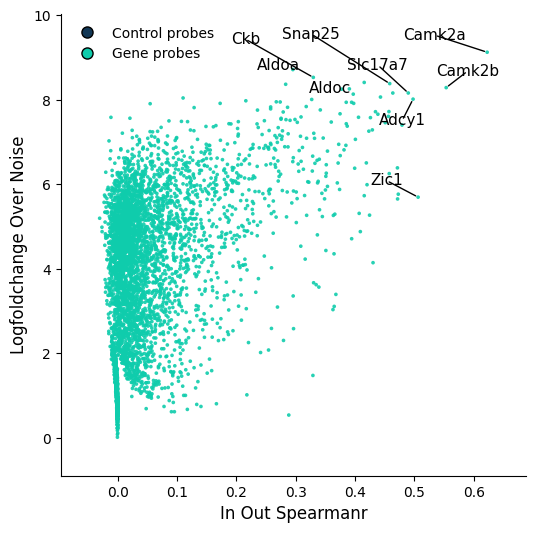

In [14]:
pl.metric_scatter(sdata,x='logfoldchange_over_noise',y='in_out_spearmanR',label_bottom_n_y=0,label_top_n_x=5,label_top_n_y=5,size=7,linewidth=0,figures_path=saving_path,custom_plot_filename='scatter_inout_logfoldratio.pdf')
pl.metric_scatter(sdata,x='moran_I',y='in_out_spearmanR',label_bottom_n_y=0,label_top_n_x=5,label_top_n_y=5,size=7,linewidth=0,figures_path=saving_path,custom_plot_filename='scatter_moranI_inout.pdf')
pl.metric_scatter(sdata,y='logfoldchange_over_noise',x='in_out_spearmanR',label_bottom_n_y=0,label_top_n_x=5,label_top_n_y=5,size=7,linewidth=0,figures_path=saving_path,custom_plot_filename='scatter_logfoldratio_inout.pdf')

## Plot some maps as example

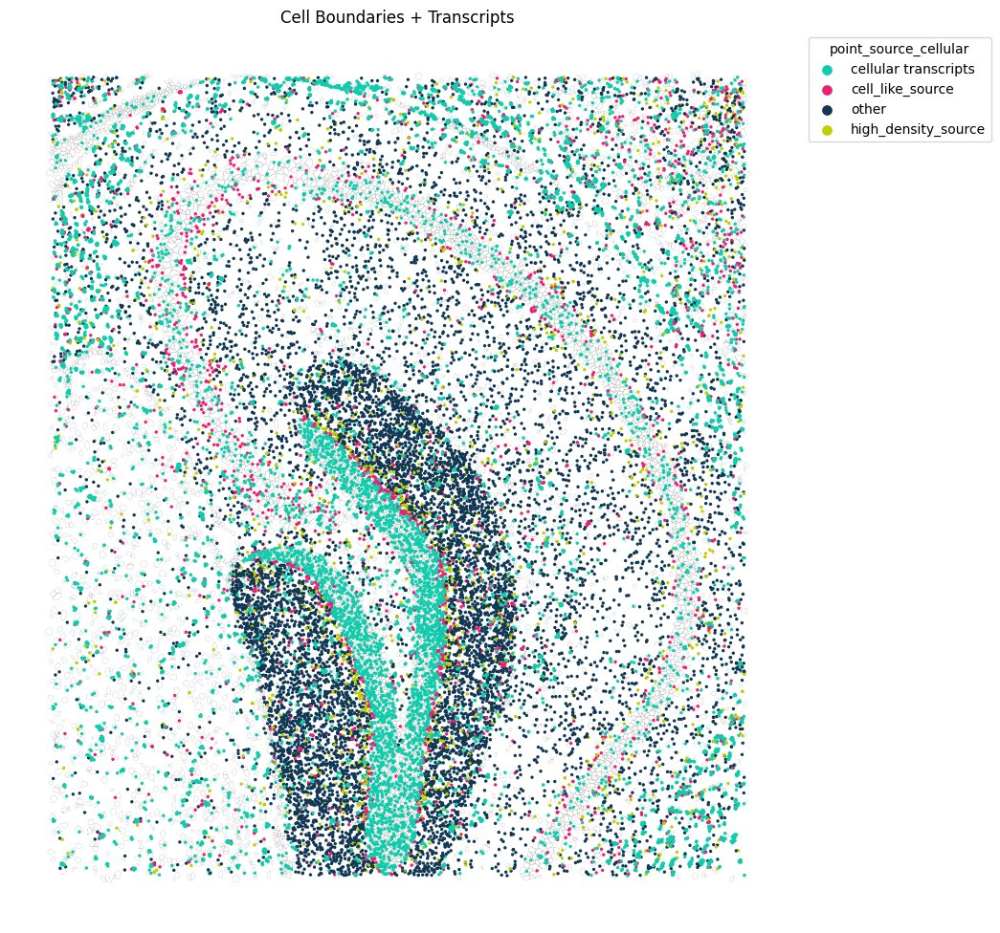

In [16]:
fig=pl.spatial_transcripts(sdata, gene_list=['Ppp1r16b'],scatter_size=4,figsize=(10,10),boundary_linewidth=0.2)
plt.savefig(os.path.join(saving_path,'spatial_transcript_msbrain_ppp1r16b.pdf'))

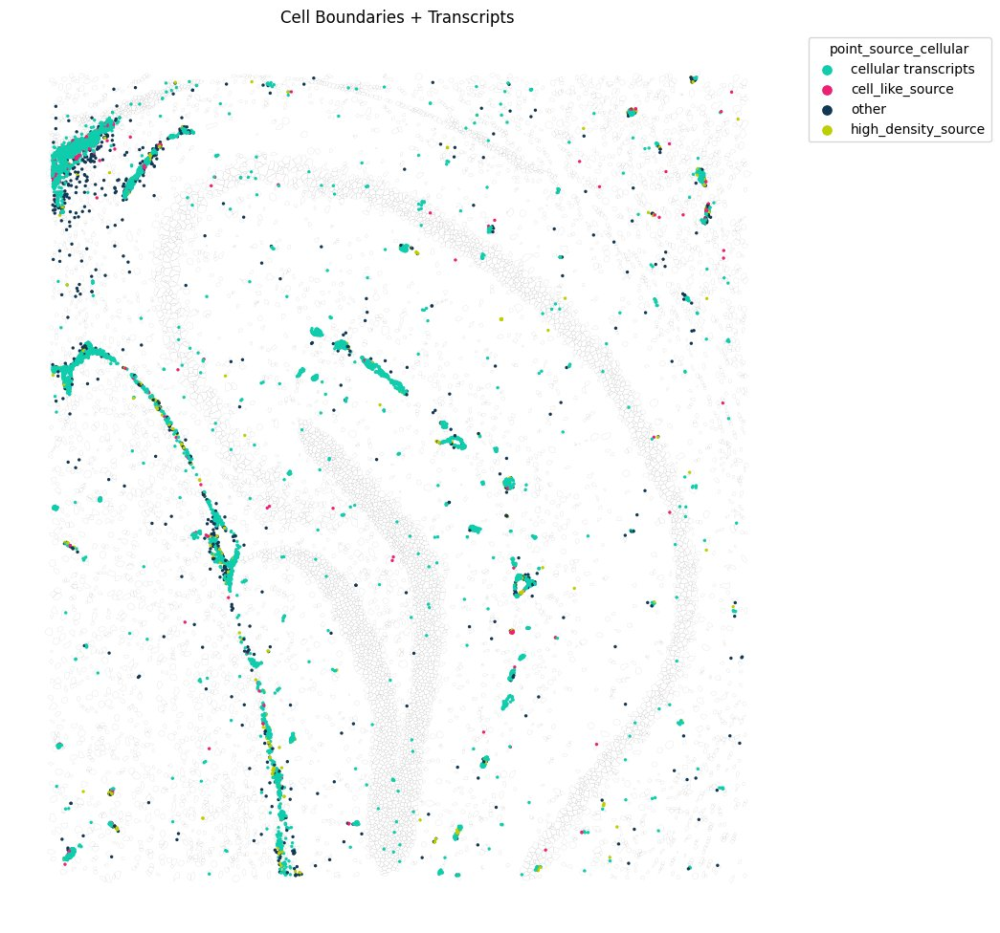

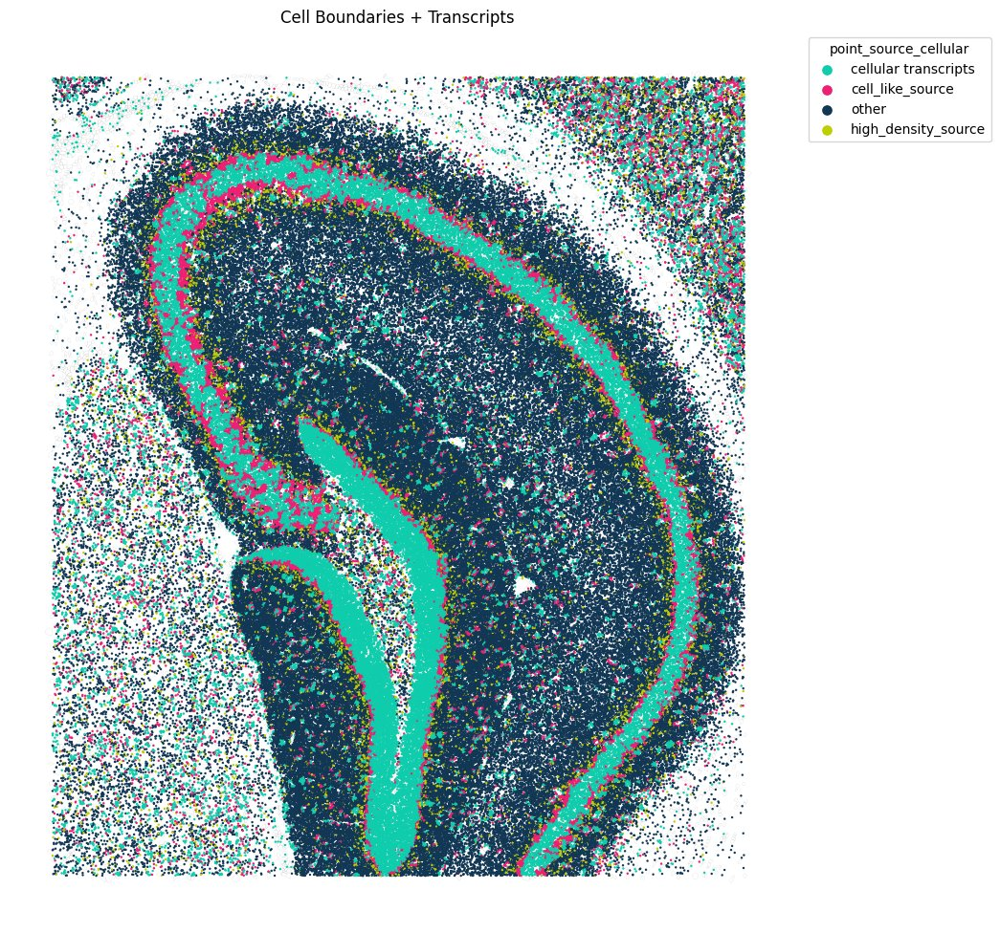

In [20]:
fig=pl.spatial_transcripts(sdata, gene_list=['Igf2'],scatter_size=4,figsize=(10,10),boundary_linewidth=0.1)
plt.savefig(os.path.join(saving_path,'spatial_transcript_msbrain_igf2.pdf'))

fig=pl.spatial_transcripts(sdata, gene_list=['Camk2a'],scatter_size=2,figsize=(10,10),boundary_linewidth=0.1)
plt.savefig(os.path.join(saving_path,'spatial_transcript_msbrain_camk2a.pdf'))

# Plotting multimodal data agreement

In [49]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize, ListedColormap

def point_metric_comparison(
    sdata,
    points_key: str = "transcripts",
    x_col: str = "cosine_similarity",
    y_col: str = 'cosine_sim_stainings',
    hue_col: str = 'enrichment_class',
    gene_key: str = "gene",
    gene_list: list[str] | None = None,
    subsample_fraction: float | None = None,
    table_key: str = "table",
    structure_table_key: str = "structure_table",
    source_table_key: str = "source_score",
    palette_name: str = "30colors",
    continuous_palette: str = "viridis",
    s: float = 2.0,
    alpha: float = 0.3,
    figsize: tuple[float, float] = (7, 6),
    title: str | None = None,
    show_consensus: bool = True,
    seed: int = 42
) -> sns.JointGrid:
    """
    Creates a JointPlot with marginal distributions (KDEs) comparing point metrics
    from a SpatialData object. Optimized to compute ONLY the required columns,
    optionally downsample for performance, and correctly map custom colormaps 
    across categorical annotations.
    """
    # 1. Pull and Compute the Target Points Dask Dataframe (Column Optimized)
    if points_key not in sdata:
        raise KeyError(f"The key '{points_key}' was not found in the provided SpatialData object.")
        
    points_element = sdata[points_key]
    
    potential_needed_cols = {
        x_col, y_col, hue_col, gene_key, 
        'overlaps_cell', 'point_source', 'structure_id', 'cell_id'
    }
    
    load_cols = [col for col in potential_needed_cols if col in points_element.columns]
    trans_df = points_element[load_cols].compute().copy()
    
    # 2. Optional Gene Filtering Matrix
    if gene_list is not None:
        if gene_key not in trans_df.columns:
            raise KeyError(f"Gene key '{gene_key}' not found in {points_key} columns.")
        trans_df = trans_df[trans_df[gene_key].isin(gene_list)]
        
    if trans_df.empty:
        raise ValueError(f"Points dataframe is empty after filtering for specified genes.")

    # 3. Subsampling Logic (Applied early to minimize downstream table matching overhead)
    if subsample_fraction is not None:
        if not (0.0 < subsample_fraction <= 1.0):
            raise ValueError("subsample_fraction must be a float between 0.0 and 1.0")
        if subsample_fraction < 1.0:
            trans_df = trans_df.sample(frac=subsample_fraction, random_state=seed)

    # 4. Flexible Mapping Logic (Metadata Hunt from Associated Tables)
    for target_col in [x_col, y_col, hue_col]:
        if target_col not in trans_df.columns:
            search_configs = [
                (source_table_key, None),
                (structure_table_key, "structure_id"),
                (table_key, "cell_id")
            ]
            
            for t_key, trans_id_col in search_configs:
                if t_key in sdata.tables and target_col in sdata[t_key].obs.columns:
                    table_obs = sdata[t_key].obs
                    
                    if trans_id_col and trans_id_col not in trans_df.columns:
                        continue
                        
                    if trans_id_col is None:
                        table_series = table_obs[target_col]
                        table_series.index = table_series.index.astype(str)
                        trans_df[target_col] = trans_df.index.astype(str).map(table_series)
                    else:
                        if 'instance_id' in table_obs.columns:
                            map_source = table_obs.set_index('instance_id')[target_col]
                        elif 'cell_id' in table_obs.columns:
                            map_source = table_obs.set_index('cell_id')[target_col]
                        else:
                            map_source = table_obs[target_col]
                        
                        map_source.index = map_source.index.astype(str)
                        trans_df[target_col] = trans_df[trans_id_col].astype(str).map(map_source)
                    
                    if not trans_df[target_col].isna().all():
                        break

    # Clean missing text tokens if generated by mapping pipelines
    for col in [x_col, y_col, hue_col]:
        if col in trans_df.columns:
            trans_df[col] = trans_df[col].replace("nan", np.nan)

    # Clean out drops to prevent layout crashes in marginals/KDE
    trans_df = trans_df.dropna(subset=[x_col, y_col, hue_col])
    if trans_df.empty:
        raise ValueError(f"No matching data left after processing columns: {x_col}, {y_col}, {hue_col}")

    # 5. Smart Palette & Variable Type Handling (Fixed ListedColormap extraction bug)
    is_numeric = pd.api.types.is_numeric_dtype(trans_df[hue_col])
    palette = None
    norm = None

    if is_numeric:
        try:
            palette = plt.get_cmap(palette_name)
        except ValueError:
            palette = plt.get_cmap(continuous_palette)
        
        vals = trans_df[hue_col].astype(float)
        vmax = 1.0 if vals.max() <= 1.0 else vals.max()
        norm = Normalize(vmin=vals.min(), vmax=vmax)
    else:
        binary_targets = ['overlaps_cell', 'extracellular', 'extracellular_stainings']
        if hue_col in binary_targets:
            palette = {True: '#d62728', False: '#1f77b4', 'True': '#d62728', 'False': '#1f77b4'}
        else:
            if hue_col == "point_source_cellular" and "overlaps_cell" in trans_df.columns:
                is_intra_bool = trans_df['overlaps_cell'].astype(str).str.lower() == 'true'
                alt_source = "point_source" if "point_source" in trans_df.columns else hue_col
                trans_df["point_source_cellular"] = np.where(is_intra_bool, "cellular transcripts", trans_df[alt_source].astype(str))
            
            trans_df[hue_col] = trans_df[hue_col].astype("category")
            cats = trans_df[hue_col].cat.categories
            
            try:
                import troutpy
                pal_colors = troutpy.pl.get_palette(palette_name, len(cats))
                palette = list(pal_colors)  # Keep as an accessible iterable sequence of colors
            except (ImportError, KeyError):
                if palette_name in plt.colormaps():
                    cmap_obj = plt.get_cmap(palette_name)
                    # Extract individual discrete colors from the continuous colormap object
                    palette = [cmap_obj(i / max(1, len(cats) - 1)) for i in range(len(cats))]
                else:
                    palette = sns.color_palette("deep" if len(cats) <= 10 else "husl", len(cats))

    # 6. Initialize JointGrid Environment
    grid_palette = palette if not is_numeric else None
    
    g = sns.JointGrid(
        data=trans_df, 
        x=x_col, 
        y=y_col, 
        hue=hue_col if not is_numeric else None, 
        palette=grid_palette
    )
    g.fig.set_size_inches(figsize)

    # 7. Scatter Center Render
    if is_numeric:
        scatter = g.ax_joint.scatter(
            trans_df[x_col], trans_df[y_col], 
            c=trans_df[hue_col], cmap=palette, norm=norm,
            s=s, alpha=alpha, edgecolor=None
        )
        g.fig.colorbar(scatter, ax=g.ax_joint, label=hue_col.replace('_', ' ').title(), fraction=0.046, pad=0.04)
    else:
        g.plot_joint(sns.scatterplot, s=s, alpha=alpha, edgecolor=None)

    # 8. Marginals Execution
    marginal_hue = None if is_numeric else hue_col
    g.plot_marginals(sns.kdeplot, fill=True, alpha=0.2, common_norm=False, hue=marginal_hue, palette=grid_palette)

    # 9. Consensus Baseline Layout Checks
    if show_consensus:
        x_min, x_max = trans_df[x_col].min(), trans_df[x_col].max()
        y_min, y_max = trans_df[y_col].min(), trans_df[y_col].max()
        if (0 <= x_min <= 0.15 and 0.85 <= x_max <= 1.05) and (0 <= y_min <= 0.15 and 0.85 <= y_max <= 1.05):
            g.ax_joint.plot([0, 1], [0, 1], color='#2B2B2B', linestyle='--', alpha=0.5, label='Consensus', zorder=1)

    # 10. Clean Text Arrays & Modular Styling
    clean_x = x_col.replace('_', ' ').title()
    clean_y = y_col.replace('_', ' ').title()
    clean_hue = hue_col.replace('_', ' ').title()
    
    g.ax_joint.set_xlabel(clean_x, fontweight='medium')
    g.ax_joint.set_ylabel(clean_y, fontweight='medium')

    if title is None:
        sub_info = f" (Downsampled to {subsample_fraction*100:.1f}%)" if subsample_fraction else ""
        title = f"{clean_x} vs {clean_y}{sub_info}\nStratified by: {clean_hue}"
    g.fig.suptitle(title, fontweight='bold', y=1.02, fontsize=11)

    # 11. Secondary Legend Overrides
    if not is_numeric:
        handles, labels = g.ax_joint.get_legend_handles_labels()
        if handles:
            unique_labels = dict(zip(labels, handles))
            g.ax_joint.legend(
                unique_labels.values(), unique_labels.keys(),
                title=clean_hue, bbox_to_anchor=(1.22, 1), loc='upper left', frameon=True
            )
    else:
        if g.ax_joint.get_legend() is not None:
            g.ax_joint.get_legend().remove()

    return g

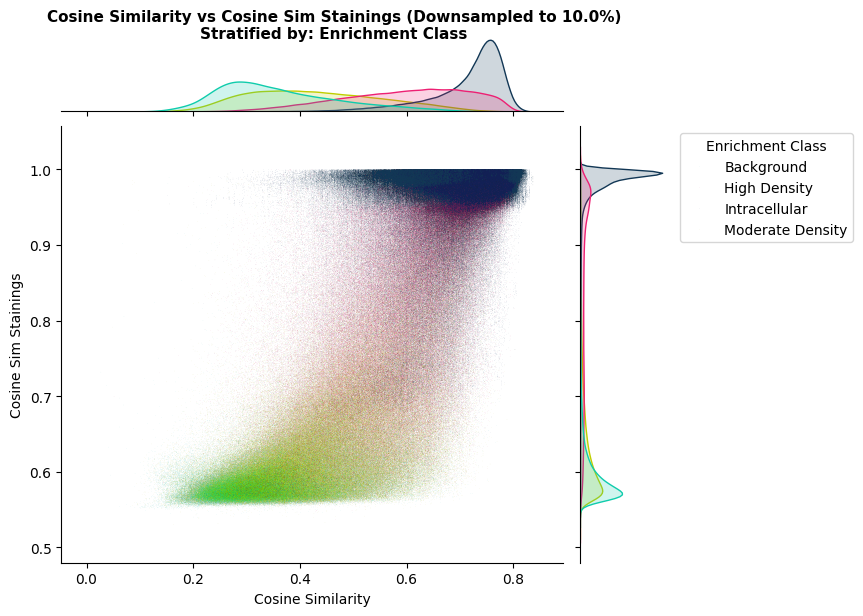

In [54]:
plot_config = {"points_key": "transcripts","x_col": "cosine_similarity", 
"y_col": "cosine_sim_stainings", "hue_col": "enrichment_class",  
# "gene_list": ["Camk2a"],  # Even if this is commented out or missing, it won't crash!
"s": 0.02, "alpha": 0.90, "palette_name": "30colors","subsample_fraction": 0.1}

# 3. Execute the optimized comparison function
g = pl.point_metric_comparison(sdata, **plot_config)
genes = plot_config.get('gene_list', [])
gene_suffix = f"_{'_'.join(genes)}" if genes else "_all_genes"
subsample_suffix = f"_subsample{plot_config['subsample_fraction']}" if "subsample_fraction" in plot_config else ""

# Construct the final filename
pdf_filename = f"joint_{plot_config['points_key']}_{plot_config['x_col']}_vs_{plot_config['y_col']}_by_{plot_config['hue_col']}{gene_suffix}{subsample_suffix}.pdf"
g.savefig(saving_path / pdf_filename, bbox_inches="tight", dpi=300)


NameError: name 'genes_to_plot' is not defined

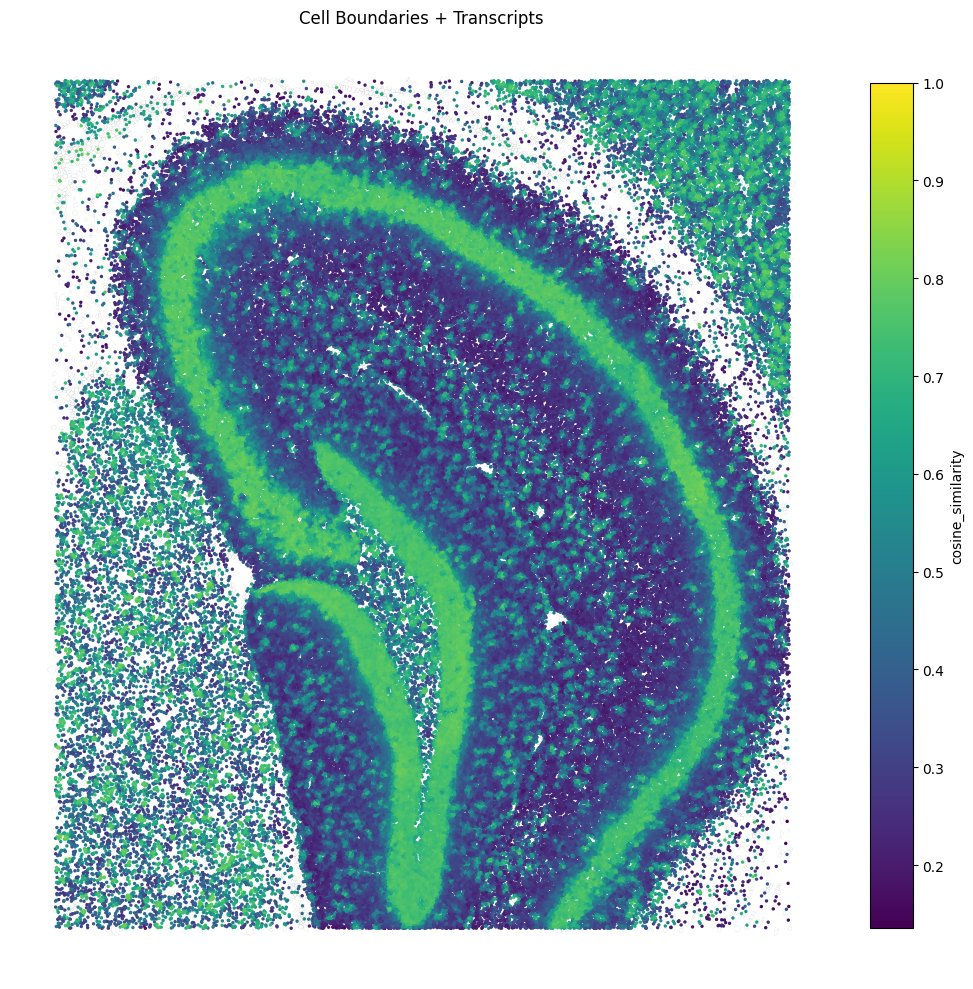

In [117]:
# 3. Call the spatial transcripts plotting function (unpacking the fig and ax tuple)
fig, ax = pl.spatial_transcripts(
    sdata, 
    gene_list=['Camk2a'],
    color_key='cosine_similarity',
    scatter_size=4,
    figsize=(10,10),
    boundary_linewidth=0.1,
    use_roi=False,
)

# 4. Construct a descriptive and organized filename 
gene_str = "_".join(['Cam2ka'])
pdf_filename = f"spatial_transcripts_{gene_str}_{metric_key}.pdf"

# 5. Export to the file system as a vector PDF and close the background cache
full_export_path = saving_path / pdf_filename
fig.savefig(full_export_path, bbox_inches="tight", dpi=300)
plt.show()
plt.close(fig)

print(f"Figure successfully saved to:\n{full_export_path}")

--- Processing Batch for Palette: YlGnBu ---
Saved: spatial_roi_cosine_similarity_YlGnBu.pdf


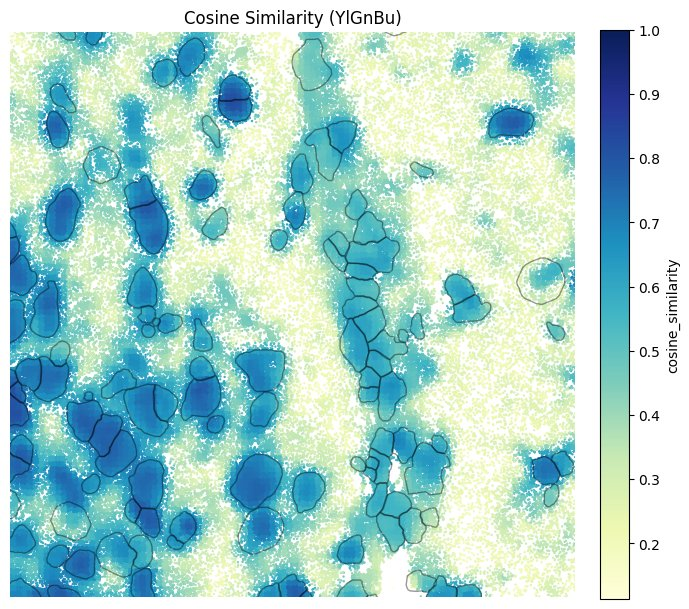

Saved: spatial_roi_cosine_sim_stainings_YlGnBu.pdf


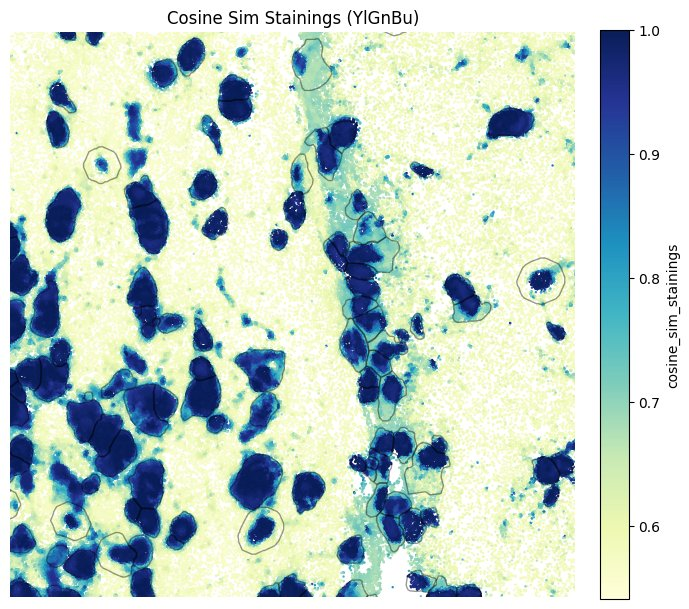

Saved: spatial_roi_enrichment_over_random_YlGnBu_vmax12.pdf


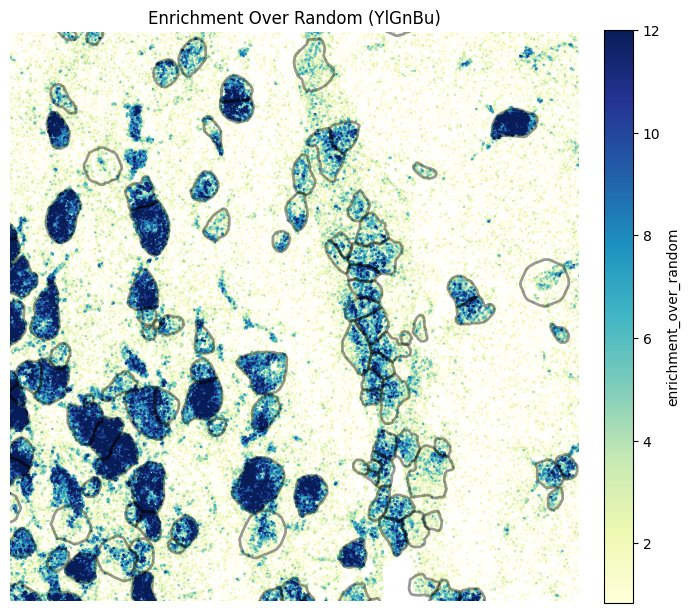

--- Processing Batch for Palette: terrain ---
Saved: spatial_roi_cosine_similarity_terrain.pdf


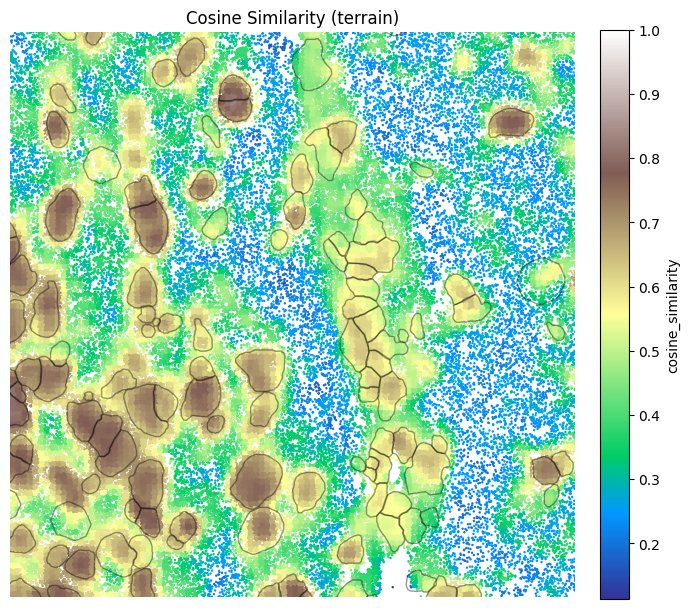

Saved: spatial_roi_cosine_sim_stainings_terrain.pdf


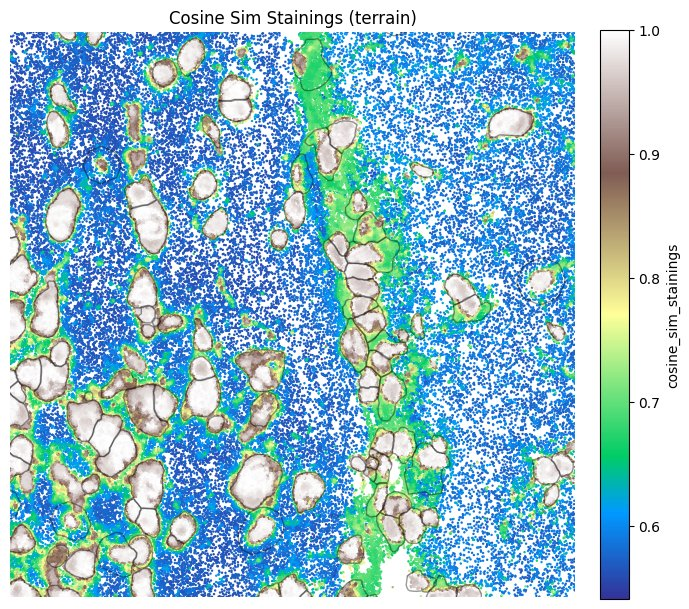

Saved: spatial_roi_enrichment_over_random_terrain_vmax12.pdf


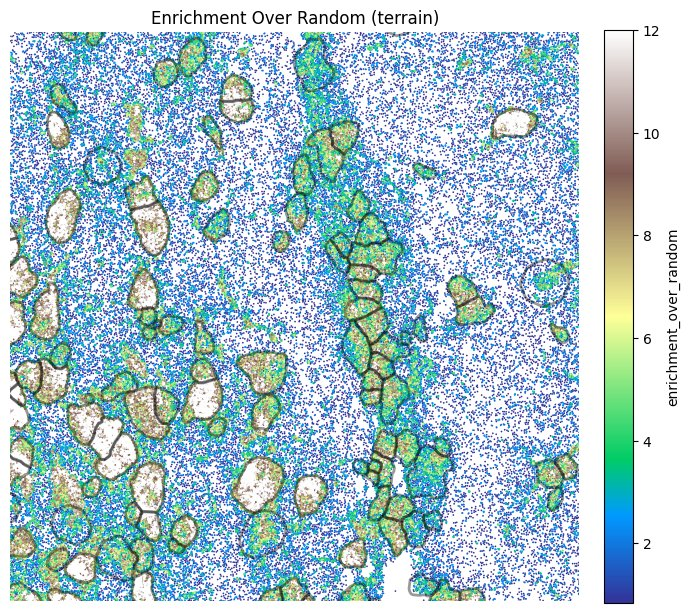

In [ ]:
# 2. Centralize your plot payloads into a clean configuration list
plot_jobs = [
    {"color_key": "cosine_similarity", "scatter_size": 2.0, "boundary_linewidth": 1.0, "vmax": None},
    {"color_key": "cosine_sim_stainings", "scatter_size": 2.0, "boundary_linewidth": 1.0, "vmax": None},
    {"color_key": "enrichment_over_random", "scatter_size": 1.0, "boundary_linewidth": 2.0, "vmax": 12}
]

# Shared spatial configurations across all figures
shared_kwargs = {
    "figsize": (7, 7),
    "use_roi": True,
    "roi": (4500, 4700, 1100, 1300)
}

# The target palettes to run over your datasets
palettes = ["YlGnBu", "terrain"]

# 3. Double-loop to generate, display, and export every matrix combination
for palette in palettes:
    print(f"--- Processing Batch for Palette: {palette} ---")
    for job in plot_jobs:
        
        # Merge individual configurations with the shared spatial parameters
        current_title = f"{job['color_key'].replace('_', ' ').title()} ({palette})"
        
        fig, ax = pl.spatial_transcripts(
            sdata,
            color_key=job["color_key"],
            scatter_size=job["scatter_size"],
            boundary_linewidth=job["boundary_linewidth"],
            colormap=palette,
            vmax=job["vmax"],
            title=current_title,
            **shared_kwargs
        )
        
        # Construct a predictable, script-friendly filename tracking all variables
        vmax_suffix = f"_vmax{job['vmax']}" if job['vmax'] is not None else ""
        pdf_filename = f"spatial_roi_{job['color_key']}_{palette}{vmax_suffix}.pdf"
        full_export_path = saving_path / pdf_filename
        
        # Save vector graphic to server
        fig.savefig(full_export_path, bbox_inches="tight", dpi=300)
        print(f"Saved: {pdf_filename}")
        
        # Render inline in notebook or clear from background cache
        plt.show()
#        plt.close(fig)

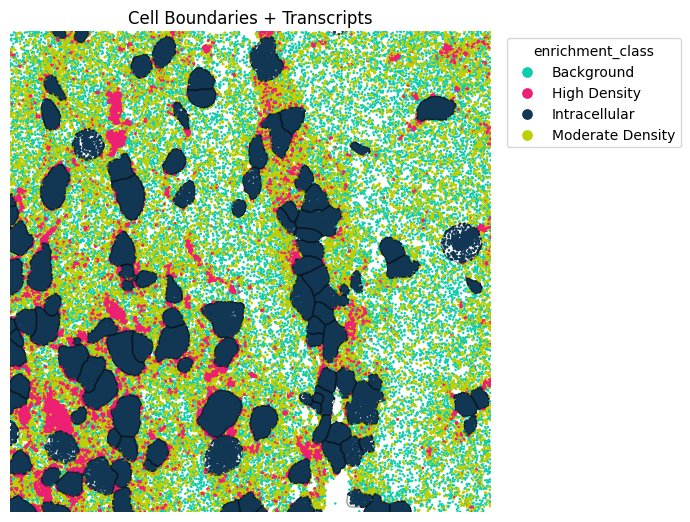

In [166]:
shared_kwargs = {"figsize": (7, 7),"use_roi": True,"roi": (4500, 4700, 1100, 1300)}

palette='30colors'

fig=spatial_transcripts(sdata,color_key='enrichment_class',
scatter_size=2.0,boundary_linewidth=1.0,colormap=palette,**shared_kwargs)

In [162]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

def visualize_individual_stainings_manual(
    sdata,
    trans_df,  # Pass your filtered transcripts dataframe to calculate spatial ranges
    image_key: str = "morphology_focus",
    scale_key: str = "scale0",
    roi: tuple[float, float, float, float] | None = None,
    figsize: tuple[float, float] = (7, 7),
    cmap: str = "gray",
    saving_path: Path | str | None = None, max_pct=95.0
):
    """
    Manually calculates the scale transformation between global transcripts 
    and pixel space, offsets to 0,0, and slices the exact pixel crop window.
    """
    print("\n=== STEP 1: Transcript Global Ranges ===")
    t_xmin, t_xmax = trans_df['x'].min(), trans_df['x'].max()
    t_ymin, t_ymax = trans_df['y'].min(), trans_df['y'].max()
    
    t_dx = t_xmax - t_xmin
    t_dy = t_ymax - t_ymin
    print(f"Global Transcripts Bounds -> X: [{t_xmin:.2f} to {t_xmax:.2f}] (Delta: {t_dx:.2f})")
    print(f"Global Transcripts Bounds -> Y: [{t_ymin:.2f} to {t_ymax:.2f}] (Delta: {t_dy:.2f})")

    print("\n=== STEP 2: Raw Image Matrix Dimensions ===")
    node = sdata.images[image_key][scale_key]
    img_data = node.image if hasattr(node, "image") else node
    img_shape = img_data.shape  # Expecting (c, y, x)
    print(f"Raw Image Shape (c, y, x): {img_shape}")
    img_c, img_h, img_w = img_shape[0], img_shape[1], img_shape[2]

    print("\n=== STEP 3: Scaling Factor Derivation ===")
    # Calculate scale factor between the spatial bounding span vs the pixel canvas dimensions
    scale_x = img_w / t_dx
    scale_y = img_h / t_dy
    # Averaging to match identical proportional isotropic scaling
    scale_factor = (scale_x + scale_y) / 2
    print(f"Calculated Scale Factor (Pixels per Spatial Unit): {scale_factor:.5f}")

    if roi is not None:
        print("\n=== STEP 4: Target ROI Transformation ===")
        roi_xmin, roi_xmax, roi_ymin, roi_ymax = roi
        print(f"Target Global ROI Window -> X: [{roi_xmin}, {roi_xmax}] | Y: [{roi_ymin}, {roi_ymax}]")
        
        # 1. Shift target spatial coordinates to begin at 0,0 relative to data baseline
        shifted_xmin = roi_xmin - t_xmin
        shifted_xmax = roi_xmax - t_xmin
        shifted_ymin = roi_ymin - t_ymin
        shifted_ymax = roi_ymax - t_ymin
        
        # 2. Scale coordinate spaces into actual matrix array indices
        pixel_xmin = int(np.floor(shifted_xmin * scale_factor))
        pixel_xmax = int(np.ceil(shifted_xmax * scale_factor))
        pixel_ymin = int(np.floor(shifted_ymin * scale_factor))
        pixel_ymax = int(np.ceil(shifted_ymax * scale_factor))
        
        # Clip values to ensure they do not exceed array edge limitations
        pixel_xmin = max(0, min(pixel_xmin, img_w))
        pixel_xmax = max(0, min(pixel_xmax, img_w))
        pixel_ymin = max(0, min(pixel_ymin, img_h))
        pixel_ymax = max(0, min(pixel_ymax, img_h))
        
        print(f"Transformed Pixel Crop Windows -> X indices: [{pixel_xmin} : {pixel_xmax}]")
        print(f"Transformed Pixel Crop Windows -> Y indices: [{pixel_ymin} : {pixel_ymax}]")
        
        # Slice raw pixel matrix using mapped array index limits
        cropped_img = img_data[:, pixel_ymin:pixel_ymax, pixel_xmin:pixel_xmax]
    else:
        cropped_img = img_data
        roi_xmin, roi_xmax, roi_ymin, roi_ymax = t_xmin, t_xmax, t_ymin, t_ymax

    # 5. Extract existing channel coordinate markers
    if "c" in cropped_img.coords:
        channel_names = [str(ch) for ch in cropped_img.coords["c"].values]
    else:
        channel_names = [f"Channel_{i}" for i in range(cropped_img.shape[0])]

    print("\n=== STEP 5: Generating and Saving Aligned Figures ===")
    for idx, ch_name in enumerate(channel_names):
        # Bring data chunk explicitly into RAM memory safely
        channel_slice = cropped_img[idx, :, :].compute() if hasattr(cropped_img, "compute") else cropped_img[idx, :, :]
        img_np = np.asarray(channel_slice)
        
        fig, ax = plt.subplots(figsize=figsize)
        
        # Use origin='lower' to preserve Xenium geometric orientation alignment
        extent = [roi_xmin, roi_xmax, roi_ymin, roi_ymax]
        im = ax.imshow(img_np, cmap=cmap, origin="lower", extent=extent)
        
        ax.set_title(f"Staining: {image_key} | {ch_name}\n(Manual Transform Alignment)", fontweight='bold', fontsize=10)
        ax.axis("off")
        
        plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
        plt.tight_layout()
        
        if saving_path is not None:
            save_dir = Path(saving_path)
            save_dir.mkdir(parents=True, exist_ok=True)
            roi_suffix = f"_roi_{int(roi_xmin)}_{int(roi_xmax)}"
            clean_ch_name = ch_name.replace(" ", "_").replace("/", "-")
            pdf_filename = f"staining_manual_transform_{clean_ch_name}{roi_suffix}.pdf"
            
            fig.savefig(save_dir / pdf_filename, bbox_inches="tight", dpi=300)
            print(f"-> Successfully saved: {pdf_filename}")
            
        plt.show()
        plt.close(fig)

--- Initializing Manual Transformation Pipeline ---

=== STEP 1: Transcript Global Ranges ===
Global Transcripts Bounds -> X: [4069.39 to 5779.78] (Delta: 1710.39)
Global Transcripts Bounds -> Y: [977.52 to 2953.72] (Delta: 1976.20)

=== STEP 2: Raw Image Matrix Dimensions ===
Raw Image Shape (c, y, x): (5, 9300, 8049)

=== STEP 3: Scaling Factor Derivation ===
Calculated Scale Factor (Pixels per Spatial Unit): 4.70597

=== STEP 4: Target ROI Transformation ===
Target Global ROI Window -> X: [4500, 4700] | Y: [1100, 1300]
Transformed Pixel Crop Windows -> X indices: [2026 : 2968]
Transformed Pixel Crop Windows -> Y indices: [576 : 1518]

=== STEP 5: Generating and Saving Aligned Figures ===
-> Successfully saved: staining_manual_transform_DAPI_roi_4500_4700.pdf


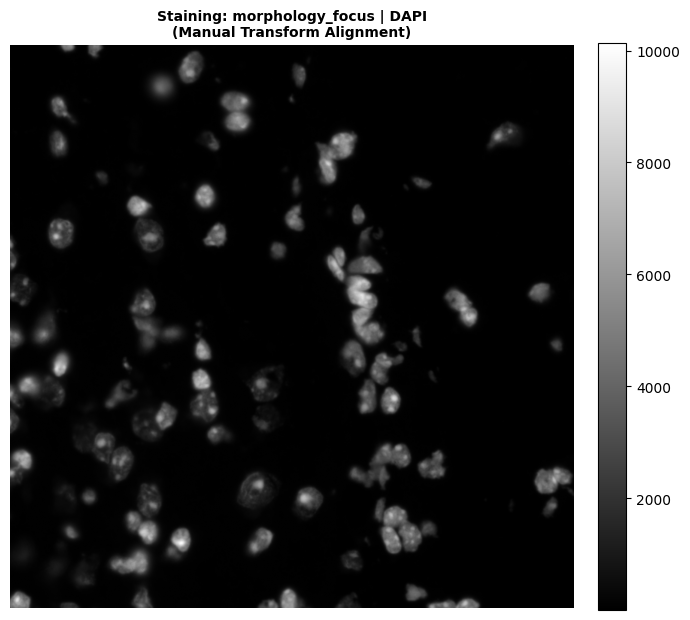

-> Successfully saved: staining_manual_transform_ATP1A1-CD45-E-Cadherin_roi_4500_4700.pdf


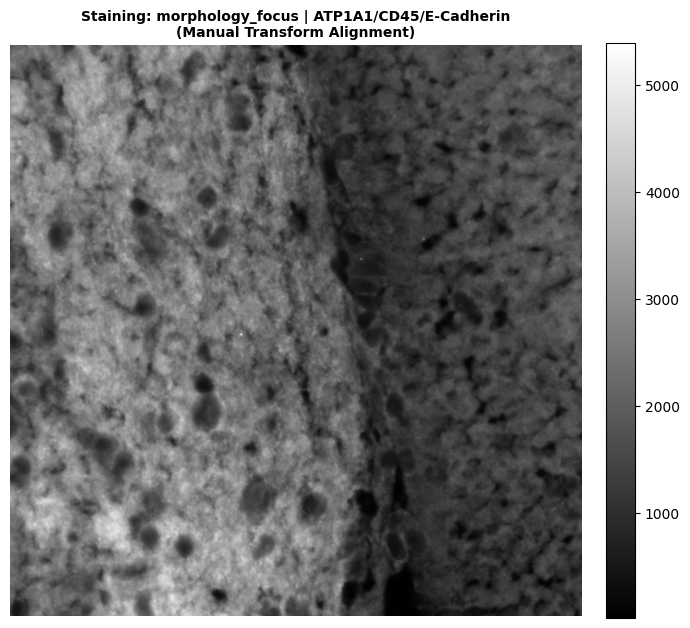

-> Successfully saved: staining_manual_transform_18S_roi_4500_4700.pdf


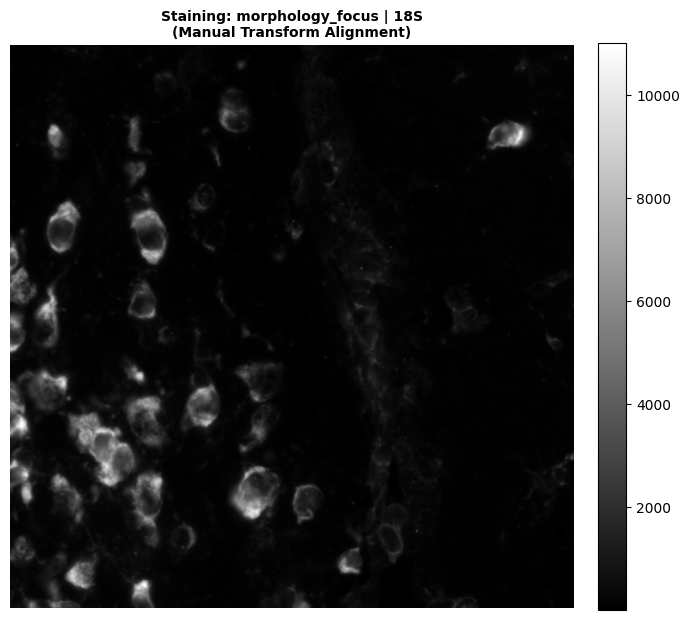

-> Successfully saved: staining_manual_transform_AlphaSMA-Vimentin_roi_4500_4700.pdf


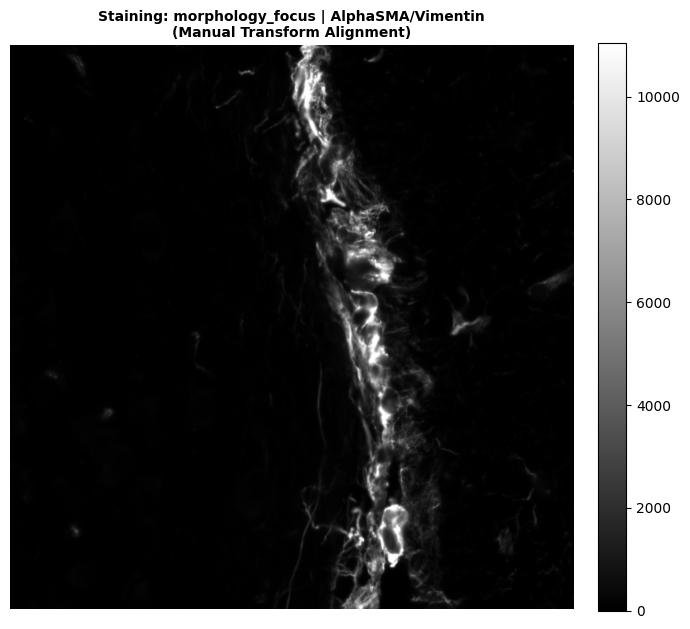

-> Successfully saved: staining_manual_transform_dummy_roi_4500_4700.pdf


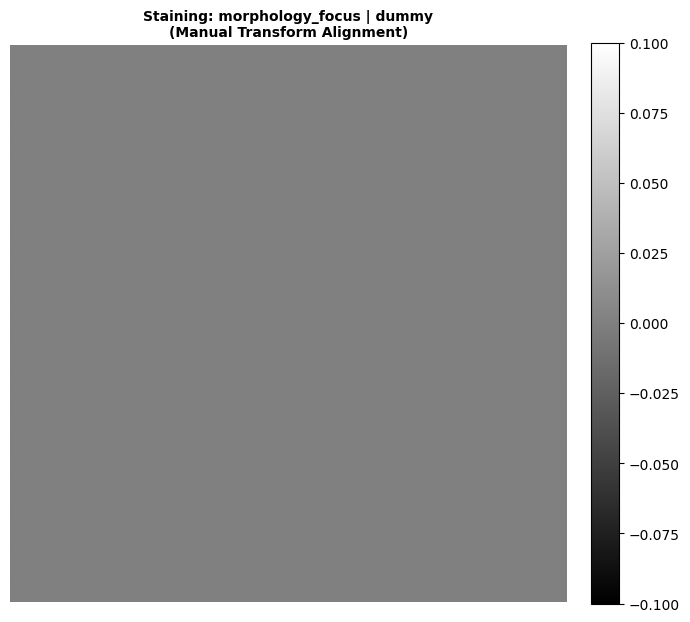

In [163]:
# Pull the base transcript array out of the Dask environment to acquire baseline ranges
transcripts_base_df = sdata["transcripts"].compute()

target_roi = (4500, 4700, 1100, 1300)

print("--- Initializing Manual Transformation Pipeline ---")
visualize_individual_stainings_manual(
    sdata=sdata,
    trans_df=transcripts_base_df,
    image_key="morphology_focus",
    scale_key="scale0",
    roi=target_roi,
    figsize=(7, 7),
    cmap="gray",
    saving_path=saving_path
)

In [158]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

def visualize_composite_staining_intensity_alpha(
    sdata,
    trans_df,  # Base transcripts dataframe for range calculation
    image_key: str = "morphology_focus",
    scale_key: str = "scale0",
    roi: tuple[float, float, float, float] | None = None,
    figsize: tuple[float, float] = (10, 10),
    include_channels: list[int] | None = None,  # NEW: Explicit list of channel indices to plot
    cmaps: list[str] | None = None,            # List of continuous colormaps matching selected channels
    title: str = "Composite Staining (Intensity-Based Alpha)",
    saving_path: Path | str | None = None,
    max_pct:float=98
):
    """
    Creates an aligned composite visualization of chosen staining channels.
    Pixels map their signal intensity directly to their transparency channel.
    Automatically excludes the final dummy channel.
    """
    print("\n=== [1/5] Transcript Global Ranges (Baseline calculation) ===")
    t_xmin, t_xmax = trans_df['x'].min(), trans_df['x'].max()
    t_ymin, t_ymax = trans_df['y'].min(), trans_df['y'].max()
    t_dx, t_dy = t_xmax - t_xmin, t_ymax - t_ymin

    print("\n=== [2/5] Raw Image Metadata (Scale0) ===")
    node = sdata.images[image_key][scale_key]
    img_dask_array = node.image.data if hasattr(node, "image") else node.data
    img_shape = img_dask_array.shape  # (c, y, x)
    img_c, img_h, img_w = img_shape[0], img_shape[1], img_shape[2]

    print("\n=== [3/5] Scaling Factor Derivation ===")
    scale_x, scale_y = img_w / t_dx, img_h / t_dy
    scale_factor = (scale_x + scale_y) / 2

    if roi is not None:
        roi_xmin, roi_xmax, roi_ymin, roi_ymax = roi
        shifted_xmin, shifted_xmax = roi_xmin - t_xmin, roi_xmax - t_xmin
        shifted_ymin, shifted_ymax = roi_ymin - t_ymin, roi_ymax - t_ymin
        
        pixel_xmin = max(0, int(np.floor(shifted_xmin * scale_factor)))
        pixel_xmax = min(img_w, int(np.ceil(shifted_xmax * scale_factor)))
        pixel_ymin = max(0, int(np.floor(shifted_ymin * scale_factor)))
        pixel_ymax = min(img_h, int(np.ceil(shifted_ymax * scale_factor)))
        
        cropped_img_dask = img_dask_array[:, pixel_ymin:pixel_ymax, pixel_xmin:pixel_xmax]
    else:
        cropped_img_dask = img_dask_array
        roi_xmin, roi_xmax, roi_ymin, roi_ymax = t_xmin, t_xmax, t_ymin, t_ymax

    print("\n=== [4/5] Composite Processing (Filtering Selected Indices) ===")
    if "c" in node.coords:
        full_channel_names = [str(ch) for ch in node.coords["c"].values]
    else:
        full_channel_names = [f"Channel_{i}" for i in range(img_c)]
    
    # Baseline non-dummy channels list
    valid_channel_names = full_channel_names[:-1]
    
    # Compute the cropped pixel subset into RAM safely
    cropped_pixel_matrix = cropped_img_dask.compute()
    valid_pixel_data = cropped_pixel_matrix[:-1, :, :]
    
    # If no target subset is passed, default to all non-dummy indices
    if include_channels is None:
        include_channels = list(range(len(valid_channel_names)))
        
    final_channels_to_plot = []
    final_pixel_data_list = []
    
    for idx in include_channels:
        if idx >= len(valid_channel_names) or idx < 0:
            print(f"-> [WARNING] Requested index {idx} out of range or maps to dummy channel. Skipping.")
            continue
        final_channels_to_plot.append(valid_channel_names[idx])
        final_pixel_data_list.append(valid_pixel_data[idx, :, :])
        
    print(f"-> Actively plotting selected channels: {final_channels_to_plot} (Indices: {include_channels})")
    
    # Ensure fallback colormaps list aligns with the length of chosen channels
    if cmaps is None:
        standard_palette = ['Blues', 'Greens', 'Oranges', 'Reds', 'Purples', 'YlOrBr']
        cmaps = standard_palette[:len(final_channels_to_plot)]
        if len(cmaps) < len(final_channels_to_plot):
            cmaps += ['viridis'] * (len(final_channels_to_plot) - len(cmaps))

    if len(cmaps) < len(final_channels_to_plot):
        raise ValueError(f"Length of provided colormaps list ({len(cmaps)}) does not match selected channels ({len(final_channels_to_plot)})")

    # 5. Render and Export Figure using structural RGBA blending
    print("\n=== [5/5] Plotting Intensity-Alpha Blended Figure ===")
    fig, ax = plt.subplots(figsize=figsize)
    extent = [roi_xmin, roi_xmax, roi_ymin, roi_ymax]
    handles = [] 
    
    for idx, ch_name in enumerate(final_channels_to_plot):
        single_channel_data = final_pixel_data_list[idx]
        
        # Normalize intensities using robust percentiles to clean background noise
        v_min, v_max = np.percentile(single_channel_data, (1, max_pct))
        if v_max == v_min: v_max += 1e-5
        normalized_data = (single_channel_data - v_min) / (v_max - v_min)
        normalized_data = np.clip(normalized_data, 0, 1)
        
        # Convert the 2D intensity profile into a mapped 3D RGB grid based on colormap
        cmap_lookup = plt.get_cmap(cmaps[idx])
        rgba_image = cmap_lookup(normalized_data)  # (Y, X, 4)
        
        # Overwrite alpha layer directly with the normalized signal intensity
        rgba_image[..., 3] = normalized_data 
        
        # Render the pre-compiled RGBA layer
        ax.imshow(
            rgba_image, 
            origin="lower", 
            extent=extent
        )
        
        # Setup legend tags using the color high-point
        marker_color = cmap_lookup(0.8)
        handles.append(plt.Line2D([0], [0], color=marker_color, lw=4, label=ch_name))

    ax.set_title(title, fontweight='bold', fontsize=12)
    ax.axis("off")
    ax.legend(handles=handles, title="Stainings", bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
    plt.tight_layout()
    
    if saving_path is not None:
        save_dir = Path(saving_path)
        save_dir.mkdir(parents=True, exist_ok=True)
        roi_suffix = f"_roi_{int(roi_xmin)}_{int(roi_xmax)}" if roi is not None else ""
        ch_suffix = f"_channels_" + "_".join(map(str, include_channels))
        pdf_filename = f"staining_composite{ch_suffix}_intensity_alpha{roi_suffix}.pdf"
        
        fig.savefig(save_dir / pdf_filename, bbox_inches="tight", dpi=300)
        print(f"-> Intensity-alpha composite PDF saved: {pdf_filename}")
        
    plt.show()
    plt.close(fig)


=== [1/5] Transcript Global Ranges (Baseline calculation) ===

=== [2/5] Raw Image Metadata (Scale0) ===

=== [3/5] Scaling Factor Derivation ===

=== [4/5] Composite Processing (Filtering Selected Indices) ===
-> Actively plotting selected channels: ['DAPI', '18S', 'AlphaSMA/Vimentin'] (Indices: [0, 2, 3])

=== [5/5] Plotting Intensity-Alpha Blended Figure ===
-> Intensity-alpha composite PDF saved: staining_composite_channels_0_2_3_intensity_alpha_roi_4500_4700.pdf


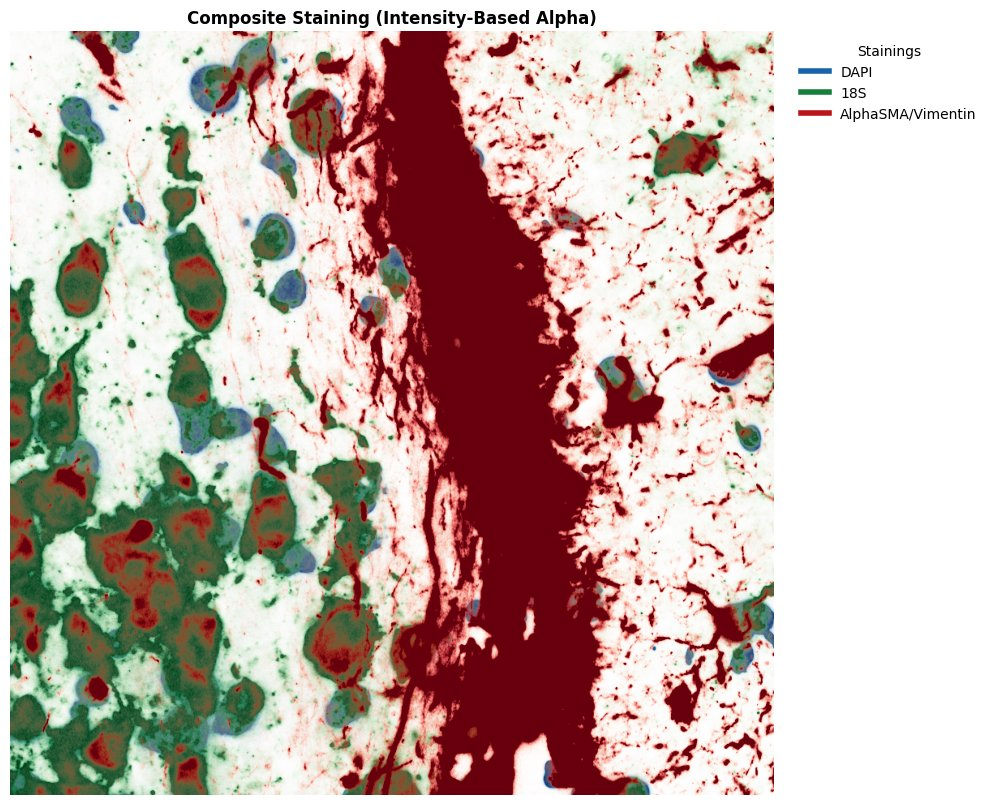

In [161]:
visualize_composite_staining_intensity_alpha(
    sdata=sdata,
    trans_df=transcripts_base_df,
    image_key="morphology_focus",
    scale_key="scale0",
    roi=(4500, 4700, 1100, 1300),
    figsize=(10, 10),
    include_channels=[0, 2, 3],               # Target array selection
    cmaps=['Blues', 'Greens', 'Reds'],        # 3 colormaps matching your 3 indices
    saving_path=saving_path,max_pct=80.0
)


=== [1/5] Transcript Global Ranges (Baseline calculation) ===

=== [2/5] Raw Image Metadata (Scale0) ===

=== [3/5] Scaling Factor Derivation ===

=== [4/5] Composite Processing (Filtering Selected Indices) ===
-> Actively plotting selected channels: ['DAPI', '18S', 'AlphaSMA/Vimentin'] (Indices: [0, 2, 3])

=== [5/5] Plotting Intensity-Alpha Blended Figure ===
-> Intensity-alpha composite PDF saved: staining_composite_channels_0_2_3_intensity_alpha_roi_4700_4900.pdf


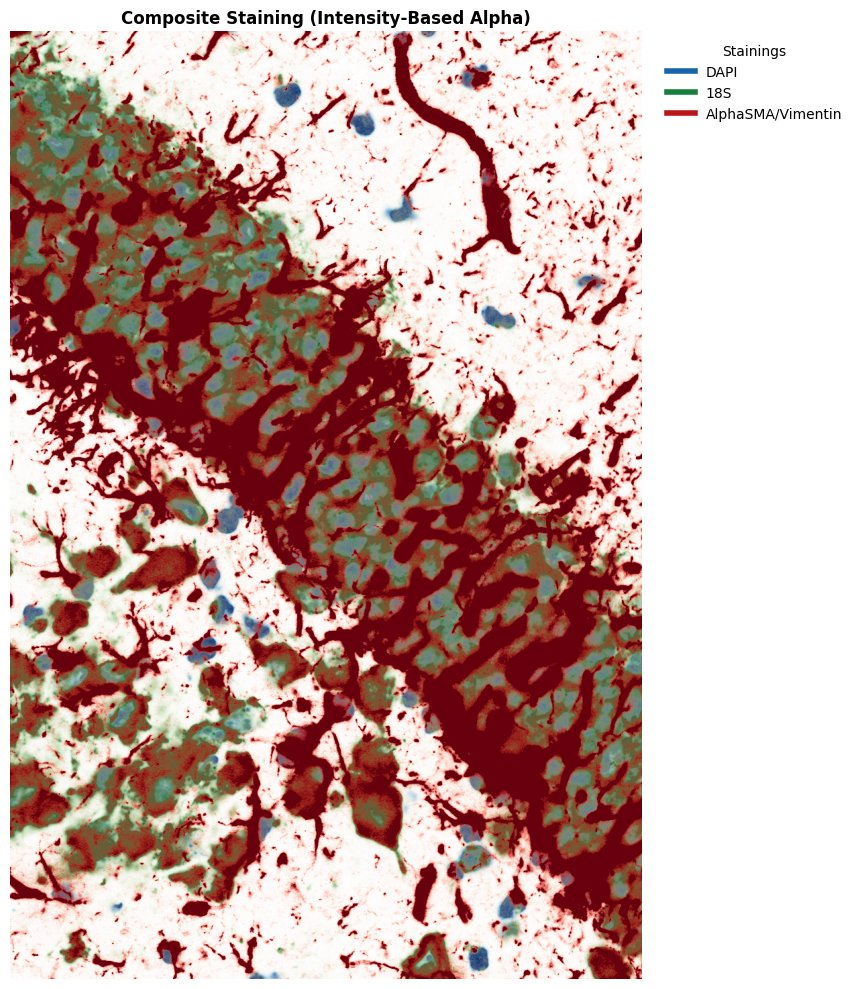

In [168]:
visualize_composite_staining_intensity_alpha(
    sdata=sdata,
    trans_df=transcripts_base_df,
    image_key="morphology_focus",
    scale_key="scale0",
    roi=(4700, 4900, 1800, 2100),
    figsize=(10, 10),
    include_channels=[0, 2, 3],               # Target array selection
    cmaps=['Blues', 'Greens', 'Reds'],        # 3 colormaps matching your 3 indices
    saving_path=saving_path,max_pct=80.0
)


=== [1/5] Transcript Global Ranges (Baseline calculation) ===

=== [2/5] Raw Image Metadata (Scale0) ===

=== [3/5] Scaling Factor Derivation ===

=== [4/5] Composite Processing (Filtering Selected Indices) ===
-> Actively plotting selected channels: ['DAPI', '18S', 'AlphaSMA/Vimentin'] (Indices: [0, 2, 3])

=== [5/5] Plotting Intensity-Alpha Blended Figure ===
-> Intensity-alpha composite PDF saved: staining_composite_channels_0_2_3_intensity_alpha_roi_4900_5100.pdf


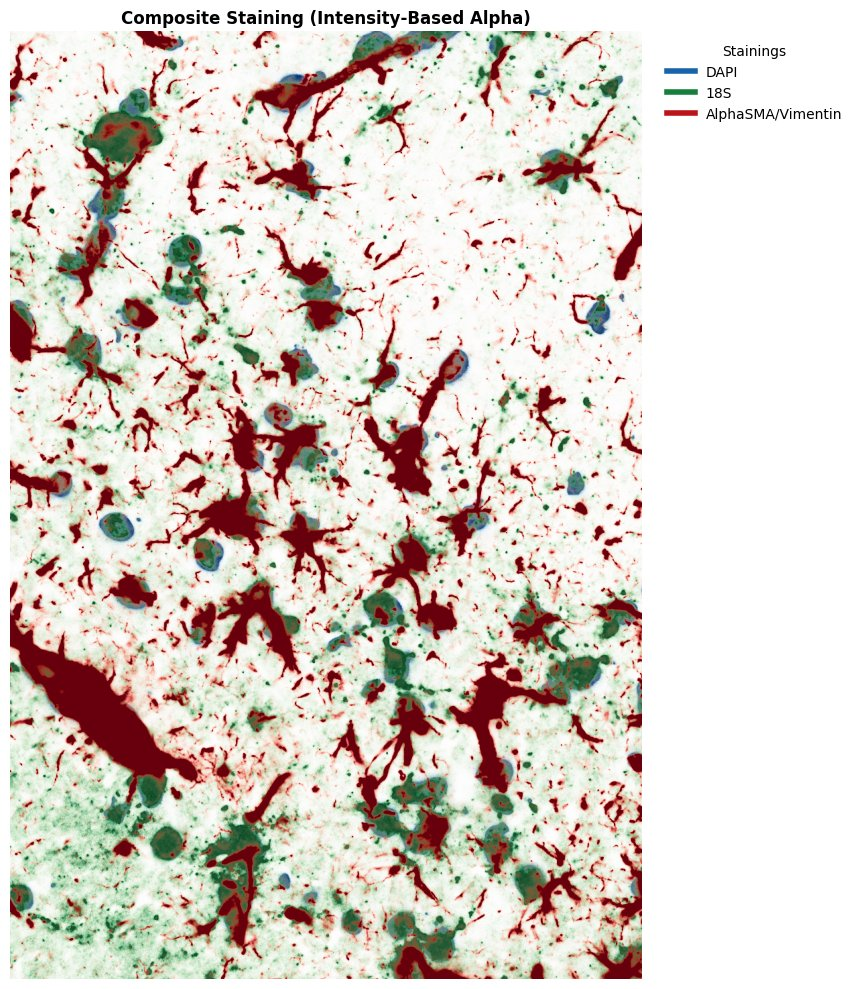

In [170]:
visualize_composite_staining_intensity_alpha(
    sdata=sdata,
    trans_df=transcripts_base_df,
    image_key="morphology_focus",
    scale_key="scale0",
    roi=(4900, 5100, 2100, 2400),
    figsize=(10, 10),
    include_channels=[0, 2, 3],               # Target array selection
    cmaps=['Blues', 'Greens', 'Reds'],        # 3 colormaps matching your 3 indices
    saving_path=saving_path,max_pct=90.0
)


=== [1/5] Transcript Global Ranges (Baseline calculation) ===

=== [2/5] Raw Image Metadata (Scale0) ===

=== [3/5] Scaling Factor Derivation ===

=== [4/5] Composite Processing (Filtering Selected Indices) ===
-> Actively plotting selected channels: ['DAPI', '18S', 'AlphaSMA/Vimentin'] (Indices: [0, 2, 3])

=== [5/5] Plotting Intensity-Alpha Blended Figure ===
-> Intensity-alpha composite PDF saved: staining_composite_channels_0_2_3_intensity_alpha_roi_4900_5100.pdf


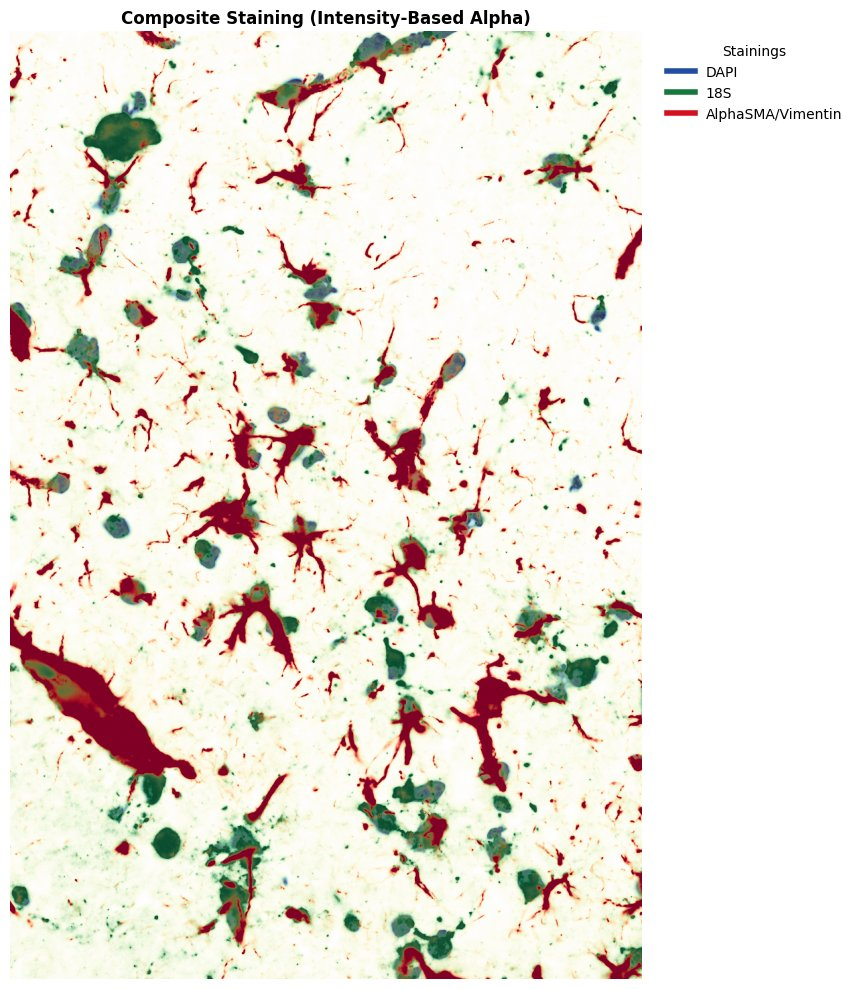

In [172]:
visualize_composite_staining_intensity_alpha(
    sdata=sdata,
    trans_df=transcripts_base_df,
    image_key="morphology_focus",
    scale_key="scale0",
    roi=(4900, 5100, 2100, 2400),
    figsize=(10, 10),
    include_channels=[0, 2, 3],               # Target array selection
    cmaps=['YlGnBu', 'YlGn', 'YlOrRd'],        # 3 colormaps matching your 3 indices
    saving_path=saving_path,max_pct=95.0
)


=== [1/5] Transcript Global Ranges (Baseline calculation) ===

=== [2/5] Raw Image Metadata (Scale0) ===

=== [3/5] Scaling Factor Derivation ===

=== [4/5] Composite Processing (Filtering Selected Indices) ===
-> Actively plotting selected channels: ['DAPI', '18S', 'AlphaSMA/Vimentin'] (Indices: [0, 2, 3])

=== [5/5] Plotting Intensity-Alpha Blended Figure ===
-> Intensity-alpha composite PDF saved: staining_composite_channels_0_2_3_intensity_alpha_roi_4900_5100.pdf


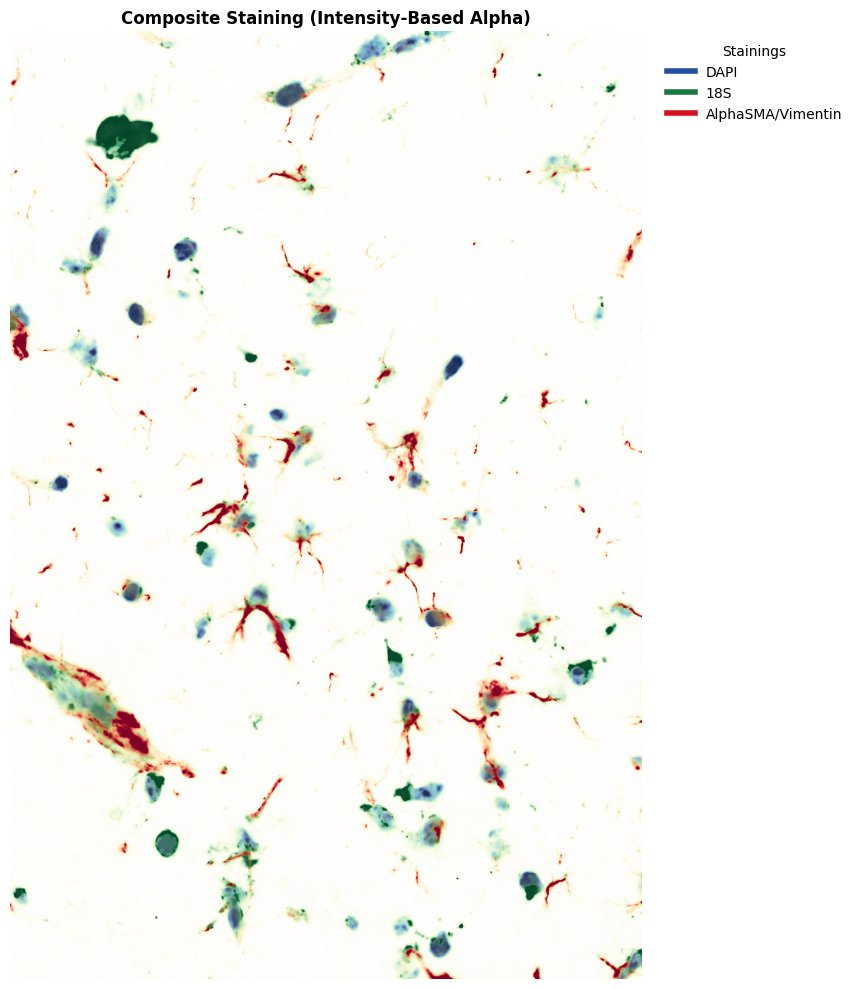

In [173]:
visualize_composite_staining_intensity_alpha(
    sdata=sdata,
    trans_df=transcripts_base_df,
    image_key="morphology_focus",
    scale_key="scale0",
    roi=(4900, 5100, 2100, 2400),
    figsize=(10, 10),
    include_channels=[0, 2, 3],               # Target array selection
    cmaps=['YlGnBu', 'YlGn', 'YlOrRd'],        # 3 colormaps matching your 3 indices
    saving_path=saving_path,max_pct=99.5
)

# Image structure quantification

In [30]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.ndimage import correlate

def analyze_channels_and_get_thresholds(
    sdata,
    image_key: str = "morphology_focus",
    scale_key: str = "scale0",
    roi: tuple[float, float, float, float] | None = None,
    saving_path: Path | str | None = None,
    step_size: int = 50,
    cmap: str = "gray",
    mode: str = "stringent"  # Options: "permissive", "standard", "stringent"
) -> pd.DataFrame:
    """
    Computes cumulative autocorrelation per channel, auto-detects thresholds based on
    the selected stringency mode, generates masks, and returns a summary DataFrame table.
    """
    print("\n=== STEP 1: Extracting XY Transcript Data ===")
    if 'transcripts' not in sdata.points:
        raise KeyError("The key 'transcripts' was not found in sdata.points.")
    
    trans_df = sdata.points['transcripts'][['x', 'y']].compute()
    t_xmin, t_xmax = trans_df['x'].min(), trans_df['x'].max()
    t_ymin, t_ymax = trans_df['y'].min(), trans_df['y'].max()
    t_dx = t_xmax - t_xmin
    t_dy = t_ymax - t_ymin

    print("\n=== STEP 2: Raw Image Matrix Dimensions ===")
    node = sdata.images[image_key][scale_key]
    img_data = node.image if hasattr(node, "image") else node
    img_shape = img_data.shape  
    img_w, img_h = img_shape[2], img_shape[1]

    print("\n=== STEP 3: Scaling Factor Derivation ===")
    scale_factor = ((img_w / t_dx) + (img_h / t_dy)) / 2

    if roi is not None:
        print("\n=== STEP 4: Target ROI Transformation ===")
        roi_xmin, roi_xmax, roi_ymin, roi_ymax = roi
        
        pixel_xmin = max(0, min(int(np.floor((roi_xmin - t_xmin) * scale_factor)), img_w))
        pixel_xmax = max(0, min(int(np.ceil((roi_xmax - t_xmin) * scale_factor)), img_w))
        pixel_ymin = max(0, min(int(np.floor((roi_ymin - t_ymin) * scale_factor)), img_h))
        pixel_ymax = max(0, min(int(np.ceil((roi_ymax - t_ymin) * scale_factor)), img_h))
        
        cropped_img = img_data[:, pixel_ymin:pixel_ymax, pixel_xmin:pixel_xmax]
    else:
        cropped_img = img_data
        roi_xmin, roi_xmax, roi_ymin, roi_ymax = t_xmin, t_xmax, t_ymin, t_ymax

    if "c" in cropped_img.coords:
        channel_names = [str(ch) for ch in cropped_img.coords["c"].values]
    else:
        channel_names = [f"Channel_{i}" for i in range(cropped_img.shape[0])]

    neighbor_kernel = np.array([[1, 1, 1],
                                [1, 0, 1],
                                [1, 1, 1]]) / 8.0
    total_pixels = cropped_img.shape[1] * cropped_img.shape[2]

    summary_data = []

    print("\n=== STEP 5: Cumulative Autocorrelation Engine ===")
    for idx, ch_name in enumerate(channel_names):
        channel_slice = cropped_img[idx, :, :].compute() if hasattr(cropped_img, "compute") else cropped_img[idx, :, :]
        img_np = np.asarray(channel_slice, dtype=np.float32)
        
        local_mean = correlate(img_np, neighbor_kernel, mode='constant', cval=0.0)
        flat_img = img_np.ravel()
        flat_mean = local_mean.ravel()
        
        max_intensity = int(np.ceil(flat_img.max()))
        upper_bounds = list(range(step_size, max_intensity + step_size, step_size))
        
        cumulative_correlations = []
        cumulative_pixel_percentages = []
        
        for max_val in upper_bounds:
            mask = (flat_img >= 0) & (flat_img <= max_val)
            pixel_count = np.sum(mask)
            cumulative_pixel_percentages.append((pixel_count / total_pixels) * 100)
            
            if pixel_count > 30:
                pixel_vals = flat_img[mask]
                neighbor_vals = flat_mean[mask]
                if np.std(pixel_vals) == 0 or np.std(neighbor_vals) == 0:
                    cumulative_correlations.append(0.0)
                else:
                    cumulative_correlations.append(np.corrcoef(pixel_vals, neighbor_vals)[0, 1])
            else:
                cumulative_correlations.append(np.nan)
        
        # ----------------------------------------------------
        # MULTI-MODE THRESHOLD FINDER
        # ----------------------------------------------------
        cumulative_correlations = np.array(cumulative_correlations)
        valid_idx = np.where(~np.isnan(cumulative_correlations))[0]
        
        if len(valid_idx) > 2:
            valley_idx = valid_idx[np.nanargmin(cumulative_correlations[valid_idx])]
            
            if mode == "permissive":
                # Matches early deceleration during background drop
                diffs = np.diff(cumulative_correlations)
                elbow_candidates = np.where(diffs > -0.04)[0]
                inflection_idx = valid_idx[elbow_candidates[0] + 1] if len(elbow_candidates) > 0 else valley_idx
                
            elif mode == "stringent":
                # HIGHER THRESHOLD: Look past the valley floor. 
                # Find where the curve begins its sharp upward surge into true structure.
                post_valley_idx = valid_idx[valid_idx >= valley_idx]
                if len(post_valley_idx) > 1:
                    # Look for the maximum upward acceleration step after the valley floor
                    diffs_post = np.diff(cumulative_correlations[post_valley_idx])
                    if len(diffs_post) > 0:
                        # Pick the step with the maximum upward change
                        inflection_idx = post_valley_idx[np.argmax(diffs_post) + 1]
                    else:
                        inflection_idx = post_valley_idx[-1]
                else:
                    # If the curve ends right at the valley floor, push it out manually by 2 steps
                    inflection_idx = min(valley_idx + 2, valid_idx[-1])
            
            else: # "standard" mode
                inflection_idx = valley_idx
                if inflection_idx == 0 and len(valid_idx) > 1:
                    diffs = np.diff(cumulative_correlations)
                    inflection_idx = np.where(diffs > -0.02)[0][0] + 1 if any(diffs > -0.02) else 1
            
            detected_threshold = upper_bounds[inflection_idx]
        else:
            detected_threshold = step_size
            
        # Calculate % of positive pixels
        positive_pixels_count = np.sum(img_np > detected_threshold)
        pct_positive_pixels = (positive_pixels_count / total_pixels) * 100
        
        summary_data.append({
            "Channel Name": ch_name,
            "Intensity Threshold": detected_threshold,
            "% Positive Pixels (Signal)": round(pct_positive_pixels, 2)
        })
        
        # ----------------------------------------------------
        # VISUALIZATION TRIPLE PANEL
        # ----------------------------------------------------
        fig, (ax_img, ax_corr, ax_mask) = plt.subplots(1, 3, figsize=(18, 5))
        extent = [roi_xmin, roi_xmax, roi_ymin, roi_ymax]
        
        ax_img.imshow(img_np, cmap=cmap, origin="lower", extent=extent)
        ax_img.set_title(f"{ch_name} - Raw Intensity", fontweight='bold', fontsize=11)
        ax_img.axis("off")
        
        color_corr = 'crimson'
        ax_corr.plot(upper_bounds, cumulative_correlations, marker='o', color=color_corr, linewidth=2, markersize=4, zorder=3)
        ax_corr.axvline(detected_threshold, color='darkgreen', linestyle='--', linewidth=2, label=f'{mode.capitalize()} Cutoff: {detected_threshold}')
        ax_corr.set_ylabel("Cumulative Spatial Correlation", color=color_corr, fontweight='bold')
        ax_corr.tick_params(axis='y', labelcolor=color_corr)
        ax_corr.set_xlabel("Upper Threshold Limit (X)")
        ax_corr.set_ylim(-0.05, 1.05)
        
        ax_perc = ax_corr.twinx()
        color_perc = 'navy'
        ax_perc.fill_between(upper_bounds, 0, cumulative_pixel_percentages, color=color_perc, alpha=0.08, zorder=1)
        ax_perc.set_ylabel("Total Pixels Included (%)", color=color_perc, fontweight='bold')
        ax_perc.tick_params(axis='y', labelcolor=color_perc)
        ax_corr.legend(loc='lower right')
        ax_corr.set_title("Autocorrelation Curve", fontweight='bold', fontsize=11)
        ax_corr.grid(True, linestyle=':', alpha=0.4)
        
        ax_mask.imshow(img_np > detected_threshold, cmap="gray", origin="lower", extent=extent)
        ax_mask.set_title(f"Stringent Mask (> {detected_threshold})\nCoverage: {pct_positive_pixels:.2f}%", fontweight='bold', fontsize=11, color='darkgreen')
        ax_mask.axis("off")
        
        plt.tight_layout()
        
        if saving_path is not None:
            save_dir = Path(saving_path)
            save_dir.mkdir(parents=True, exist_ok=True)
            roi_suffix = f"_roi_{int(roi_xmin)}_{int(roi_xmax)}"
            clean_ch_name = ch_name.replace(" ", "_").replace("/", "-")
            filename = f"stringent_analysis_{clean_ch_name}{roi_suffix}.png"
            fig.savefig(save_dir / filename, bbox_inches="tight", dpi=150)
            
        plt.show()
        plt.close(fig)

    df_summary = pd.DataFrame(summary_data)
    return df_summary


=== STEP 1: Extracting XY Transcript Data ===

=== STEP 2: Raw Image Matrix Dimensions ===

=== STEP 3: Scaling Factor Derivation ===

=== STEP 4: Target ROI Transformation ===

=== STEP 5: Cumulative Autocorrelation Engine ===


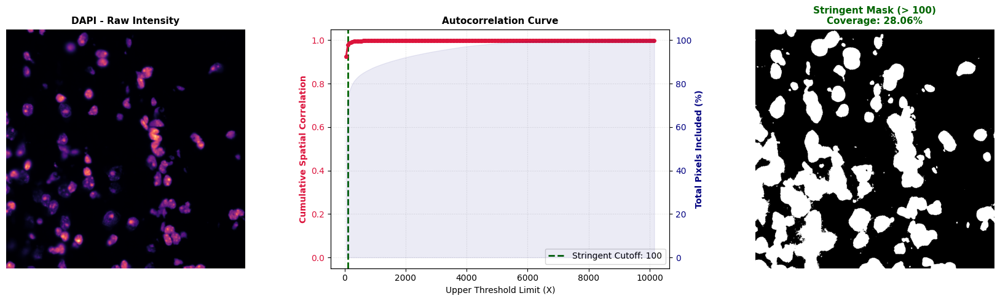

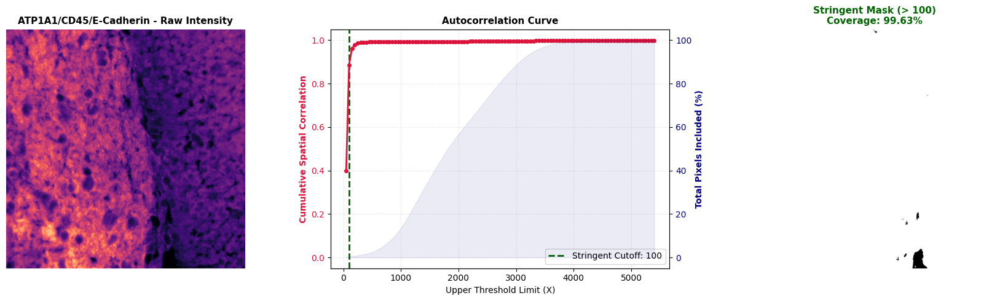

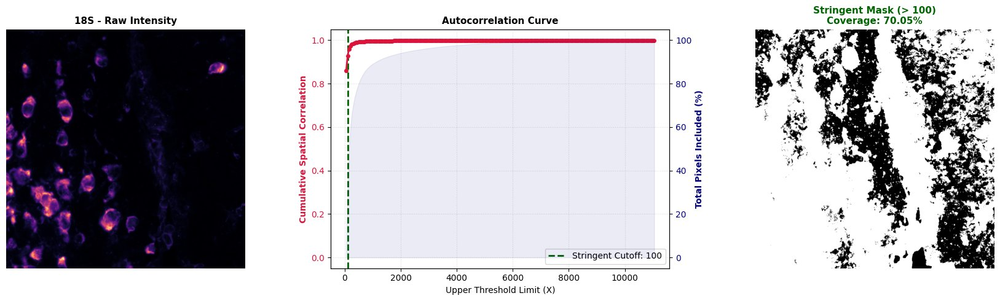

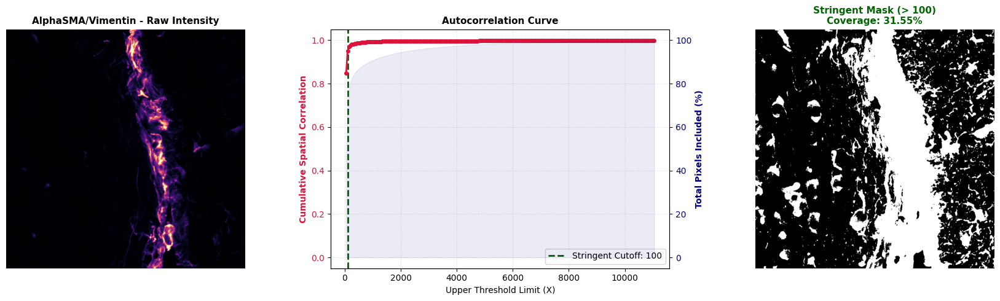

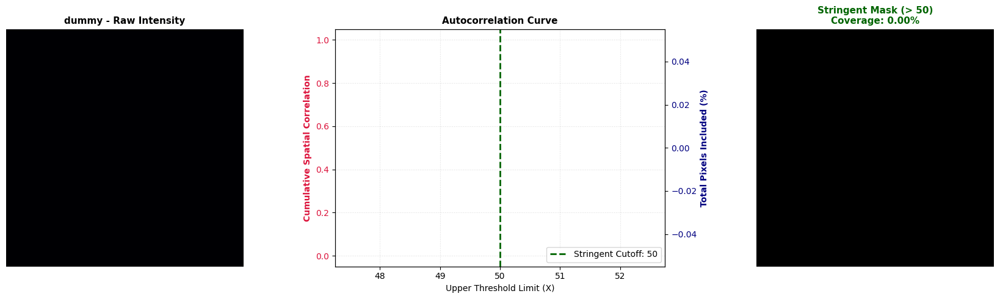

In [32]:
from pathlib import Path

# 1. Define where you want to save the diagnostic plots
# Change this path to wherever you want the output PNGs to land
# 2. Define your Region of Interest (ROI) using global transcript coordinates
# This 200x200 window is perfect for a fast, clear analysis
target_roi = (4500, 4700, 1100, 1300)

# 3. Call the cumulative function
df_summary=analyze_channels_and_get_thresholds(
    sdata=sdata,                         # Your main SpatialData object
    image_key="morphology_focus",        # The key to your morphology image
    scale_key="scale0",                  # 'scale0' for full resolution
    roi=target_roi,                      # Your spatial bounding window
    cmap="magma",                        # Perceptually uniform colormap
    saving_path=saving_path,             # Directory where plots will be saved
    step_size=50, mode="stringent"      # Calculates windows: 0->100, 0->200, 0->300, etc.
)

In [43]:
print(df_summary)

             Channel Name  Intensity Threshold  % Positive Pixels (Signal)
0                    DAPI                  100                       28.06
1  ATP1A1/CD45/E-Cadherin                  100                       99.63
2                     18S                  100                       70.05
3       AlphaSMA/Vimentin                  100                       31.55
4                   dummy                   50                        0.00


# Staining intensity vs composition
The point of this plot is to illustrate some transcripts have a certain enrichment in positive areas of certain stainings (in uRNA space)

In [133]:
import pandas as pd
import numpy as np

def compute_urna_percentages(sdata, df_summary, extracellular_key='extracellular', extracellular_value=True):
    # 1. Extract and compute the transcripts DataFrame efficiently
    transcripts_df = sdata['transcripts'][[extracellular_key, 'gene']].compute()
    transcripts_df.index = transcripts_df.index.astype(str)
    
    # Filter for target transcripts (e.g., extracellular == True or overlaps_cell == False)
    # properly mapping strings/booleans dynamically
    is_extracellular = transcripts_df[extracellular_key].astype(str).str.lower() == str(extracellular_value).lower()
    filtered_transcripts = transcripts_df[is_extracellular]
    
    # Compute global total number of uRNA for each gene
    # This serves as our denominator for df_values
    df_total_urna = filtered_transcripts.groupby('gene').size().to_frame(name='total_uRNA')
    
    # 2. Extract the AnnData info
    intensity_adata = sdata['image_intensity_per_transcript']
    channels = intensity_adata.var_names.tolist()
    
    if hasattr(intensity_adata.X, "toarray"):
        intensities_matrix = intensity_adata.X.toarray()
    else:
        intensities_matrix = intensity_adata.X
        
    intensities_df = pd.DataFrame(
        intensities_matrix, 
        index=intensity_adata.obs_names.astype(str), 
        columns=channels
    )
    
    # 3. Join the datasets based on the transcript index
    # We join on filtered_transcripts so we only track the relevant subset moving forward
    merged_df = filtered_transcripts.join(intensities_df, how='inner')
    
    # 4. Prepare the reference dictionary for thresholds
    threshold_dict = dict(zip(df_summary['Channel Name'], df_summary['Intensity Threshold']))
    
    # Initialize dictionary to collect raw counts
    freqs_dict = {}  
    unique_genes = merged_df['gene'].unique()
    
    # 5. Calculate absolute uRNA counts per channel
    for channel in channels:
        if channel not in threshold_dict:
            continue
            
        threshold = threshold_dict[channel]
        
        # Filter for rows where intensity exceeds the channel threshold
        is_positive_area = merged_df[channel] > threshold
        pos_df = merged_df[is_positive_area]
        
        # Count occurrences per gene within the positive zone
        urna_in_pos = pos_df.groupby('gene').size()
        
        # Save absolute counts
        freqs_dict[channel] = urna_in_pos
        
    # 6. Format into final DataFrames
    df_freqs = pd.DataFrame(freqs_dict, index=unique_genes).fillna(0)
    
    # Clean up total uRNA dataframe index to match unique_genes
    df_total_urna = df_total_urna.reindex(unique_genes).fillna(0)
    
    # --- DF_VALUES EVALUATION ---
    # Divide the local counts per channel by the global uRNA total for each gene
    df_values = df_freqs.div(df_total_urna['total_uRNA'], axis=0) * 100
    df_values = df_values.fillna(0)  # Handle any division-by-zero safely
    
    # Clean up index names and data types
    df_freqs.index.name = 'gene'
    df_values.index.name = 'gene'
    df_total_urna.index.name = 'gene'
    df_total_urna = df_total_urna.astype(int)
    
    return df_freqs, df_values, df_total_urna

In [137]:
df_freqs, df_values, df_total_urna = compute_urna_percentages(sdata, df_summary)

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

def filter_and_plot_urna(df_freqs, df_values, df_total_urna, n_counts=10, cmap='YlGnBu'):
    """
    Filters the precomputed uRNA dataframes based on a minimum global count threshold
    and generates a heatmap visualization.
    
    Parameters:
    - df_freqs: DataFrame of absolute uRNA counts per channel.
    - df_values: DataFrame of % of gene uRNA inside each channel.
    - df_total_urna: DataFrame of global total uRNA per gene.
    - n_counts: Minimum threshold of global uRNA counts required to keep a gene.
    - cmap: Colormap for the heatmap.
    
    Returns:
    - df_freqs_filtered, df_values_filtered, df_total_urna_filtered
    """
    # 1. Identify genes that meet the expression cutoff from the total counts
    passing_genes = df_total_urna[df_total_urna['total_uRNA'] >= n_counts].index
    
    # 2. Filter all 3 dataframes simultaneously using the passing genes
    df_freqs_filtered = df_freqs.loc[df_freqs.index.isin(passing_genes)]
    df_values_filtered = df_values.loc[df_values.index.isin(passing_genes)]
    df_total_urna_filtered = df_total_urna.loc[df_total_urna.index.isin(passing_genes)]
    
    print(f"--- Filtering Summary (Threshold: >= {n_counts} global counts) ---")
    print(f"Original unique genes: {len(df_total_urna)}")
    print(f"Genes matching criteria: {len(passing_genes)}")
    print(f"Filtered out: {len(df_total_urna) - len(passing_genes)} genes\n")
    
    if df_values_filtered.empty:
        print("Warning: The filtered DataFrame is empty. Try lowering n_counts.")
        return df_freqs_filtered, df_values_filtered, df_total_urna_filtered

    
    return df_freqs_filtered, df_values_filtered, df_total_urna_filtered


--- Filtering Summary (Threshold: >= 500 global counts) ---
Original unique genes: 13074
Genes matching criteria: 1970
Filtered out: 11104 genes



In [96]:
import numpy as np
import pandas as pd
import geopandas as gpd
from shapely.affinity import affine_transform

def compute_spatial_pixel_sharing(
    sdata, 
    df_summary, 
    image_key: str = "morphology_focus", 
    scale_key: str = "scale0", 
    shapes_key: str = "cell_boundaries"
):
    """
    Calculates the percentage of positive pixels inside vs outside cells 
    for each channel using a manual isotropic scaling transformation.
    """
    print("=== STEP 1: Transcript Global Ranges ===")
    trans_df = sdata['transcripts'][['x', 'y']].compute()
    t_xmin, t_xmax = trans_df['x'].min(), trans_df['x'].max()
    t_ymin, t_ymax = trans_df['y'].min(), trans_df['y'].max()
    
    t_dx = t_xmax - t_xmin
    t_dy = t_ymax - t_ymin
    print(f"Global Transcripts Bounds -> X: [{t_xmin:.2f} to {t_xmax:.2f}] (Delta: {t_dx:.2f})")
    print(f"Global Transcripts Bounds -> Y: [{t_ymin:.2f} to {t_ymax:.2f}] (Delta: {t_dy:.2f})")

    print("\n=== STEP 2: Raw Image Matrix Dimensions ===")
    node = sdata.images[image_key][scale_key]
    img_data = node.image if hasattr(node, "image") else node
    img_shape = img_data.shape  # Expecting (c, y, x)
    img_c, img_h, img_w = img_shape[0], img_shape[1], img_shape[2]
    print(f"Raw Image Shape (c, y, x): {img_shape}")

    print("\n=== STEP 3: Scaling Factor Derivation ===")
    # Calculate scale factor between the spatial bounding span vs the pixel canvas dimensions
    scale_x = img_w / t_dx
    scale_y = img_h / t_dy
    # Averaging to match identical proportional isotropic scaling
    scale_factor = (scale_x + scale_y) / 2
    print(f"Calculated Scale Factor (Pixels per Spatial Unit): {scale_factor:.5f}")

    print("\n=== STEP 4: Manual Geometry Transformation ===")
    # Load cell boundaries directly into a GeoDataFrame
    cb = sdata[shapes_key]
    gdf = gpd.GeoDataFrame(cb.copy(), geometry="geometry")

    # Mirror your manual transform matrix: Shift to 0,0 baseline and scale up to pixel grid
    # x_pixel = (x - t_xmin) * scale_factor
    # y_pixel = (y - t_ymin) * scale_factor
    # Affine matrix format: [a, b, d, e, xoff, yoff]
    pixel_matrix = [scale_factor, 0, 0, scale_factor, -t_xmin * scale_factor, -t_ymin * scale_factor]
    gdf['pixel_geometry'] = gdf['geometry'].apply(lambda g: affine_transform(g, pixel_matrix))

    print("\n=== STEP 5: Generating Binary Cell Mask ===")
    # Use OpenCV to rasterize the transformed polygons directly into a pixel grid
    import cv2
    cell_mask = np.zeros((img_h, img_w), dtype=np.uint8)
    
    for geom in gdf['pixel_geometry']:
        if geom.is_empty: 
            continue
        if geom.geom_type == 'Polygon':
            ext_coords = np.array(geom.exterior.coords, dtype=np.int32)
            cv2.fillPoly(cell_mask, [ext_coords], 1)
        elif geom.geom_type == 'MultiPolygon':
            for poly in geom.geoms:
                ext_coords = np.array(poly.exterior.coords, dtype=np.int32)
                cv2.fillPoly(cell_mask, [ext_coords], 1)

    # Total area metrics
    total_pixels_inside = np.sum(cell_mask == 1)
    total_pixels_outside = np.sum(cell_mask == 0)
    print(f"Cell Mask Generated -> Pixels Inside: {total_pixels_inside} | Pixels Outside: {total_pixels_outside}")

    # Extract existing channel coordinate markers
    if "c" in img_data.coords:
        channel_names = [str(ch) for ch in img_data.coords["c"].values]
    else:
        channel_names = [f"Channel_{i}" for i in range(img_c)]

    threshold_dict = dict(zip(df_summary['Channel Name'], df_summary['Intensity Threshold']))
    spatial_results = []

    print("\n=== STEP 6: Processing Channels and Computing Compartment Positivity ===")
    for idx, ch_name in enumerate(channel_names):
        if ch_name not in threshold_dict:
            continue
            
        threshold = threshold_dict[ch_name]
        
        # Pull single channel slice into memory safely
        channel_slice = img_data[idx, :, :].compute() if hasattr(img_data, "compute") else img_data[idx, :, :]
        img_np = np.asarray(channel_slice)
        
        # Calculate boolean mask of pixels strictly exceeding threshold
        pos_mask = img_np > threshold
        
        # Intersect threshold mask with cellular compartments
        pos_inside = np.sum((pos_mask == True) & (cell_mask == 1))
        pos_outside = np.sum((pos_mask == True) & (cell_mask == 0))
        
        # Calculate final percentages based on total available pixels in that compartment
        pct_inside = (pos_inside / total_pixels_inside) * 100 if total_pixels_inside > 0 else 0
        pct_outside = (pos_outside / total_pixels_outside) * 100 if total_pixels_outside > 0 else 0
        
        spatial_results.append({
            "Channel Name": ch_name,
            "Intensity Threshold": threshold,
            "% Positive Pixels (Inside Cells)": pct_inside,
            "% Positive Pixels (Outside Cells / Extracellular)": pct_outside
        })
        print(f"-> {ch_name}: Inside={pct_inside:.2f}%, Outside (Extracellular)={pct_outside:.2f}%")
        
    df_spatial_summary = pd.DataFrame(spatial_results)
    print("\n✓ Spatial threshold breakdown completed successfully.")
    return df_spatial_summary

In [ ]:
# Step 1: Run the new spatial compartment mask calculator
# This replaces your old df_summary with a version calculated only on extracellular space
df_spatial_summary = compute_spatial_pixel_sharing(
    sdata=sdata, 
    df_summary=df_summary,
    image_key="morphology_focus",  # Change if your image key is named differently
    scale_key="scale0",
    shapes_key="cell_boundaries"
)


In [141]:
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from shapely.affinity import affine_transform
import cv2

def compute_spatial_pixel_sharing_with_cell_like(
    sdata, 
    df_summary, 
    image_key: str = "morphology_focus", 
    scale_key: str = "scale0", 
    shapes_key: str = "cell_boundaries",
    extracellular_key: str = "extracellular",
    extracellular_value: bool = False,
    overlaps_cell_key: str = "overlaps_cell",
    overlaps_cell_value: bool = False,
    cell_like_dilation_radius: int = 15,
    show_viz: bool = True
):
    """
    Calculates the percentage of positive pixels across 3 compartments:
    Inside Cells, Cell-Like Regions (Unsegmented), and True Extracellular space.
    Includes a diagnostic visualization of the generated masks.
    """
    print("=== STEP 1: Transcript Global Ranges & Filtering ===")
    trans_df = sdata['transcripts'][['x', 'y', extracellular_key, overlaps_cell_key]].compute()
    trans_df.index = trans_df.index.astype(str)
    
    t_xmin, t_xmax = trans_df['x'].min(), trans_df['x'].max()
    t_ymin, t_ymax = trans_df['y'].min(), trans_df['y'].max()
    t_dx, t_dy = t_xmax - t_xmin, t_ymax - t_ymin

    print("\n=== STEP 2: Raw Image Matrix Dimensions ===")
    node = sdata.images[image_key][scale_key]
    img_data = node.image if hasattr(node, "image") else node
    img_shape = img_data.shape  # (c, y, x)
    img_c, img_h, img_w = img_shape[0], img_shape[1], img_shape[2]

    print("\n=== STEP 3: Scaling Factor Derivation ===")
    scale_factor = ((img_w / t_dx) + (img_h / t_dy)) / 2

    print("\n=== STEP 4: Creating Mask 1 - Inside Cells ===")
    cb = sdata[shapes_key]
    gdf = gpd.GeoDataFrame(cb.copy(), geometry="geometry")
    pixel_matrix = [scale_factor, 0, 0, scale_factor, -t_xmin * scale_factor, -t_ymin * scale_factor]
    gdf['pixel_geometry'] = gdf['geometry'].apply(lambda g: affine_transform(g, pixel_matrix))

    cell_mask = np.zeros((img_h, img_w), dtype=np.uint8)
    for geom in gdf['pixel_geometry']:
        if geom.is_empty: continue
        if geom.geom_type == 'Polygon':
            ext_coords = np.array(geom.exterior.coords, dtype=np.int32)
            cv2.fillPoly(cell_mask, [ext_coords], 1)
        elif geom.geom_type == 'MultiPolygon':
            for poly in geom.geoms:
                ext_coords = np.array(poly.exterior.coords, dtype=np.int32)
                cv2.fillPoly(cell_mask, [ext_coords], 1)

    print("\n=== STEP 5: Creating Mask 2 - Cell-Like Regions (From Transcripts) ===")
    # Filter using string-safe matching for whatever values you pass down
    is_extra_match = trans_df[extracellular_key].astype(str).str.lower() == str(extracellular_value).lower()
    is_cell_match = trans_df[overlaps_cell_key].astype(str).str.lower() == str(overlaps_cell_value).lower()
    
    cell_like_transcripts = trans_df[is_extra_match & is_cell_match]
    print(f"Found {len(cell_like_transcripts)} cell-like transcripts matching target criteria.")
    
    # Map points to pixel grid space
    cl_x_pixel = np.clip(((cell_like_transcripts['x'] - t_xmin) * scale_factor).astype(int), 0, img_w - 1)
    cl_y_pixel = np.clip(((cell_like_transcripts['y'] - t_ymin) * scale_factor).astype(int), 0, img_h - 1)
    
    # Rasterize points and dilate to form regional structural masks
    cell_like_mask = np.zeros((img_h, img_w), dtype=np.uint8)
    cell_like_mask[cl_y_pixel, cl_x_pixel] = 1
    
    if cell_like_dilation_radius > 0:
        kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (cell_like_dilation_radius, cell_like_dilation_radius))
        cell_like_mask = cv2.dilate(cell_like_mask, kernel)
    
    # Enforce priority rules (Segmented cell boundaries override cell-like transcripts)
    cell_like_mask[cell_mask == 1] = 0

    print("\n=== STEP 6: Creating Mask 3 - True Extracellular Space ===")
    true_extracellular_mask = np.where((cell_mask == 0) & (cell_like_mask == 0), 1, 0).astype(np.uint8)

    # Compute total area metrics per compartment
    total_inside = np.sum(cell_mask == 1)
    total_cell_like = np.sum(cell_like_mask == 1)
    total_true_extra = np.sum(true_extracellular_mask == 1)
    
    print(f"-> Compartment Areas (Pixels) | Inside Cells: {total_inside} | Cell-Like: {total_cell_like} | True Extracellular: {total_true_extra}")

    # --- Diagnostic Visualization ---
    if show_viz:
        print("\n=== Rendering Spatial Compartment Visualization ===")
        viz_map = np.zeros((img_h, img_w), dtype=np.uint8)
        viz_map[true_extracellular_mask == 1] = 0
        viz_map[cell_like_mask == 1] = 1
        viz_map[cell_mask == 1] = 2
        
        fig, ax = plt.subplots(figsize=(6, 6))
        cmap_custom = ListedColormap(['#ECEFF1', '#FFCC80', '#90CAF9'])  # Gray=Extra, Orange=Cell-Like, Blue=Inside Cell
        
        im = ax.imshow(viz_map, cmap=cmap_custom, origin='lower')
        ax.set_title("Generated Spatial Compartment Masks", fontweight='bold')
        ax.axis('off')
        
        cbar = plt.colorbar(im, ax=ax, ticks=[0.33, 1.0, 1.66], fraction=0.046, pad=0.04)
        cbar.ax.set_yticklabels(['True Extracellular', 'Cell-Like Region', 'Inside Cell'])
        plt.show()

    # --- Step 7: Signal Intensity Analysis ---
    if "c" in img_data.coords:
        channel_names = [str(ch) for ch in img_data.coords["c"].values]
    else:
        channel_names = [f"Channel_{i}" for i in range(img_c)]

    threshold_dict = dict(zip(df_summary['Channel Name'], df_summary['Intensity Threshold']))
    spatial_results = []

    print("\n=== STEP 7: Processing Channels and Computing Compartment Positivity ===")
    for idx, ch_name in enumerate(channel_names):
        if ch_name not in threshold_dict:
            continue
            
        threshold = threshold_dict[ch_name]
        channel_slice = img_data[idx, :, :].compute() if hasattr(img_data, "compute") else img_data[idx, :, :]
        img_np = np.asarray(channel_slice)
        
        pos_mask = img_np > threshold
        
        pos_inside = np.sum((pos_mask == True) & (cell_mask == 1))
        pos_cell_like = np.sum((pos_mask == True) & (cell_like_mask == 1))
        pos_true_extra = np.sum((pos_mask == True) & (true_extracellular_mask == 1))
        
        pct_inside = (pos_inside / total_inside) * 100 if total_inside > 0 else 0
        pct_cell_like = (pos_cell_like / total_cell_like) * 100 if total_cell_like > 0 else 0
        pct_true_extra = (pos_true_extra / total_true_extra) * 100 if total_true_extra > 0 else 0
        
        spatial_results.append({
            "Channel Name": ch_name,
            "Intensity Threshold": threshold,
            "% Positive Pixels (Inside Cells)": pct_inside,
            "% Positive Pixels (Cell-Like Regions)": pct_cell_like,
            "% Positive Pixels (True Extracellular)": pct_true_extra
        })
        print(f"-> {ch_name}: Inside={pct_inside:.1f}% | Cell-Like={pct_cell_like:.1f}% | True Extra={pct_true_extra:.1f}%")
        
    return pd.DataFrame(spatial_results)

=== STEP 1: Transcript Global Ranges & Filtering ===

=== STEP 2: Raw Image Matrix Dimensions ===

=== STEP 3: Scaling Factor Derivation ===

=== STEP 4: Creating Mask 1 - Inside Cells ===

=== STEP 5: Creating Mask 2 - Cell-Like Regions (From Transcripts) ===
Found 2597144 cell-like transcripts matching target criteria.

=== STEP 6: Creating Mask 3 - True Extracellular Space ===
-> Compartment Areas (Pixels) | Inside Cells: 16994595 | Cell-Like: 1968849 | True Extracellular: 55892256

=== Rendering Spatial Compartment Visualization ===


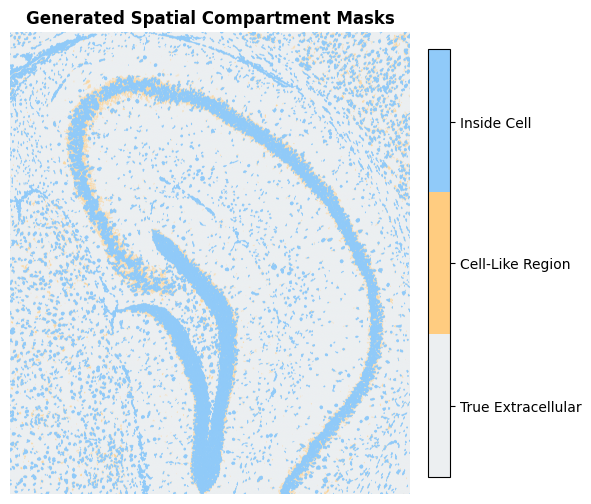


=== STEP 7: Processing Channels and Computing Compartment Positivity ===
-> DAPI: Inside=95.0% | Cell-Like=50.0% | True Extra=7.1%
-> ATP1A1/CD45/E-Cadherin: Inside=100.0% | Cell-Like=100.0% | True Extra=99.8%
-> 18S: Inside=98.5% | Cell-Like=99.4% | True Extra=52.4%
-> AlphaSMA/Vimentin: Inside=41.6% | Cell-Like=17.6% | True Extra=10.9%
-> dummy: Inside=0.0% | Cell-Like=0.0% | True Extra=0.0%


In [143]:
df_spatial_summary = compute_spatial_pixel_sharing_with_cell_like(
    sdata=sdata,
    df_summary=df_summary,
    image_key="morphology_focus",
    shapes_key="cell_boundaries",
    extracellular_key="extracellular",
    extracellular_value=False,
    overlaps_cell_key="overlaps_cell",
    overlaps_cell_value=False,
    cell_like_dilation_radius=0,  # Radius in pixels to grow around unsegmented transcripts
    show_viz=True
)

In [148]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

def plot_spatial_compartment_summary(df_spatial_summary: pd.DataFrame, title: str = "Signal Positivity Across Spatial Compartments"):
    """
    Creates a grouped bar chart visualizing the percentage of positive pixels 
    across Inside Cells, Cell-Like Regions, and True Extracellular space.
    """
    # 1. Melt the DataFrame from wide to long format for Seaborn compatibility
    melt_cols = [
        "% Positive Pixels (Inside Cells)", 
        "% Positive Pixels (Cell-Like Regions)", 
        "% Positive Pixels (True Extracellular)"
    ]
    
    # Ensure columns exist before melting
    available_cols = [col for col in melt_cols if col in df_spatial_summary.columns]
    
    df_long = df_spatial_summary.melt(
        id_vars=["Channel Name"], 
        value_vars=available_cols,
        var_name="Compartment", 
        value_name="Percent Positive Pixels"
    )
    
    # 2. Clean up the legend labels for display readability
    df_long["Compartment"] = df_long["Compartment"].str.extract(r"\((.*?)\)")

    # 3. Initialize the plot
    fig, ax = plt.subplots(figsize=(10, 5))
    
    # Use an elegant color scheme matching the spatial mask visualization palette
    palette_dict = {
        "Inside Cells": "#90CAF9",          # Blue
        "Cell-Like Regions": "#FFCC80",     # Orange
        "True Extracellular": "#90A4AE"     # Muted Gray-Blue
    }
    
    sns.barplot(
        data=df_long, 
        x="Channel Name", 
        y="Percent Positive Pixels", 
        hue="Compartment", 
        palette=palette_dict,
        edgecolor="black",
        linewidth=0.7,
        ax=ax
    )
    
    # 4. Refine structural aesthetics
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.set_axisbelow(True)
    ax.grid(axis='y', linestyle='--', alpha=0.5, zorder=0)
    
    # Titles and Label refinement
    ax.set_title(title, fontsize=14, fontweight="bold", pad=15)
    ax.set_xlabel("Imaging Channels", fontsize=12, labelpad=10)
    ax.set_ylabel("% Area Exceeding Threshold", fontsize=12, labelpad=10)
    
    # Keep the bounds locked inside normal percentages
    ax.set_ylim(0, max(df_long["Percent Positive Pixels"].max() * 1.15, 10))
    
    # Finalize Layout layout
    plt.legend(frameon=False, loc="upper right", title="Compartment")
    plt.tight_layout()
    plt.show()

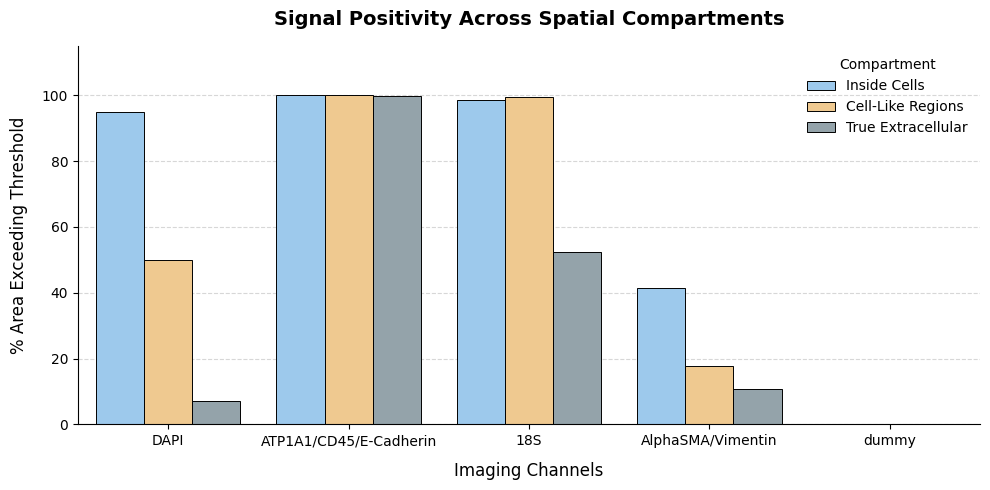

In [149]:
plot_spatial_compartment_summary(df_spatial_summary)

In [158]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from adjustText import adjust_text

def metric_scatter_extracellular(
    df_values: pd.DataFrame,
    df_spatial_summary: pd.DataFrame,
    x: str,
    y: str,
    x_baselines: list[str] = ["% Positive Pixels (True Extracellular)"],
    y_baselines: list[str] = ["% Positive Pixels (True Extracellular)"],
    size: int = 15,
    label_top_n_x: int = 0,
    label_top_n_y: int = 0,
    label_bottom_n_x: int = 0,
    label_bottom_n_y: int = 0,
    title: str | None = None,
    linewidth: float = 0.5,
    figures_path: str = "",
    save: bool = False,
    custom_plot_filename: str = None,
    dot_color: str = "#1E90FF",
    gene_label: str = "Gene probes",
) -> None:
    """
    Creates a scatter plot comparing uRNA percentages of two specified channels (x and y).
    Draws custom horizontal and vertical lines indicating expected random positivity thresholds
    for multiple specified compartments from df_spatial_summary.
    """
    # --- Illustrator Editability Settings ---
    mpl.rcParams['pdf.fonttype'] = 42  
    mpl.rcParams['ps.fonttype'] = 42   

    # 1. Clean and isolate data from the metrics matrix (df_values)
    if x not in df_values.columns or y not in df_values.columns:
        raise ValueError(f"Ensure both axis channels '{x}' and '{y}' exist as columns in df_values.")
        
    plot_df = df_values[[x, y]].copy()
    plot_df.dropna(subset=[x, y], inplace=True)

    # 2. Build the plot setup
    fig, ax = plt.subplots(figsize=(6, 6))
    
    ax.scatter(
        plot_df[x], plot_df[y], 
        color=dot_color, 
        edgecolor="black", 
        s=size, 
        linewidth=linewidth, 
        alpha=0.9,
        zorder=5  # Keep dots on top of all lines
    )

    # Clean up spines
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    # Filter spatial summary for the target channels
    x_summary = df_spatial_summary[df_spatial_summary['Channel Name'] == x]
    y_summary = df_spatial_summary[df_spatial_summary['Channel Name'] == y]

    # Assign distinct colors and styles if plotting multiple distinct compartment lines
    # Order matches: True Extracellular, Cell-Like Regions, Inside Cells
    style_palette = {
        "% Positive Pixels (True Extracellular)": {"color": "#DC143C", "ls": "--", "label": "True Extra"},
        "% Positive Pixels (Cell-Like Regions)": {"color": "#FF8C00", "ls": "-.", "label": "Cell-Like"},
        "% Positive Pixels (Inside Cells)": {"color": "#4169E1", "ls": ":", "label": "Inside Cell"}
    }
    
    # Track values to safely expand the plot limits later
    all_baseline_x_vals = []
    all_baseline_y_vals = []
    used_labels = set()

    # 3. Draw requested vertical lines (X-axis channels)
    if not x_summary.empty:
        for col in x_baselines:
            if col in x_summary.columns:
                val = x_summary[col].values[0]
                all_baseline_x_vals.append(val)
                style = style_palette.get(col, {"color": "#7F8C8D", "ls": "--", "label": col})
                ax.axvline(x=val, color=style["color"], linestyle=style["ls"], linewidth=1.2, zorder=2)
                used_labels.add((style["color"], style["ls"], f"{style['label']} Baseline"))

    # 4. Draw requested horizontal lines (Y-axis channels)
    if not y_summary.empty:
        for col in y_baselines:
            if col in y_summary.columns:
                val = y_summary[col].values[0]
                all_baseline_y_vals.append(val)
                style = style_palette.get(col, {"color": "#7F8C8D", "ls": "--", "label": col})
                ax.axhline(y=val, color=style["color"], linestyle=style["ls"], linewidth=1.2, zorder=2)
                used_labels.add((style["color"], style["ls"], f"{style['label']} Baseline"))

    # 5. Label Handling
    label_genes = set()
    if label_top_n_x > 0:
        label_genes.update(plot_df.nlargest(label_top_n_x, x).index)
    if label_top_n_y > 0:
        label_genes.update(plot_df.nlargest(label_top_n_y, y).index)
    if label_bottom_n_x > 0:
        label_genes.update(plot_df.nsmallest(label_bottom_n_x, x).index)
    if label_bottom_n_y > 0:
        label_genes.update(plot_df.nsmallest(label_bottom_n_y, y).index)

    texts = []
    for gene in label_genes:
        texts.append(
            ax.text(plot_df.loc[gene, x], plot_df.loc[gene, y], gene, fontsize=11, ha="right")
        )

    # 6. Graph limit bounding with dynamic baseline safe-padding
    x_min, x_max = plot_df[x].min(), plot_df[x].max()
    y_min, y_max = plot_df[y].min(), plot_df[y].max()
    
    if all_baseline_x_vals:
        x_min = min(x_min, min(all_baseline_x_vals))
        x_max = max(x_max, max(all_baseline_x_vals))
    if all_baseline_y_vals:
        y_min = min(y_min, min(all_baseline_y_vals))
        y_max = max(y_max, max(all_baseline_y_vals))

    x_padding = max((x_max - x_min) * 0.1, 5)
    y_padding = max((y_max - y_min) * 0.1, 5)

    ax.set_xlim(max(0, x_min - x_padding), min(105, x_max + x_padding))
    ax.set_ylim(max(0, y_min - y_padding), min(105, y_max + y_padding))

    if texts:
        adjust_text(texts, arrowprops={"arrowstyle": "-", "color": "black", "lw": 1})

    # 7. Label assignments
    ax.set_xlabel(f"{x.replace('_', ' ').title()} (% uRNA Positivity)", fontsize=12)
    ax.set_ylabel(f"{y.replace('_', ' ').title()} (% uRNA Positivity)", fontsize=12)

    if title:
        ax.set_title(title, fontsize=14, fontweight="bold")

    # 8. Dynamic Legend Generation
    legend_elements = [
        Line2D([0], [0], marker="o", color="w", label=gene_label, markerfacecolor=dot_color, markeredgecolor="black", markersize=8)
    ]
    for color, ls, lbl in sorted(used_labels, key=lambda item: item[2]):
        legend_elements.append(Line2D([0], [0], color=color, linestyle=ls, linewidth=1.2, label=lbl))
        
    ax.legend(handles=legend_elements, loc="best", frameon=False)
    ax.tick_params(labelsize=10)

    if save:
        fig_dir = Path(figures_path)
        fig_dir.mkdir(parents=True, exist_ok=True)
        plot_filename = custom_plot_filename or f"{x}_vs_{y}_compartments_scatter.pdf"
        plt.savefig(fig_dir / plot_filename, bbox_inches="tight")

    plt.show()

In [170]:
selgenes=sdata['xrna_metadata'].var[sdata['xrna_metadata'].var['logfoldchange_over_noise']>6].index
df_v=df_values[df_values.index.isin(selgenes)]
print(df_v.shape)

(474, 5)


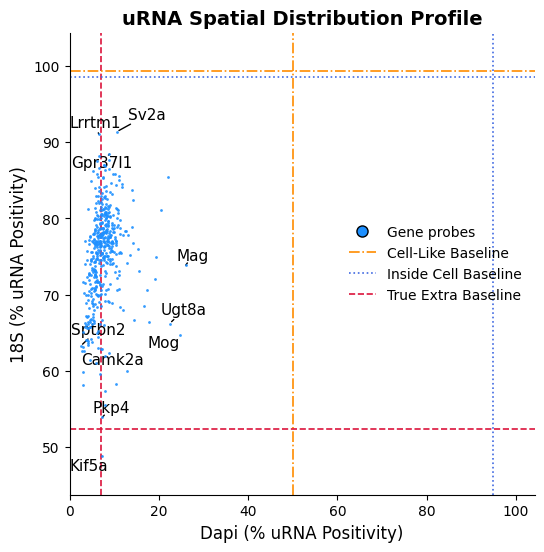

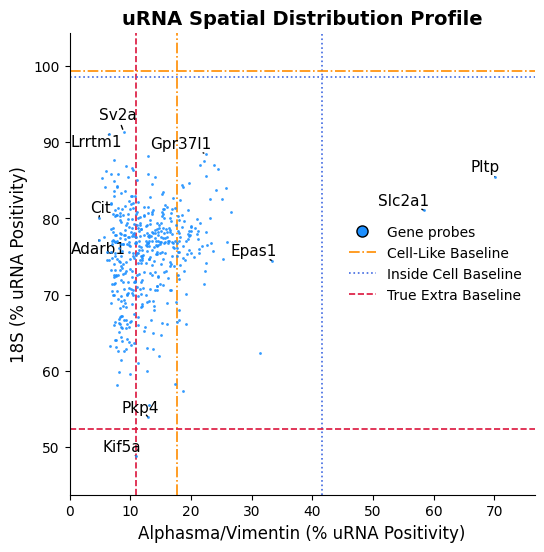

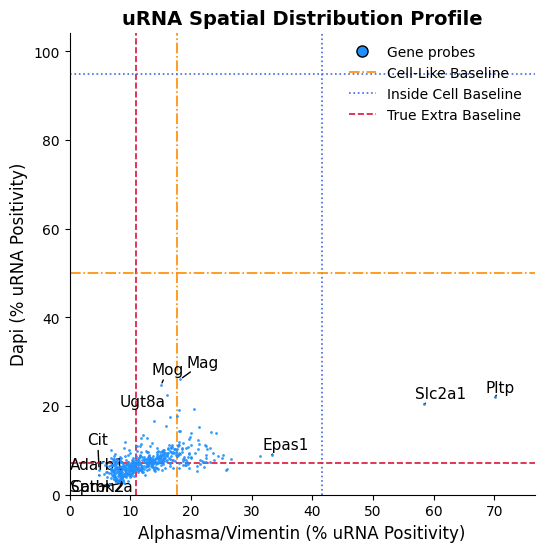

In [171]:
metric_scatter_extracellular( df_values=df_v,
    df_spatial_summary=df_spatial_summary,x_baselines= [ '% Positive Pixels (Inside Cells)',
       '% Positive Pixels (Cell-Like Regions)',
       '% Positive Pixels (True Extracellular)'],y_baselines= [ '% Positive Pixels (Inside Cells)',
       '% Positive Pixels (Cell-Like Regions)',
       '% Positive Pixels (True Extracellular)'],
    x='DAPI', y='18S', label_top_n_x=3,linewidth=0.0, label_top_n_y=3,size=4,label_bottom_n_x=2,label_bottom_n_y=2,
    title="uRNA Spatial Distribution Profile")

metric_scatter_extracellular(
    df_values=df_v,df_spatial_summary=df_spatial_summary,
    x='AlphaSMA/Vimentin', y='18S',x_baselines= [ '% Positive Pixels (Inside Cells)',
       '% Positive Pixels (Cell-Like Regions)',
       '% Positive Pixels (True Extracellular)'],y_baselines= [ '% Positive Pixels (Inside Cells)',
       '% Positive Pixels (Cell-Like Regions)',
       '% Positive Pixels (True Extracellular)'],
    label_top_n_x=3,linewidth=0.0, label_top_n_y=3,size=4,label_bottom_n_x=2,label_bottom_n_y=2,
    title="uRNA Spatial Distribution Profile")

metric_scatter_extracellular(
    df_values=df_v,df_spatial_summary=df_spatial_summary,x_baselines= [ '% Positive Pixels (Inside Cells)',
       '% Positive Pixels (Cell-Like Regions)',
       '% Positive Pixels (True Extracellular)'],y_baselines= [ '% Positive Pixels (Inside Cells)',
       '% Positive Pixels (Cell-Like Regions)',
       '% Positive Pixels (True Extracellular)'],
    x='AlphaSMA/Vimentin', y='DAPI',
    label_top_n_x=3,linewidth=0.0, label_top_n_y=3,size=4,label_bottom_n_x=2,label_bottom_n_y=2,
    title="uRNA Spatial Distribution Profile")

(<Figure size 800x800 with 1 Axes>,
 <Axes: title={'center': 'Cell Boundaries + Transcripts'}>)

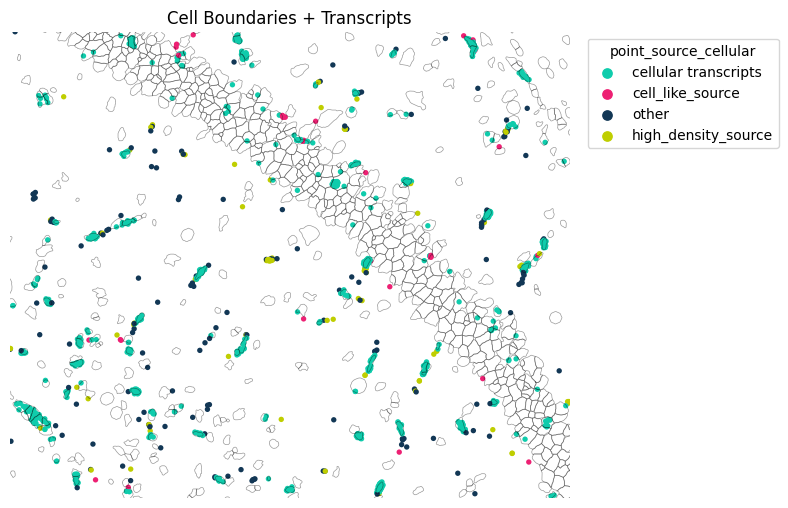

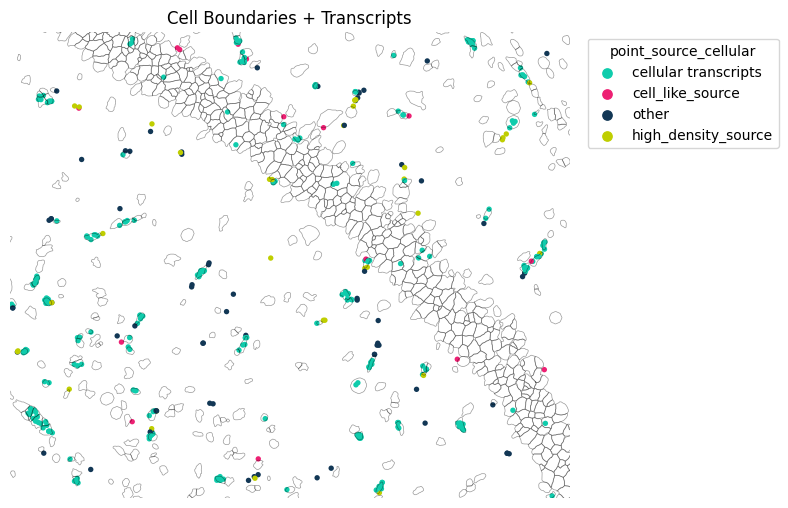

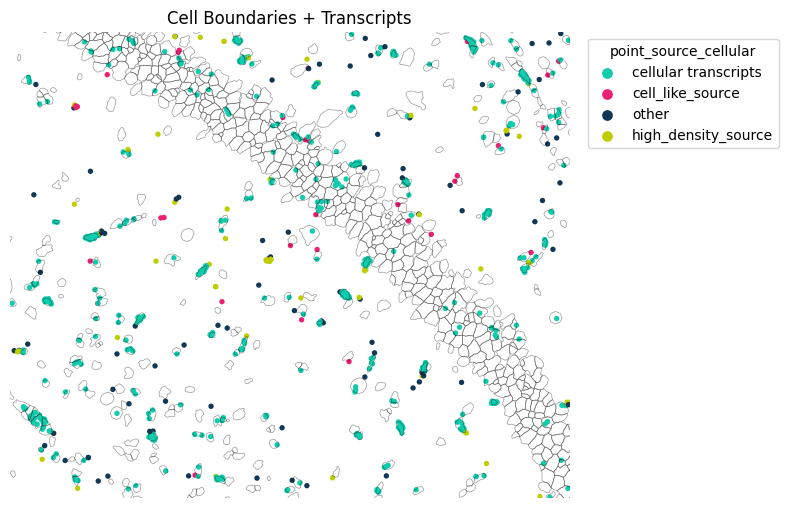

In [172]:
pl.spatial_transcripts(sdata,gene_list=['Pltp'],use_roi=True, roi=(4900, 5500, 2100, 2600),scatter_size=10)
pl.spatial_transcripts(sdata,gene_list=['Flt1'],use_roi=True, roi=(4900, 5500, 2100, 2600),scatter_size=10)
pl.spatial_transcripts(sdata,gene_list=['Slc2a1'],use_roi=True, roi=(4900, 5500, 2100, 2600),scatter_size=10)

# 2. Density analysis

Successfully calculated all proportions. Isolated 20 extreme genes sorted by 'High Density' content.


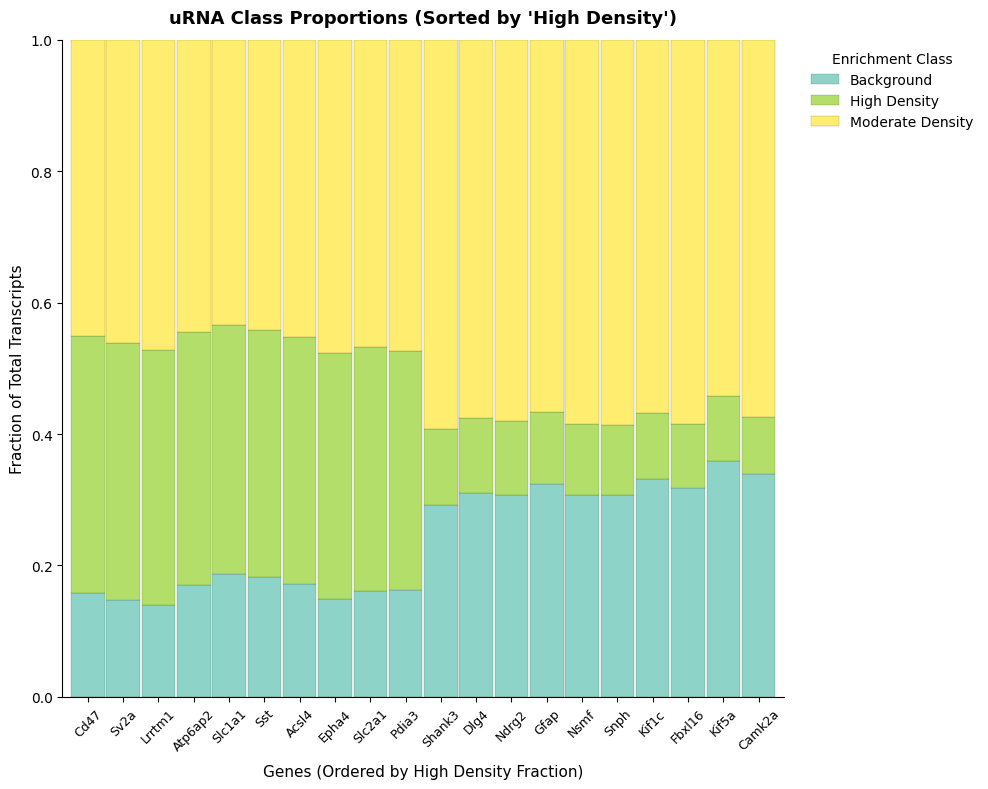

In [198]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ==============================================================================
# 1. CALCULATE PROPORTIONS FOR ALL GENES FIRST
# ==============================================================================

# Extract the high-confidence genes from your metadata filter
selgenes = sdata['xrna_metadata'].var[sdata['xrna_metadata'].var['logfoldchange_over_noise'] > 6].index

# Load transcript attributes into memory including enrichment_class
trans = sdata['transcripts'][['gene', 'enrichment_class', 'extracellular']].compute()
trans.index = trans.index.astype(str)

# Filter down to your selected candidate genes and pull extracellular compartment only
trans_filtered = trans[trans['gene'].isin(selgenes)].copy()
is_extra_mask = trans_filtered['extracellular'].astype(str).str.lower() == 'true'
extracellular_transcripts = trans_filtered[is_extra_mask].copy()

# Count transcripts per gene to filter out background noise or ultra-low-count genes
gene_counts = extracellular_transcripts['gene'].value_counts()
valid_genes = gene_counts[gene_counts >= 5].index  # Requires at least 5 raw transcripts
extracellular_transcripts = extracellular_transcripts[extracellular_transcripts['gene'].isin(valid_genes)]

# Calculate raw counts of transcripts per enrichment class for ALL valid genes
all_counts_df = extracellular_transcripts.groupby(['gene', 'enrichment_class']).size().unstack(fill_value=0)

# Normalize across rows to get the precise uRNA proportion (0.0 to 1.0) for ALL genes
all_proportions_df = all_counts_df.div(all_counts_df.sum(axis=1), axis=0)

# ==============================================================================
# 2. FILTER GENES FOR VIZ BASED ON "High density" PROPORTION
# ==============================================================================

# Target class string (adjust capitalization if your class is 'High Density' or similar)
target_class = "High Density" 

if target_class not in all_proportions_df.columns:
    available_classes = list(all_proportions_df.columns)
    raise KeyError(f"'{target_class}' not found in enrichment classes. Available options are: {available_classes}")

# Extract the ranking series specifically for the target class
high_density_ranking = all_proportions_df[target_class]

# Isolate the top 10 and bottom 10 genes based on this specific proportion
top_10_genes = high_density_ranking.nlargest(10).index.tolist()
bottom_10_genes = high_density_ranking.nsmallest(10).index.tolist()
selected_display_genes = top_10_genes + bottom_10_genes

# Create the final visualization dataframe containing just these 20 extreme genes
proportion_df = all_proportions_df.reindex(selected_display_genes)

# Sort the final dataframe from highest "High density" fraction to lowest
sorted_order = high_density_ranking.loc[selected_display_genes].sort_values(ascending=False).index
proportion_df = proportion_df.reindex(sorted_order)

print(f"Successfully calculated all proportions. Isolated {len(proportion_df)} extreme genes sorted by '{target_class}' content.")

# ==============================================================================
# 3. GENERATE DUAL COMPARTMENT CLASS VISUALIZATIONS
# ==============================================================================

# Create a single panel subplot - 'axes' is a single object, not a list
fig, axes = plt.subplots(1, 1, figsize=(10, 8))

# --- PANEL A: 100% Stacked Bar Plot ---
proportion_df.plot(
    kind='bar', 
    stacked=True, 
    cmap='Set3', 
    edgecolor='black', 
    linewidth=0.1,
    width=0.95,
    ax=axes  # Explicitly tell pandas to draw inside your 10x8 figure
)

# Use 'axes' directly instead of 'axes[0]'
axes.set_title(f"uRNA Class Proportions (Sorted by '{target_class}')", fontweight='bold', fontsize=13, pad=12)
axes.set_xlabel("Genes (Ordered by High Density Fraction)", fontsize=11, labelpad=8)
axes.set_ylabel("Fraction of Total Transcripts", fontsize=11)
axes.tick_params(axis='x', rotation=45, labelsize=9)
axes.set_ylim(0, 1.0)
axes.spines['top'].set_visible(False)
axes.spines['right'].set_visible(False)

# Place legend cleanly next to the single plot panel
axes.legend(title="Enrichment Class", frameon=False, loc="upper left", bbox_to_anchor=(1.02, 1.0))

plt.tight_layout()
plt.show()

# 3. Fragment analysis
We next focus on expoloring the high density structures, divided into fragments

In [211]:
adata=sdata['structure_table'].copy()

In [212]:
import pandas as pd

# Extract the transcript counts series
vals = adata.obs['n_transcripts']

# Define the bin edges and corresponding labels
# Since bins are right-inclusive by default (e.g., (-1, 1] includes 0 and 1):
bins = [-1, 1, 5, 20, 100, 1000, float('inf')]
labels = ['0-1', '2-5', '5-20', '20-100', '100-1000', '1000+']

# Compute the counts per bin
counts = pd.cut(vals, bins=bins, labels=labels).value_counts()
print(counts)

n_transcripts
2-5         14360
0-1         10673
5-20         8631
20-100       3575
100-1000     1791
1000+         228
Name: count, dtype: int64


First we visualize structures

In [238]:
sdata['transcripts']['structure_id'].compute()

0           0
1          -1
2          -1
3          -1
4          -1
           ..
23790751    4
23790752   -1
23790753   -1
23790754   -1
23790755   -1
Name: structure_id, Length: 23790756, dtype: int64

(<Figure size 800x800 with 1 Axes>,
 <Axes: title={'center': 'Cell Boundaries + Transcripts'}>)

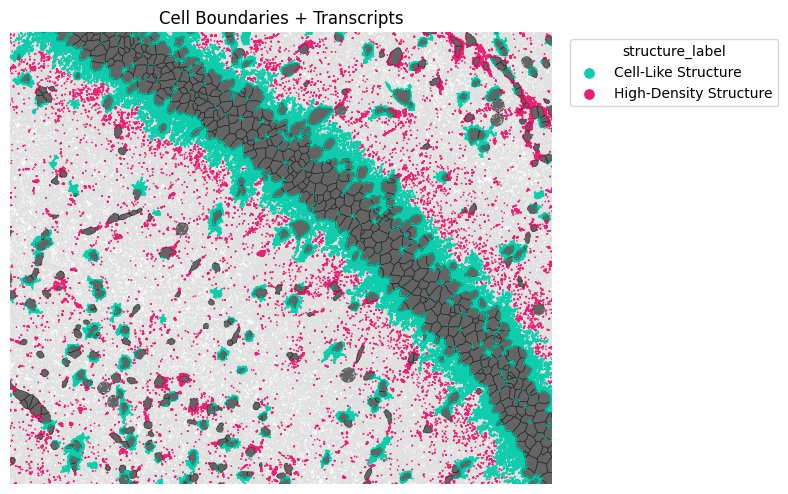

In [220]:
pl.spatial_transcripts(sdata,color_key='structure_label',use_roi=True, roi=(4900, 5500, 2100, 2600),scatter_size=1)

(<Figure size 800x800 with 1 Axes>,
 <Axes: title={'center': 'Cell Boundaries + Transcripts'}>)

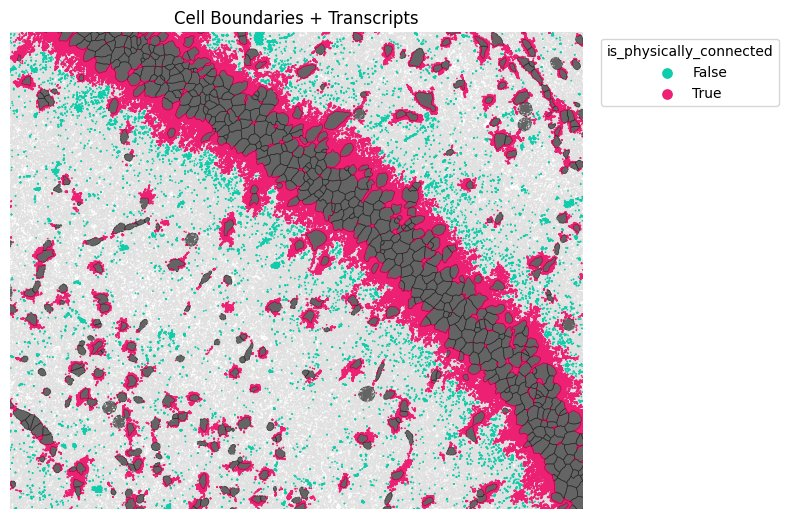

In [223]:
pl.spatial_transcripts(sdata,color_key='is_physically_connected',use_roi=True, roi=(4900, 5500, 2100, 2600),scatter_size=1)

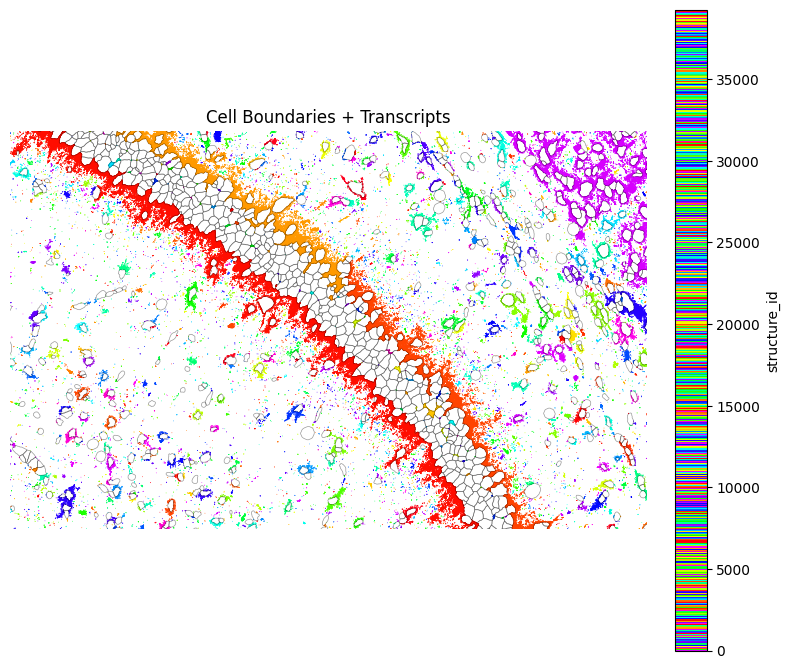

In [ ]:
unique_ids = sdata['structure_table'].obs.index.unique()
num_structures = len(unique_ids)

# Generate and shuffle base random colors
base_colors = plt.cm.gist_rainbow(np.linspace(0, 1, num_structures))
np.random.seed(42)
np.random.shuffle(base_colors)
random_structure_cmap = ListedColormap(base_colors)

# Execute updated plotting framework
fig, ax = spatial_transcripts(
    sdata,
    color_key="structure_id",       
    colormap=random_structure_cmap,  
    scatter_size=0.2,use_roi=True, roi=(4900, 5700, 2100, 2600),
    alpha=1, # Adjust opacity of the unmapped grey points easily
    rasterize=True,missing_val_sentinel=-1
)

plt.show()

In [ ]:
unique_ids = sdata['structure_table'].obs.index.unique()
num_structures = len(unique_ids)

# Generate and shuffle base random colors
base_colors = plt.cm.gist_rainbow(np.linspace(0, 1, num_structures))
np.random.seed(42)
np.random.shuffle(base_colors)
random_structure_cmap = ListedColormap(base_colors)

# Execute updated plotting framework
fig, ax = spatial_transcripts(
    sdata,
    color_key="predicted_parent_leiden",       
    colormap=random_structure_cmap,  
    scatter_size=0.2,use_roi=True, roi=(4900, 5700, 2100, 2600),
    alpha=1, # Adjust opacity of the unmapped grey points easily
    rasterize=True,missing_val_sentinel=-1
)

plt.show()

It seems you use rank_genes_groups on the raw count data. Please logarithmize your data before calling rank_genes_groups.


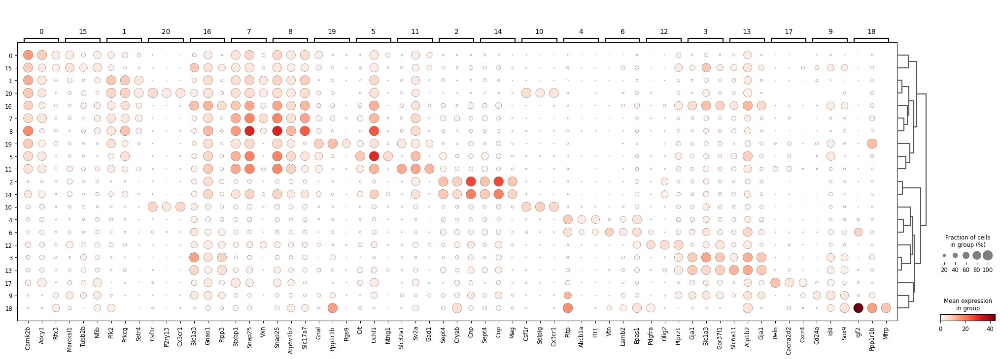

Cluster    | Genes (Top 1 to 7)                                          
---------------------------------------------------------------------------
0          | Camk2b, Adcy1, Rfx3, Prox1, Add2, Grm2, Sema5a              
1          | Plk2, Prkcg, Sstr4, Neurod6, Grin2a, Camkv, Ppp3r1          
2          | Sept4, Cryab, Cnp, Cntn2, Efnb3, Mog, Map7                  
3          | Gja1, Slc1a3, Gpr37l1, Aldoc, Plpp3, Ntsr2, Atp1b2          
4          | Pltp, Abcb1a, Flt1, Slc2a1, Epas1, Adgrf5, Podxl            
5          | Cit, Uchl1, Ntng1, Zic1, Slc17a6, Kcnc2, Ramp3              
6          | Vtn, Lamb2, Epas1, Pdgfrb, Lamc1, Vstm4, Utrn               
7          | Stxbp1, Snap25, Vxn, Slc17a7, Atp2b2, Cdk5r2, Dnm1          
8          | Snap25, Atp6v1b2, Slc17a7, Dnm1, Syn2, Nptxr, Stmn2         
9          | Cd24a, Id4, Sox9, Plxnb2, Foxj1, Rsph1, Pltp                
10         | Csf1r, Selplg, Cx3cr1, P2ry13, Trem2, Tmem119, Vsir         
11         | Slc32a1, Sv2a, Gad1, St

In [325]:
sc.tl.rank_genes_groups(sdata['table'],groupby='leiden')
sc.pl.rank_genes_groups_dotplot(sdata['table'],groupby='leiden',n_genes=3)

import pandas as pd

# Extract top 7 names
top_7_df = pd.DataFrame(sdata['table'].uns['rank_genes_groups']['names']).head(7)

# Print a simple header
print(f"{'Cluster':<10} | {'Genes (Top 1 to 7)':<60}")
print("-" * 75)

# Loop and print each cluster's genes on one line
for cluster in top_7_df.columns:
    genes_list = ", ".join(top_7_df[cluster].astype(str))
    print(f"{str(cluster):<10} | {genes_list:<60}")

In [326]:
# Mapping from Leiden cluster to cell type
leiden_to_cell_type = {
    "0": "Excitatory Neuron (Hippocampal / DG)",
    "1": "Excitatory Neuron (Cortical / Hippocampal)",
    "2": "Oligodendrocyte",
    "3": "Astrocyte",
    "4": "Endothelial Cell",
    "5": "Excitatory Neuron (Glutamatergic VGLUT2+)",
    "6": "Pericyte",
    "7": "Excitatory Neuron (Glutamatergic VGLUT1+)",
    "8": "Excitatory Neuron (Glutamatergic VGLUT1+)",
    "9": "Ependymal Cell",
    "10": "Microglia",
    "11": "Inhibitory Neuron (GABAergic)",
    "12": "Oligodendrocyte Precursor Cell (OPC)",
    "13": "Astrocyte",
    "14": "Oligodendrocyte",
    "15": "Neural Progenitor / Neuroblast",
    "16": "Astrocyte",
    "17": "Cajal-Retzius Cell / Pioneer Neuron",
    "18": "Choroid Plexus Epithelial Cell",
    "19": "Medium Spiny Neuron (Striatal)",
    "20": "Microglia"
}

sdata['table'].obs['cell_type']=sdata['table'].obs['leiden'].map(leiden_to_cell_type)

In [389]:
cellid2leiden=dict(zip(sdata['table'].obs.index,sdata['table'].obs['cell_type']))
sdata['structure_table'].obs['predicted_parent_leiden'] = sdata['structure_table'].obs['predicted_parent'].map(cellid2leiden)
adata_struct=sdata['structure_table'].copy()

In [390]:
print(adata_struct.shape)
sc.pp.filter_cells(adata_struct, min_counts=10)
print(adata_struct.shape)


(39258, 13073)
(9503, 13073)


In [391]:
adata_struct.layers['raw']=adata_struct.X.copy()

In [392]:
sc.pp.filter_genes(adata_struct,min_cells=20)
sc.pp.normalize_total(adata_struct)
sc.pp.log1p(adata_struct)

In [393]:
sc.pp.pca(adata_struct)
sc.pp.neighbors(adata_struct,n_pcs=20,n_neighbors=10)

In [400]:
sc.tl.umap(adata_struct,min_dist=0.2)
sc.tl.leiden(adata_struct,resolution=0.6,key_added='leiden_structure')

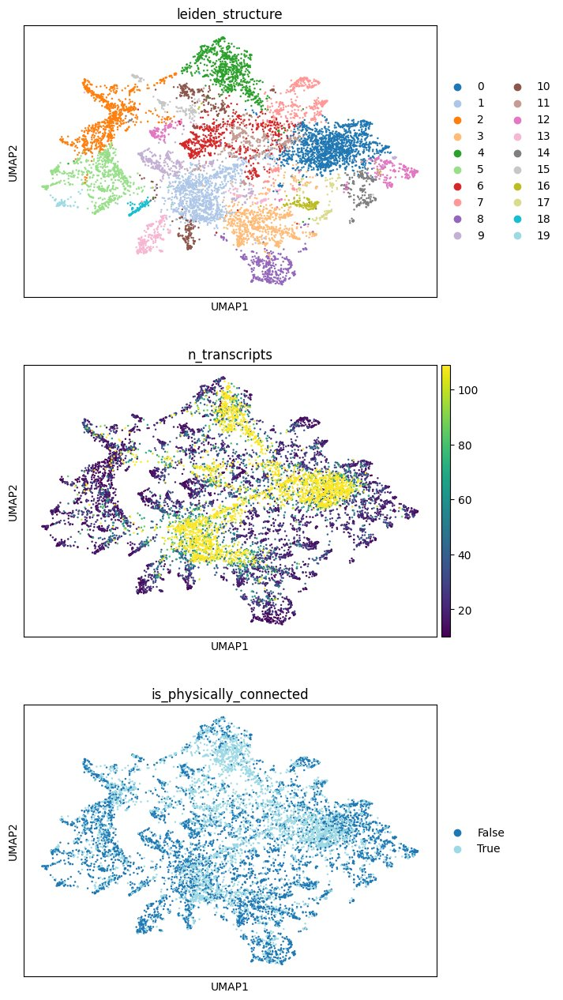

In [403]:
sc.pl.umap(adata_struct,color=['leiden_structure','n_transcripts','is_physically_connected'],ncols=1,vmax='p80',palette='tab20')

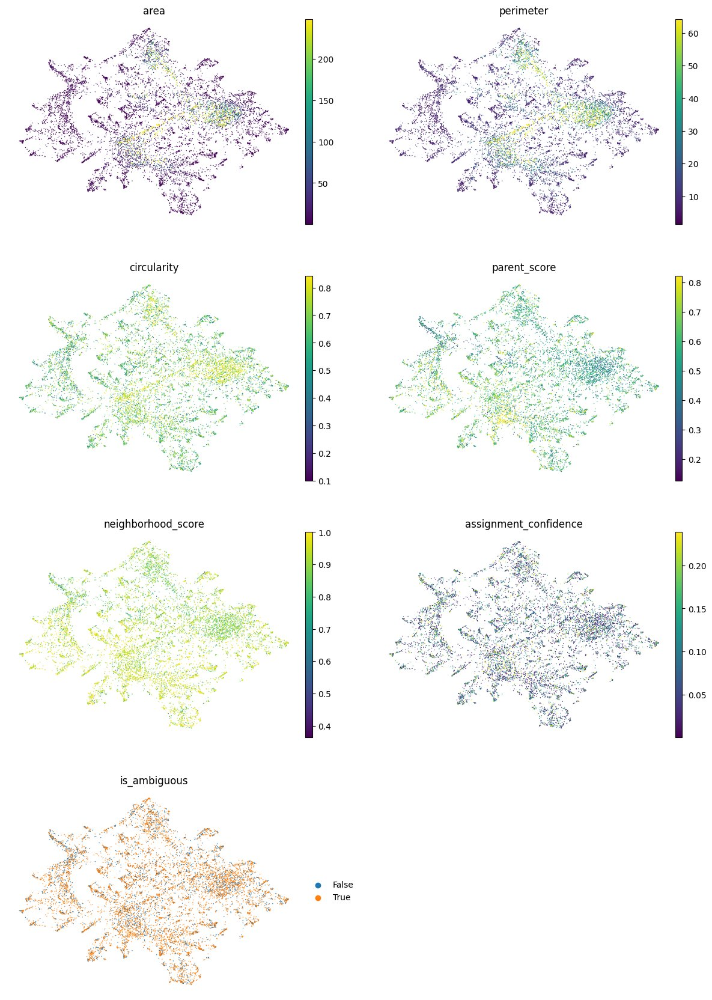

In [404]:
sc.pl.umap(adata_struct,color=['area','perimeter','circularity','parent_score','neighborhood_score','assignment_confidence','is_ambiguous'],frameon=False,cmap='viridis',ncols=2,vmax='p95',s=4)

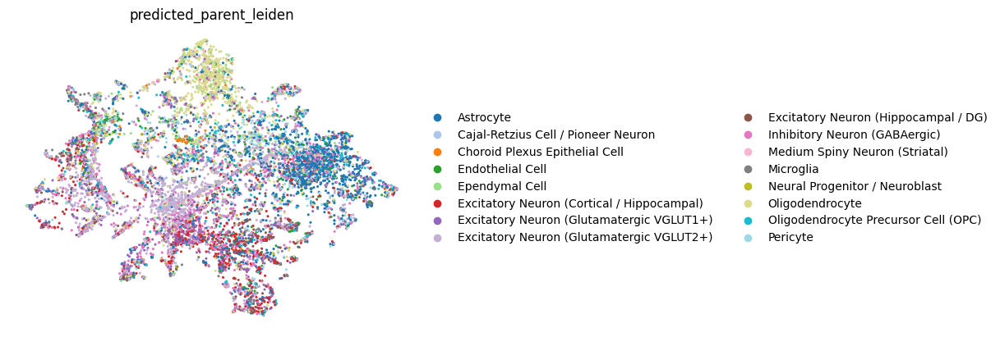

In [405]:
sc.pl.umap(adata_struct,color=['predicted_parent_leiden'],frameon=False,palette='tab20',ncols=2,vmax='p95',s=20)

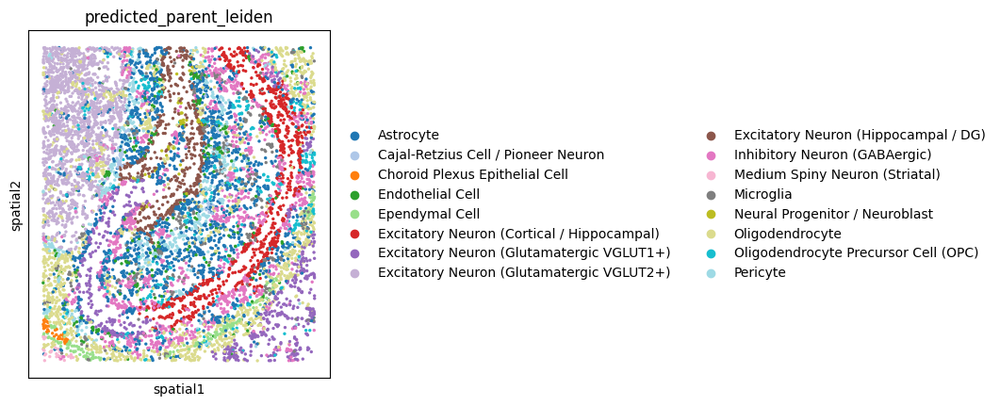

In [406]:
sc.pl.spatial(adata_struct,color='predicted_parent_leiden',spot_size=20)

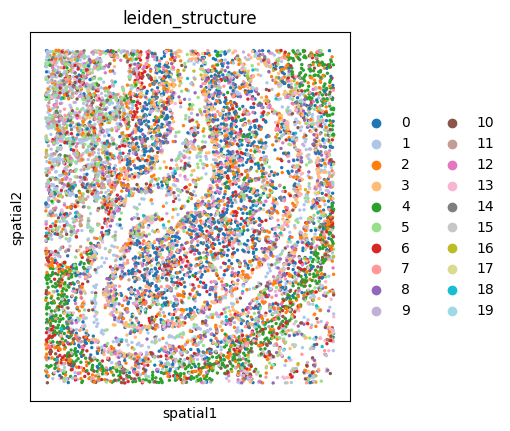

In [407]:
sc.pl.spatial(adata_struct,color='leiden_structure',spot_size=20)

In [ ]:
sc.tl.rank_genes_groups(adata_struct, groupby="leiden_structure", method="wilcoxon")
sc.pl.rank_genes_groups_dotplot(adata_struct, groupby="leiden_structure",n_genes=3)

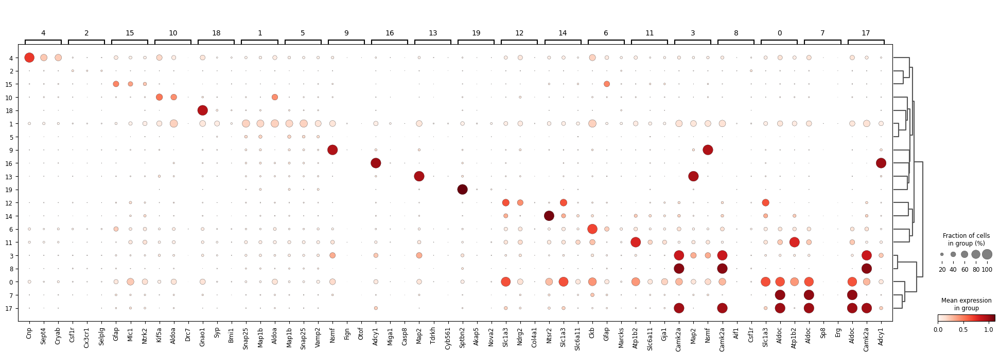

In [414]:
# Extract top 7 names
top_7_df = pd.DataFrame(adata_struct.uns['rank_genes_groups']['names']).head(3)

# Print a simple header
print(f"{'Cluster':<10} | {'Genes (Top 1 to 7)':<60}")
print("-" * 75)

# Loop and print each cluster's genes on one line
for cluster in top_7_df.columns:
    genes_list = ", ".join(top_7_df[cluster].astype(str))
    print(f"{str(cluster):<10} | {genes_list:<60}")

Cluster    | Genes (Top 1 to 7)                                          
---------------------------------------------------------------------------
0          | Slc1a3, Aldoc, Atp1b2                                       
1          | Snap25, Map1b, Aldoa                                        
2          | Csf1r, Cx3cr1, Selplg                                       
3          | Camk2a, Map2, Nsmf                                          
4          | Cnp, Sept4, Cryab                                           
5          | Map1b, Snap25, Vamp2                                        
6          | Ckb, Gfap, Marcks                                           
7          | Aldoc, Sp8, Erg                                             
8          | Camk2a, Aif1, Csf1r                                         
9          | Nsmf, Fign, Otof                                            
10         | Kif5a, Aldoa, Drc7                                          
11         | Atp1b2, Slc6a11, Gja1  

In [415]:
# Dictionary 1: Cell Type Mapping
cell_types = {
    0: "Astrocyte",
    1: "Neuron",
    2: "Microglia",
    3: "Neuron",
    4: "Oligodendrocyte",
    5: "Neuron",
    6: "Astrocyte",
    7: "Endothelial cell",
    8: "Microglia / Neuron interface",
    9: "Neuron",
    10: "Neuron",
    11: "Astrocyte",
    12: "Astrocyte",
    13: "Neuron",
    14: "Astrocyte",
    15: "Astrocyte",
    16: "Neuron",
    17: "Neuron",
    18: "Neuron",
    19: "Neuron"
}

# Dictionary 2: Subcellular / Extracellular Component Mapping
subcellular_components = {
    0: "Soma / Fibrous processes",
    1: "Presynaptic terminals & Axons",
    2: "Ramified processes / Soma",
    3: "Dendrites & Postsynaptic densities",
    4: "Myelin sheath",
    5: "Presynaptic active zones / Synaptic vesicles",
    6: "Reactive processes / Cytoskeleton",
    7: "Vascular endothelial lining",
    8: "Phagocytic protrusions / Synaptic pruning zones",
    9: "Growth cones / Axon terminals",
    10: "Axonal transport tracks / Microtubules",
    11: "Perisynaptic ensheathing processes",
    12: "Perivascular end-feet / Vascular interface",
    13: "Dendritic segments & Endomembrane organelles",
    14: "Velate protrusions",
    15: "Glia limitans / End-foot membrane",
    16: "Synaptic terminals / Mitochondrial-associated membranes",
    17: "Postsynaptic signaling hubs",
    18: "Presynaptic boutons & Vesicle clusters",
    19: "Dendritic spines & Actin-stabilized membranes"
}

In [ ]:
adata_struct.obs['leiden_structure_component']=adata_struct.obs['leiden_structure'].astype(int).map(subcellular_components)
adata_struct.obs['leiden_structure_celltype']=adata_struct.obs['leiden_structure'].astype(int).map(cell_types)
adata_struct.obs['leiden_structure_annotation']=adata_struct.obs['leiden_structure_celltype']+','+adata_struct.obs['leiden_structure_component']

In [ ]:
sc.pl.umap(adata_struct,color='leiden_structure_component',frameon=False,palette='tab20',ncols=2,vmax='p95',s=20)

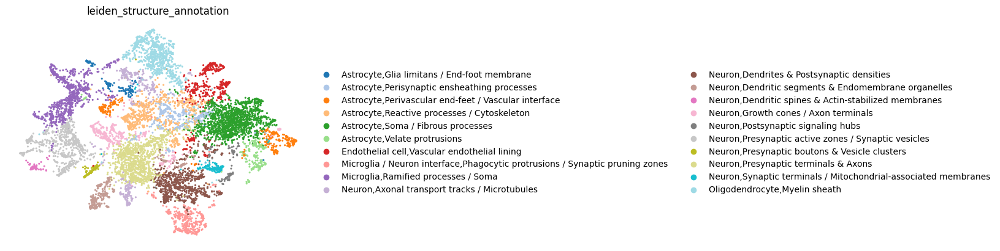

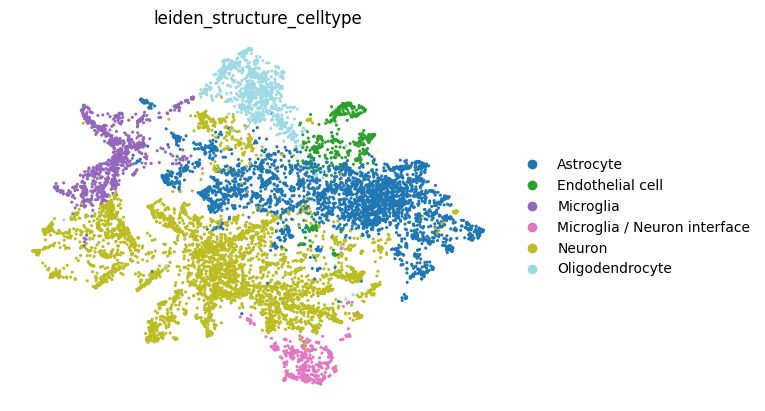

In [424]:
sc.pl.umap(adata_struct,color='leiden_structure_annotation',frameon=False,palette='tab20',ncols=2,vmax='p95',s=20)
sc.pl.umap(adata_struct,color='leiden_structure_celltype',frameon=False,palette='tab20',ncols=2,vmax='p95',s=20)

dendrogram data not found (using key=dendrogram_leiden_structure_annotation). Running `sc.tl.dendrogram` with default parameters. For fine tuning it is recommended to run `sc.tl.dendrogram` independently.


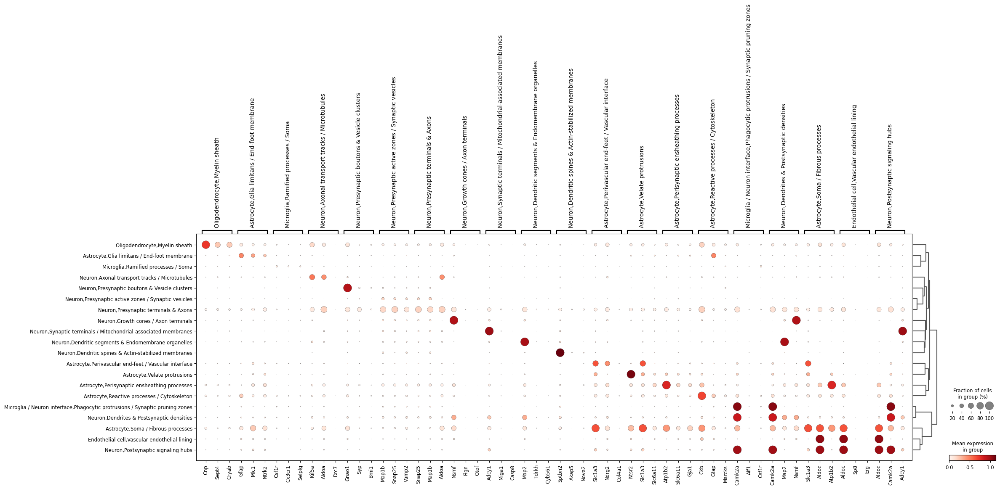

In [427]:
sc.tl.rank_genes_groups(adata_struct, groupby="leiden_structure_annotation", method="wilcoxon")
sc.pl.rank_genes_groups_dotplot(adata_struct, groupby="leiden_structure_annotation",n_genes=3)

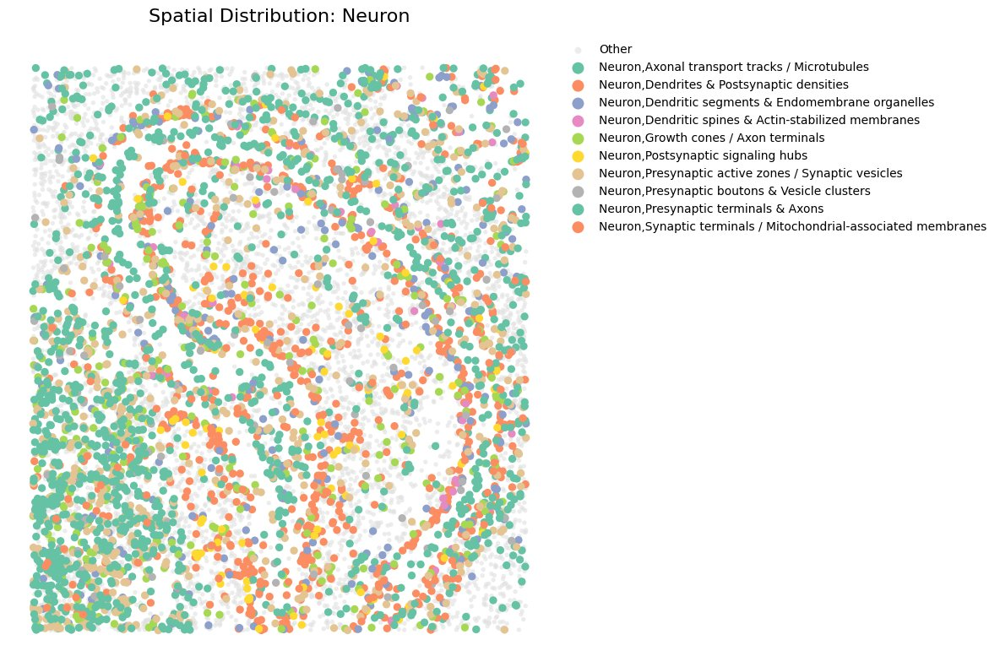

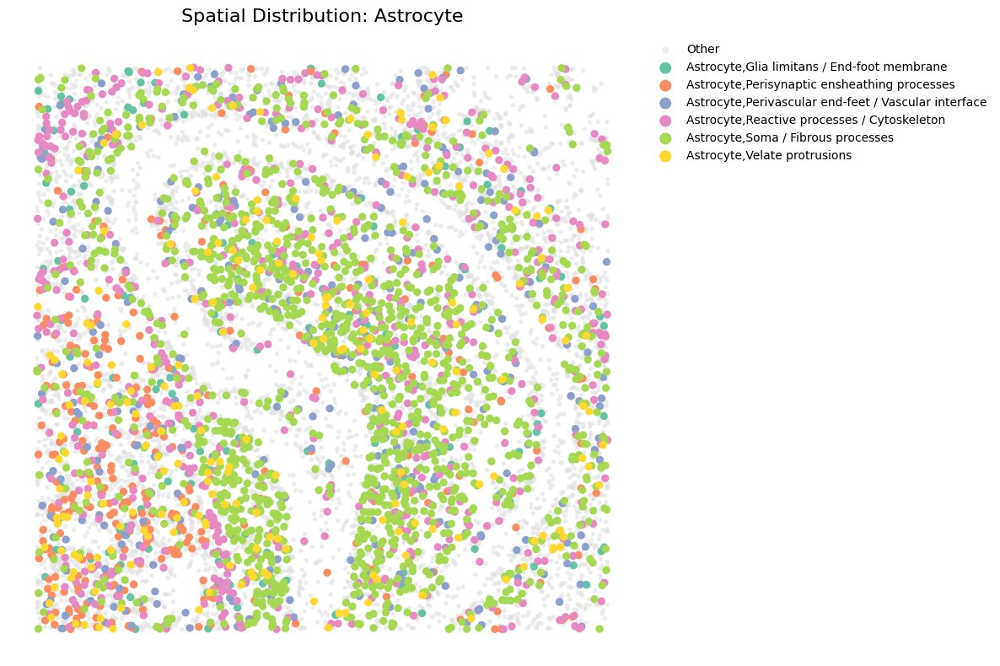

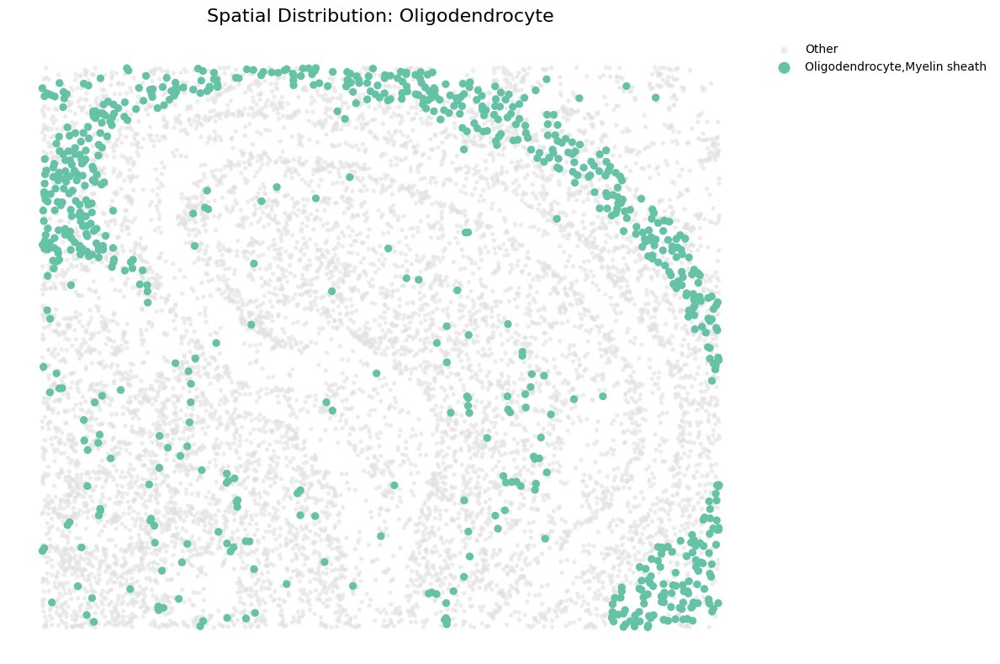

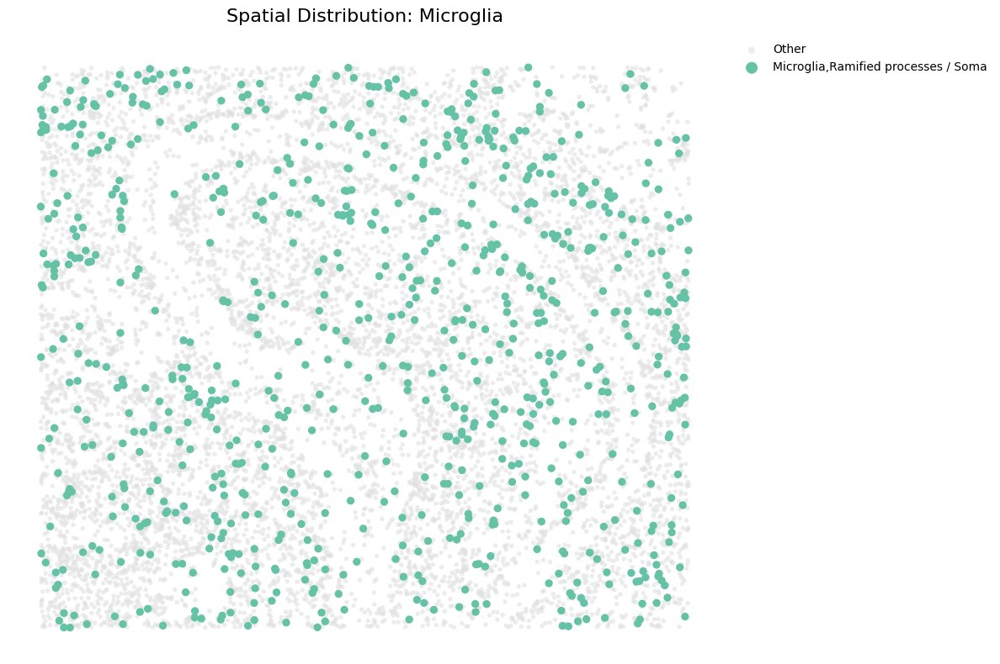

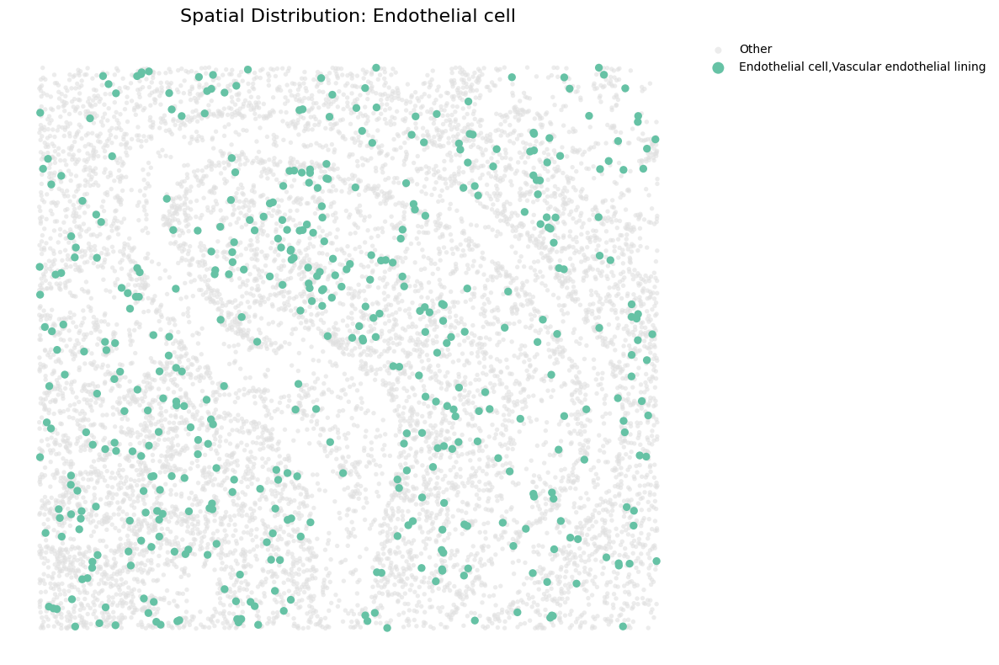

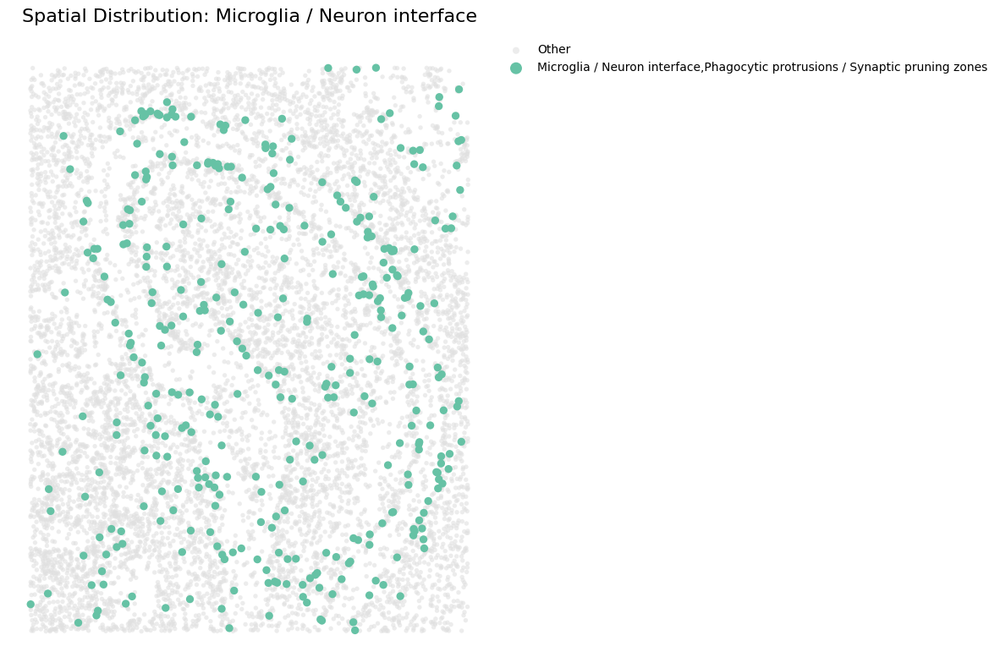

In [426]:
import matplotlib.pyplot as plt
import numpy as np
import scanpy as sc
import seaborn as sns

# Ensure columns are categorical
adata_struct.obs["leiden_structure_celltype"] = adata_struct.obs[
    "leiden_structure_celltype"
].astype("category")
adata_struct.obs["leiden_structure_annotation"] = adata_struct.obs[
    "leiden_structure_annotation"
].astype("category")

unique_cell_types = adata_struct.obs["leiden_structure_celltype"].unique()

# Extract spatial coordinates once (assuming shape is N x 2)
spatial_coords = adata_struct.obsm["spatial"]

for cell_type in unique_cell_types:
    # Set up an enlarged figure layout to accommodate the external legend
    fig, ax = plt.subplots(figsize=(12, 8))

    # Identify indices for background (Other) vs foreground (Active Cell Type)
    is_active = adata_struct.obs["leiden_structure_celltype"] == cell_type
    is_other = ~is_active

    # 1. Plot background "Other" spots first (smaller size, light grey)
    ax.scatter(
        spatial_coords[is_other, 0],
        spatial_coords[is_other, 1],
        c="#E0E0E0",
        s=15,  # Smaller background size
        label="Other",
        alpha=0.6,
        edgecolors="none",
    )

    # 2. Extract foreground categories and set up colors
    fg_annotations = adata_struct.obs.loc[is_active, "leiden_structure_annotation"].astype(str)
    unique_fg_cats = sorted(fg_annotations.unique())
    
    color_palette = sns.color_palette("Set2", len(unique_fg_cats))
    color_map = dict(zip(unique_fg_cats, color_palette))

    # 3. Plot foreground spots layered on top (grouped by category for clean legend tracking)
    for cat in unique_fg_cats:
        cat_mask = (fg_annotations == cat).values
        # Combine the cell_type mask with the specific category mask
        coords_subset = spatial_coords[is_active][cat_mask]
        
        ax.scatter(
            coords_subset[:, 0],
            coords_subset[:, 1],
            c=[color_map[cat]],
            s=45,  # Larger real colored spots on top
            label=cat,
            edgecolors="none",
        )

    # 4. Format and push the legend entirely outside the plotting area
    ax.set_title(f"Spatial Distribution: {cell_type}", fontsize=16, pad=15)
    ax.axis("off")  # Clear frame clutter

    # Position legend to the right side of the enlarged canvas
    ax.legend(
        loc="upper left",
        bbox_to_anchor=(1.02, 1),
        borderaxespad=0,
        frameon=False,
        markerscale=1.5,
        fontsize=10,
    )

    # Clean adjustments to ensure nothing clips
    plt.tight_layout()
    plt.show()

In [429]:
parent_vs_structure=pd.crosstab(adata_struct.obs['leiden_structure_annotation'],adata_struct.obs['predicted_parent_leiden'])
parent_vs_structure=parent_vs_structure.div(parent_vs_structure.sum(axis=1),axis=0)

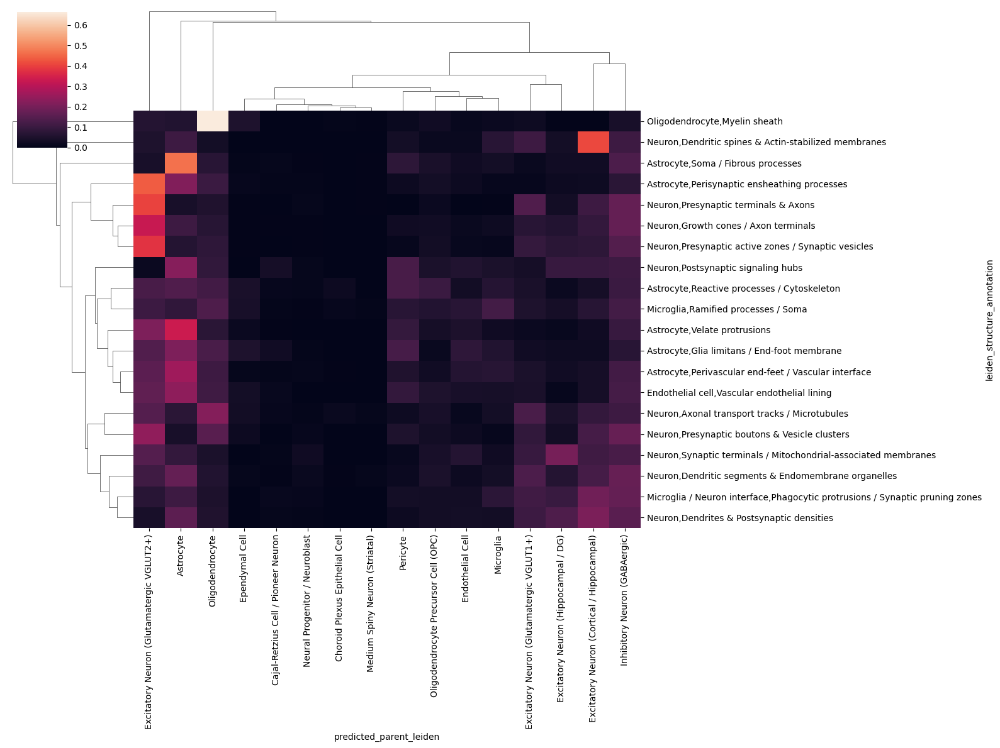

In [432]:
sns.clustermap(parent_vs_structure,figsize=(16,12))

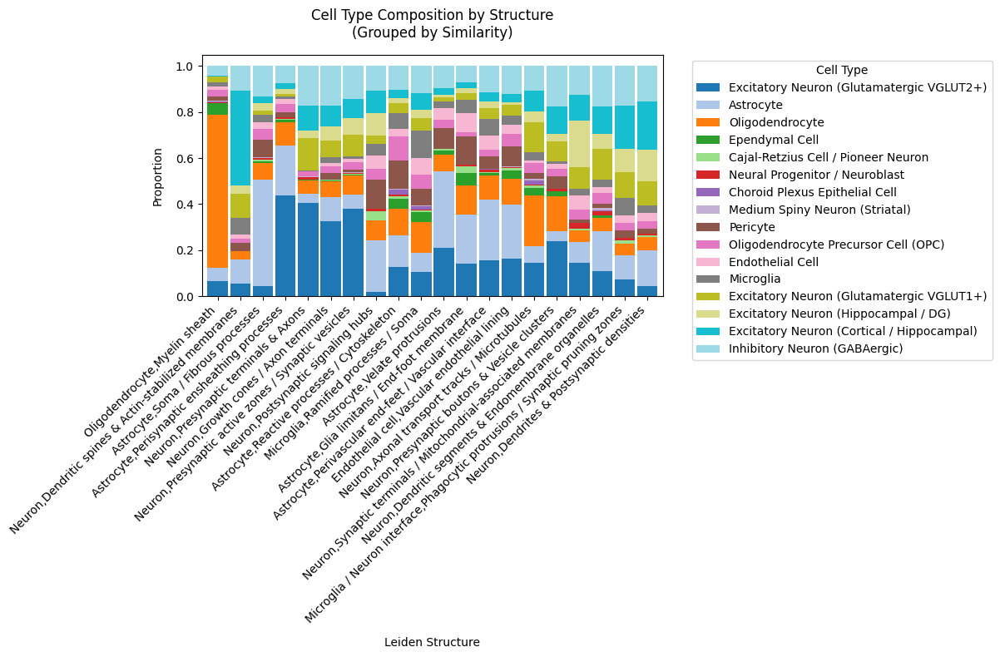

In [433]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram

struct_info=adata_struct.obs[adata_struct.obs['assignment_confidence']>0.0]

# --- 1. Generate your normalized crosstab ---
parent_vs_structure = pd.crosstab(struct_info['leiden_structure_annotation'], struct_info['predicted_parent_leiden'])
parent_vs_structure = parent_vs_structure.div(parent_vs_structure.sum(axis=1), axis=0)

# --- 2. Compute Hierarchical Clustering (Mimicking sns.clustermap) ---
# Cluster rows (leiden_structure) to find the x-axis similarity order
row_linkage = linkage(parent_vs_structure, method='average', metric='euclidean')
row_order = dendrogram(row_linkage, no_plot=True)['leaves']
ordered_structures = parent_vs_structure.index[row_order]

# Cluster columns (Cell Types) to group the stacked blocks by similarity
col_linkage = linkage(parent_vs_structure.T, method='average', metric='euclidean')
col_order = dendrogram(col_linkage, no_plot=True)['leaves']
ordered_cell_types = parent_vs_structure.columns[col_order]

# --- 3. Reorder the DataFrame ---
df_clustered = parent_vs_structure.loc[ordered_structures, ordered_cell_types]

# --- 4. Plot Stacked Bar Chart ---
# Match your requested figure size dimensions (6, 8)
fig, ax = plt.subplots(figsize=(12, 8))

# Rows (structures) become the x-axis bars; Columns (cell types) become the stacked segments
df_clustered.plot(kind='bar', stacked=True, ax=ax, cmap='tab20',width=0.9)

# Polish aesthetics
ax.set_title("Cell Type Composition by Structure\n(Grouped by Similarity)", fontsize=12, pad=15)
ax.set_xlabel("Leiden Structure", fontsize=10, labelpad=10)
ax.set_ylabel("Proportion", fontsize=10, labelpad=10)
plt.xticks(rotation=45, ha='right')

# Push the legend cleanly outside the plot canvas
ax.legend(title="Cell Type", bbox_to_anchor=(1.05, 1), loc='upper left', frameon=True)

plt.tight_layout()
plt.show()

## now we map back to the original object

In [435]:
struct2leid=dict(zip(adata_struct.obs.index, adata_struct.obs['leiden_structure'].astype(int)))
sdata['structure_table'].obs['leiden_structure']=sdata['structure_table'].obs.index.map(struct2leid)

struct2leid_anno=dict(zip(adata_struct.obs.index, adata_struct.obs['leiden_structure_annotation']))
sdata['structure_table'].obs['leiden_structure_annotation']=sdata['structure_table'].obs.index.map(struct2leid_anno)

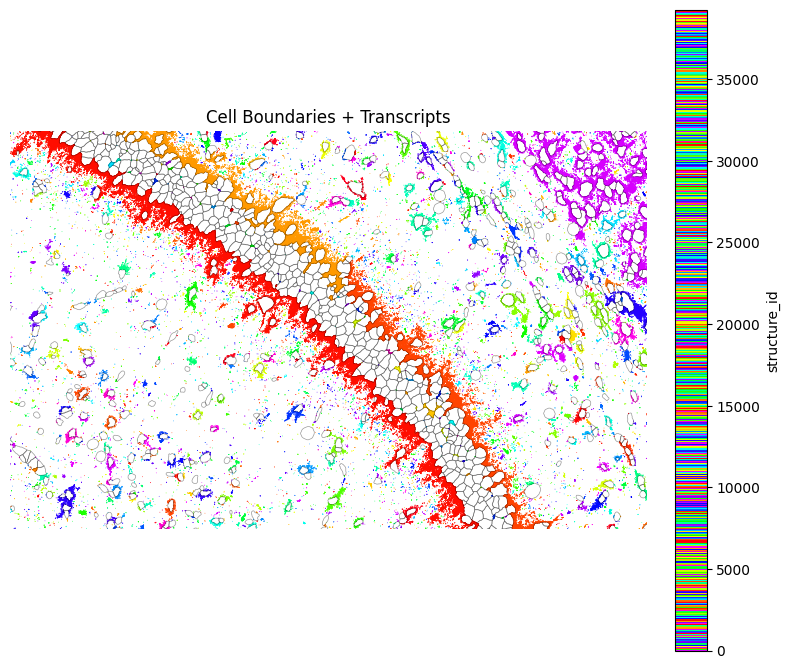

In [380]:
unique_ids = sdata['structure_table'].obs.index.unique()
num_structures = len(unique_ids)

# Generate and shuffle base random colors
base_colors = plt.cm.gist_rainbow(np.linspace(0, 1, num_structures))
np.random.seed(42)
np.random.shuffle(base_colors)
random_structure_cmap = ListedColormap(base_colors)

# Execute updated plotting framework
fig, ax = spatial_transcripts(
    sdata,
    color_key="structure_id",       
    colormap=random_structure_cmap,  
    scatter_size=0.2,use_roi=True, roi=(4900, 5700, 2100, 2600),
    alpha=1, # Adjust opacity of the unmapped grey points easily
    rasterize=True,missing_val_sentinel=-1
)

plt.show()

(<Figure size 800x800 with 2 Axes>,
 <Axes: title={'center': 'Cell Boundaries + Transcripts'}>)

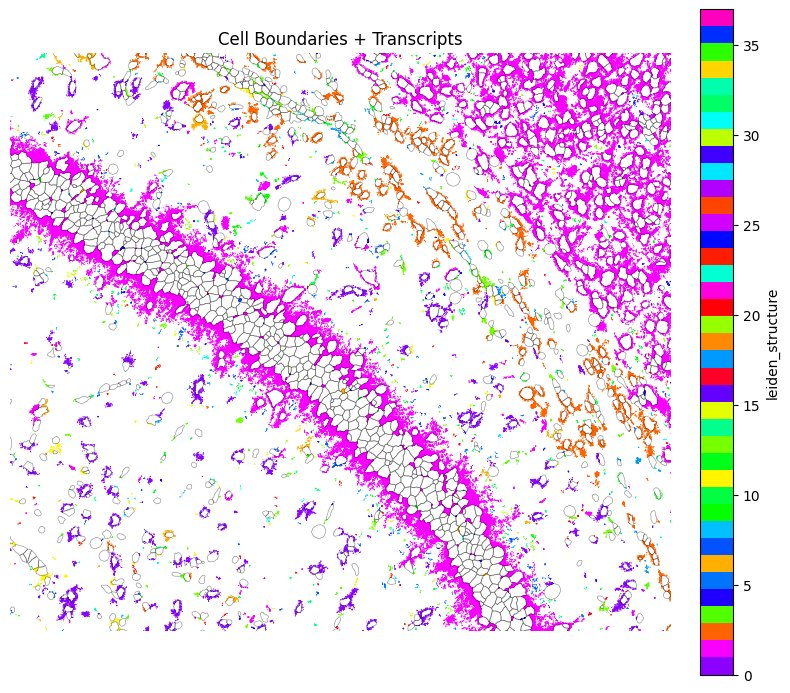

In [383]:
unique_ids = sdata['structure_table'].obs['leiden_structure'].unique()
num_structures = len(unique_ids)

# Generate and shuffle base random colors
base_colors = plt.cm.gist_rainbow(np.linspace(0, 1, num_structures))
np.random.seed(42)
np.random.shuffle(base_colors)
random_structure_cmap = ListedColormap(base_colors)

# visualize image
spatial_transcripts(
    sdata,
    color_key="leiden_structure", colormap=random_structure_cmap, 
    scatter_size=0.2,use_roi=True, roi=(4900, 5700, 2100, 2800),
    alpha=1, # Adjust opacity of the unmapped grey points easily
    rasterize=True,missing_val_sentinel=-1)

# Scores by cluster

In [ ]:
connected_vs_annotation=pd.crosstab(adata_struct.obs['leiden_structure_annotation'],adata_struct.obs['is_physically_connected'])
connected_vs_annotation=connected_vs_annotation.div(connected_vs_annotation.sum(axis=1),axis=0)
connected_vs_annotation=connected_vs_annotation.sort_values(by=True)
connected_vs_annotation.plot(kind='bar',width=0.95,stacked=True,figsize=(8,3),cmap='Set1')

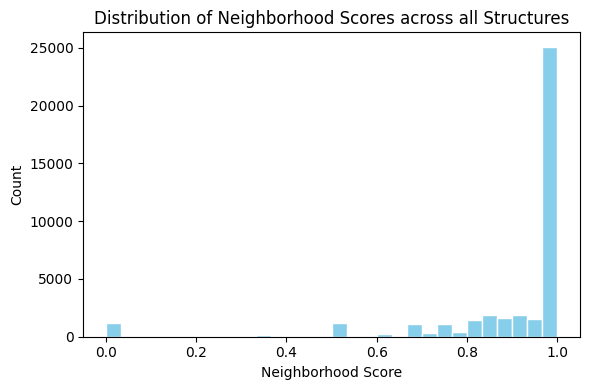

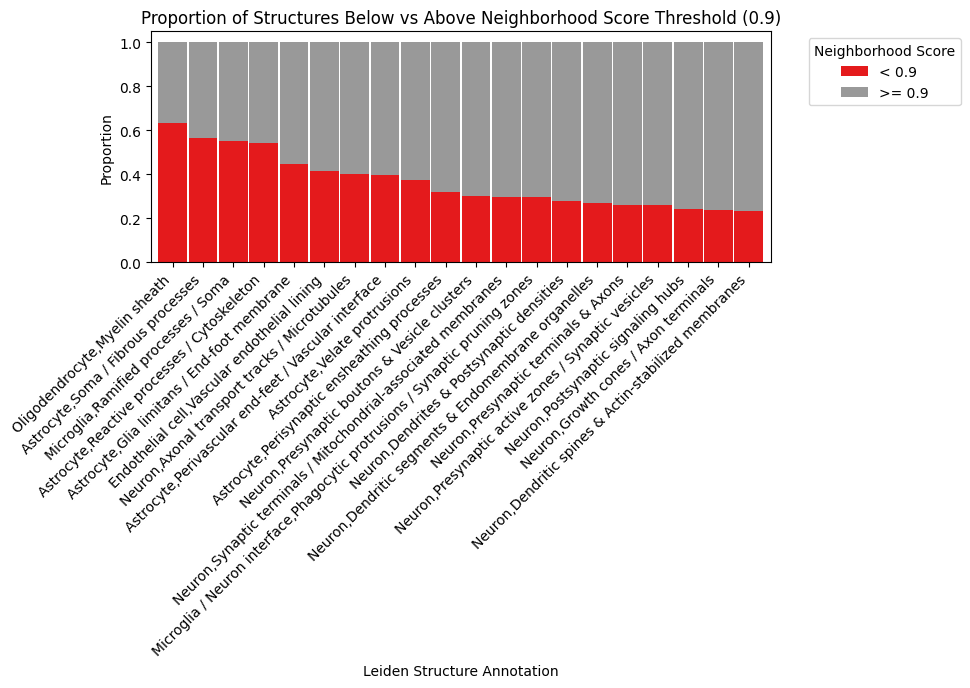

In [464]:
import pandas as pd
import matplotlib.pyplot as plt

# --- STEP 0: Extract the metadata dataframe ---
df_obs = sdata.tables["structure_table"].obs

# --- PLOT 1: Distribution of Neighborhood Scores ---
plt.figure(figsize=(6, 4))
df_obs["neighborhood_score"].plot(kind="hist", bins=30, color="skyblue", edgecolor="white")
plt.title("Distribution of Neighborhood Scores across all Structures")
plt.xlabel("Neighborhood Score")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

# --- PLOT 2: Stacked Threshold Plot (Matching your reference) ---
threshold = 0.9

# 1. Create a clean string column for the threshold status
df_obs['score_status'] = df_obs['neighborhood_score'].apply(
    lambda x: f'< {threshold}' if x < threshold else f'>= {threshold}'
)

# 2. Generate the cross-tabulation (counts)
thresh_vs_annotation = pd.crosstab(
    df_obs['leiden_structure_annotation'], 
    df_obs['score_status']
)

# 3. Normalize to percentages (so each row sums to 1.0 / 100%)
thresh_vs_annotation = thresh_vs_annotation.div(thresh_vs_annotation.sum(axis=1), axis=0)

# 4. Sort by the percentage of structures that are BELOW the threshold
# (This keeps the sorting logic identical to your `by=True` reference)
thresh_vs_annotation = thresh_vs_annotation.sort_values(by=f'< {threshold}', ascending=False)

# 5. Plot using your exact styling specifications
thresh_vs_annotation.plot(
    kind='bar', 
    width=0.95, 
    stacked=True, 
    figsize=(8, 3), 
    cmap='Set1'
)

plt.title(f"Proportion of Structures Below vs Above Neighborhood Score Threshold ({threshold})")
plt.ylabel("Proportion")
plt.xlabel("Leiden Structure Annotation")
plt.xticks(rotation=45, ha='right')
plt.legend(title="Neighborhood Score", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [465]:
sdata.tables["structure_table"].obs

,x,y,structure_label,n_transcripts,is_physically_connected,area,perimeter,circularity,cosine_similarity,cosine_sim_stainings,...,parent_score,neighborhood_score,assignment_confidence,is_ambiguous,region,instance_id,predicted_parent_leiden,leiden_structure,leiden_structure_annotation,score_status
struct_0,5593.763184,2743.373779,Cell-Like Structure,422800,True,192746.835571,1821.277846,0.730205,0.815820,0.999974,...,0.246945,0.543868,0.031652,True,transcripts,0,Excitatory Neuron (Glutamatergic VGLUT1+),1.0,"Neuron,Presynaptic terminals & Axons",< 0.9
struct_1,4404.079590,1527.692017,Cell-Like Structure,5486,True,2259.617920,177.786411,0.898355,0.775883,0.999943,...,0.640569,0.862437,0.056534,True,transcripts,1,Excitatory Neuron (Glutamatergic VGLUT2+),1.0,"Neuron,Presynaptic terminals & Axons",< 0.9
struct_2,4421.598145,1569.390381,High-Density Structure,394,True,170.305908,49.966918,0.857185,0.700467,0.931555,...,0.598468,0.939394,0.011738,True,transcripts,2,Excitatory Neuron (Glutamatergic VGLUT2+),1.0,"Neuron,Presynaptic terminals & Axons",>= 0.9
struct_3,4088.246094,1288.842773,Cell-Like Structure,395,True,294.953857,82.046511,0.550610,0.766893,0.971525,...,0.717009,0.922807,0.147650,False,transcripts,3,Excitatory Neuron (Glutamatergic VGLUT2+),11.0,"Astrocyte,Perisynaptic ensheathing processes",>= 0.9
struct_4,5347.040039,1879.889038,Cell-Like Structure,264039,True,681020.874390,3854.204768,0.576104,0.809546,0.999991,...,0.284545,0.563507,0.121104,False,transcripts,4,Inhibitory Neuron (GABAergic),3.0,"Neuron,Dendrites & Postsynaptic densities",< 0.9
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
struct_39253,5203.359375,2602.734375,High-Density Structure,1,False,NaN,NaN,NaN,0.329677,0.592876,...,0.850901,1.000000,0.028881,True,transcripts,39253,Inhibitory Neuron (GABAergic),NaN,NaN,>= 0.9
struct_39254,4210.500000,1364.500000,High-Density Structure,1,False,NaN,NaN,NaN,0.313933,0.566221,...,0.807978,1.000000,0.016429,True,transcripts,39254,Excitatory Neuron (Glutamatergic VGLUT2+),NaN,NaN,>= 0.9
struct_39255,4367.468750,1627.578125,High-Density Structure,1,False,NaN,NaN,NaN,0.352086,0.581385,...,0.846532,1.000000,0.025781,True,transcripts,39255,Endothelial Cell,NaN,NaN,>= 0.9
struct_39256,4165.453125,1297.218750,High-Density Structure,1,True,NaN,NaN,NaN,0.479837,0.684878,...,1.064954,1.000000,0.061661,True,transcripts,39256,Oligodendrocyte,NaN,NaN,>= 0.9


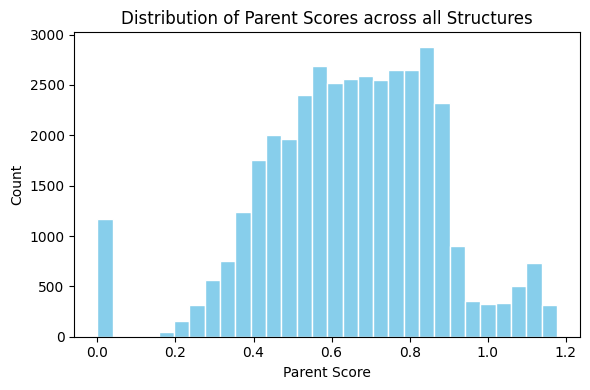

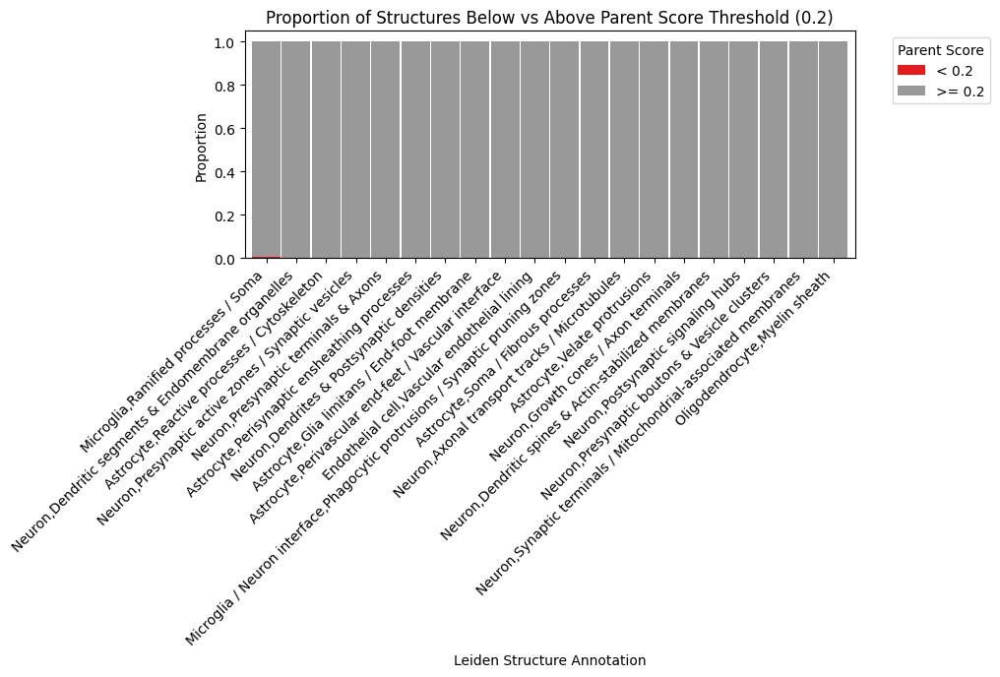

In [468]:
import pandas as pd
import matplotlib.pyplot as plt

# --- STEP 0: Extract the metadata dataframe ---
df_obs = sdata.tables["structure_table"].obs

# --- PLOT 1: Distribution of Neighborhood Scores ---
plt.figure(figsize=(6, 4))
df_obs["parent_score"].plot(kind="hist", bins=30, color="skyblue", edgecolor="white")
plt.title("Distribution of Parent Scores across all Structures")
plt.xlabel("Parent Score")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

# --- PLOT 2: Stacked Threshold Plot (Matching your reference) ---
threshold = 0.2

# 1. Create a clean string column for the threshold status
df_obs['score_status'] = df_obs['parent_score'].apply(
    lambda x: f'< {threshold}' if x < threshold else f'>= {threshold}'
)

# 2. Generate the cross-tabulation (counts)
thresh_vs_annotation = pd.crosstab(
    df_obs['leiden_structure_annotation'], 
    df_obs['score_status']
)

# 3. Normalize to percentages (so each row sums to 1.0 / 100%)
thresh_vs_annotation = thresh_vs_annotation.div(thresh_vs_annotation.sum(axis=1), axis=0)

# 4. Sort by the percentage of structures that are BELOW the threshold
# (This keeps the sorting logic identical to your `by=True` reference)
thresh_vs_annotation = thresh_vs_annotation.sort_values(by=f'< {threshold}', ascending=False)

# 5. Plot using your exact styling specifications
thresh_vs_annotation.plot(
    kind='bar', 
    width=0.95, 
    stacked=True, 
    figsize=(8, 3), 
    cmap='Set1'
)

plt.title(f"Proportion of Structures Below vs Above Parent Score Threshold ({threshold})")
plt.ylabel("Proportion")
plt.xlabel("Leiden Structure Annotation")
plt.xticks(rotation=45, ha='right')
plt.legend(title="Parent Score", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

(<Figure size 800x800 with 2 Axes>,
 <Axes: title={'center': 'Cell Boundaries + Transcripts'}>)

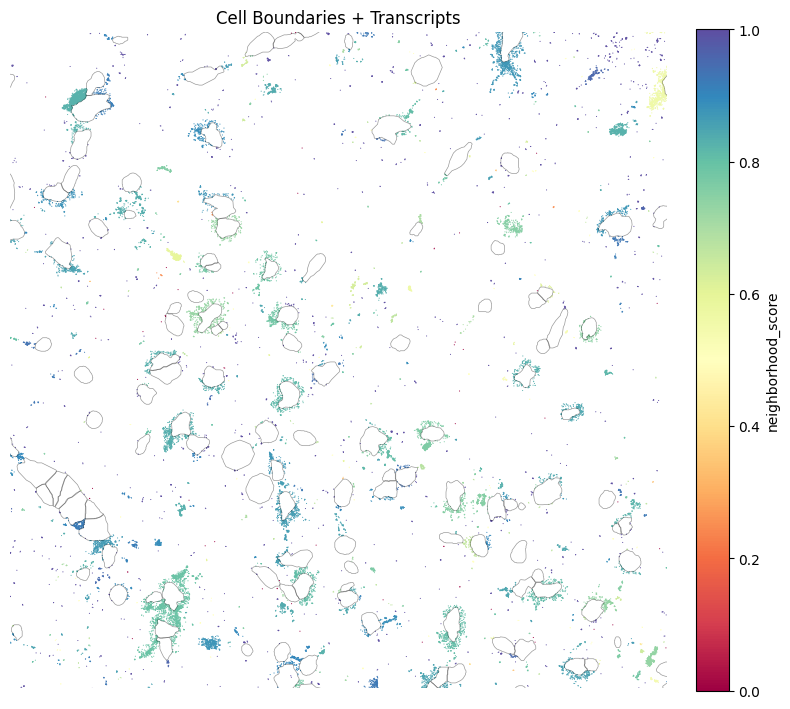

In [ ]:
spatial_transcripts(
    sdata,
    color_key="neighborhood_score", colormap='Spectral', 
    scatter_size=0.8,use_roi=True, roi=(4900, 5200, 2100, 2400),
    alpha=1, # Adjust opacity of the unmapped grey points easily
    rasterize=True,missing_val_sentinel=-1)

(<Figure size 800x800 with 2 Axes>,
 <Axes: title={'center': 'Cell Boundaries + Transcripts'}>)

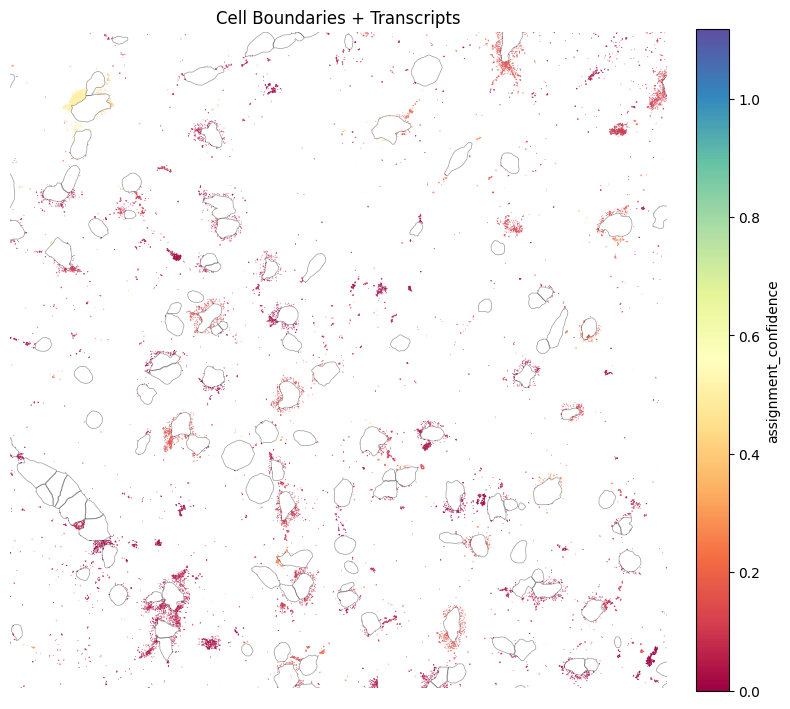

In [474]:
spatial_transcripts(
    sdata,
    color_key="assignment_confidence", colormap='Spectral', 
    scatter_size=0.8,use_roi=True, roi=(4900, 5200, 2100, 2400),
    alpha=1, # Adjust opacity of the unmapped grey points easily
    rasterize=True,missing_val_sentinel=-1)

In [472]:
sdata['structure_table'].obs.columns

Index(['x', 'y', 'structure_label', 'n_transcripts', 'is_physically_connected',
       'area', 'perimeter', 'circularity', 'cosine_similarity',
       'cosine_sim_stainings', 'enrichment_over_random', 'predicted_parent',
       'parent_score', 'neighborhood_score', 'assignment_confidence',
       'is_ambiguous', 'region', 'instance_id', 'predicted_parent_leiden',
       'leiden_structure', 'leiden_structure_annotation', 'score_status'],
      dtype='object')

# We do DRVI

In [361]:
import drvi as dr   

KeyboardInterrupt: 

In [ ]:
import drvi.utils.tools

# 1. Additional unimodal plots

In [ ]:
from matplotlib.colors import ListedColormap, Normalize
import matplotlib.pyplot as plt
import geopandas as gpd
from shapely.affinity import affine_transform
from shapely.geometry import box
import numpy as np
import pandas as pd


def spatial_transcripts(
    sdata: SpatialData,
    gene_key: str = "gene",
    gene_list: list[str] | None = None,
    color_key: str = "transcript_type",
    shapes_key: str = "cell_boundaries",
    colormap: str = "30colors",
    boundary_linewidth: float = 0.5,
    scatter_size: float = 1.0,
    alpha: float = 0.8,
    use_roi: bool = False,
    roi: tuple[float, float, float, float] = (0, 20000, 0, 20000),
    figsize: tuple[float, float] = (8, 8),
    title: str = "Cell Boundaries + Transcripts",
) -> tuple[plt.Figure, plt.Axes]:
    """
    Plot cell boundary polygons and transcript points, colored by a categorical variable
    or a numeric variable, scaling geometries by an affine matrix from get_transformation.

    Parameters
    ----------
    sdata
        A SpatialData object containing:
          - sdata[shapes_key]  including a 'geometry' column of shapely Polygons
          - sdata['transcripts'] including `gene_key` and `color_key`
    gene_key: str
        Column in transcripts to filter by gene_list.
    gene_list: Optional[List[str]]
        List of genes to keep. If None, all transcripts are used.
    color_key: str
        Column in transcripts used for coloring points. Can be categorical or numeric.
    shapes_key: str
        Key in sdata for your polygon boundaries layer.
    colormap: str
        Name of a Matplotlib colormap or troutpy palette name.
    boundary_linewidth: float
        Line width of cell boundary outlines.
    scatter_size: float
        Marker size for transcript points.
    alpha: float
        Transparency for transcript points.
    use_roi: bool
        If True, restrict both polygons and points to the bounding box given by `roi`.
    roi: Tuple[float, float, float, float]
        (xmin, xmax, ymin, ymax) bounds to clip to when `use_roi=True`.
    figsize: Tuple[float, float]
        Width and height of the figure.
    title: str
        Title string placed above the plot.

    Returns
    -------
    fig, ax
        The Matplotlib figure and axes objects.
    """
    # 1) Filter transcripts by gene_list
    trans_ad = sdata["transcripts"].compute()
    if gene_list is not None:
        trans_ad = trans_ad[trans_ad[gene_key].isin(gene_list)]

    # annotate transcript types
    trans_ad["segstatus"] = trans_ad["overlaps_cell"].astype(str) + "_" + trans_ad["extracellular"].astype(str)
    stat2lab = {"True_False": "cell", "False_True": "extracellular", "False_False": "cell-like"}
    trans_ad["transcript_type"] = trans_ad["segstatus"].map(stat2lab)

    # 2) Prepare color values based on type (categorical or numeric)
    trans_df = trans_ad.copy()
    if pd.api.types.is_numeric_dtype(trans_df[color_key]):
        is_numeric = True
        color_values = trans_df[color_key].astype(float)
        cmap = plt.get_cmap(colormap)
        norm = Normalize(vmin=color_values.min(), vmax=color_values.max())
    else:
        is_numeric = False
        cats = trans_df[color_key].astype("category")
        color_values = cats.cat.codes.values
        n_cats = len(cats.cat.categories)
        try:
            import troutpy
            pal = troutpy.pl.get_palette(colormap, n_cats)
            cmap = ListedColormap(pal)
        except Exception:
            cmap = plt.get_cmap(colormap, n_cats)

    # 3) Obtain affine transformation and apply to geometries and points
    cb = sdata[shapes_key]
    df = cb.copy()
    trans = get_transformation(cb)
    
    if hasattr(trans, "matrix") and trans.matrix is not None:
        try:
            matrix = trans.matrix  # expected 3x3 or 2x3 affine
            a, b, xoff = matrix[0]
            d, e, yoff = matrix[1]
            params = [a, b, d, e, xoff, yoff]
            df["geometry"] = df["geometry"].apply(lambda geom: affine_transform(geom, params))
        except Exception as e:
            print(f"Transformation could not be applied: {e}")
    else:
        print("No transformation matrix found. Proceeding without transformation.")

    gdf = gpd.GeoDataFrame(df, geometry="geometry", crs=None)

    # 4) Optionally clip to ROI
    if use_roi:
        xmin, xmax, ymin, ymax = roi
        roi_poly = box(xmin, ymin, xmax, ymax)
        gdf = gdf[gdf.geometry.intersects(roi_poly)]
        mask = (trans_df["x"] >= xmin) & (trans_df["x"] <= xmax) & (trans_df["y"] >= ymin) & (trans_df["y"] <= ymax)
        trans_df = trans_df[mask]
        color_values = color_values[mask]  # mask color values too

    # 5) Plot
    fig, ax = plt.subplots(figsize=figsize)
    gdf.plot(ax=ax, facecolor="none", edgecolor="black", linewidth=boundary_linewidth)
    scatter = ax.scatter(
        trans_df["x"],
        trans_df["y"],
        c=color_values,
        cmap=cmap,
        s=scatter_size,
        edgecolor="none",
        alpha=alpha,
        norm=norm if is_numeric else None,
    )

    # 6) Legend or colorbar
    if is_numeric:
        cbar = fig.colorbar(scatter, ax=ax, label=color_key, fraction=0.046, pad=0.04)
    else:
        for idx, cat in enumerate(cats.cat.categories):
            ax.scatter([], [], color=cmap(idx), label=str(cat), s=20)
        ax.legend(title=color_key, markerscale=1.5, bbox_to_anchor=(1.02, 1), loc="upper left")

    ax.set_aspect("equal")
    ax.set_title(title)
    if use_roi:
        ax.set_xlim(roi[0], roi[1])
        ax.set_ylim(roi[2], roi[3])
    ax.axis("off")
    plt.tight_layout()

    return fig, ax


In [ ]:
sdata

In [ ]:
spatial_transcripts(sdata, color_key="overlaps_cell", colormap="viridis",shapes_key='cell_boundaries',scatter_size=0.07,figsize=(10,10),boundary_linewidth=0.1)


In [ ]:
spatial_transcripts(sdata,shapes_key='cell_boundaries',scatter_size=0.07,figsize=(10,10),boundary_linewidth=0.1)


In [ ]:
troutpy.pl.metric_scatter(
    sdata,
    x="logfoldratio_over_noise",
    y="extracellular_proportion",
    label_top_n_y=10,
    label_bottom_n_y=0,
    label_top_n_x=5
)

In [ ]:
troutpy.pl.diffusion_results(sdata, y_col="-log_ks_pval", y_logscale=True,x_col='extracellular_proportion',label_top_n_x=5)

In [ ]:
sdata['transcripts']

# 2. Multivariate analysis

In [ ]:
adata = sdata.tables["segmentation_free_table"]
adata.raw = adata
sc.pp.filter_genes(adata, min_cells=2)
sc.pp.filter_cells(adata, min_genes=3)
sc.pp.filter_cells(adata, min_counts=10)

adata.layers["raw"] = adata.X.copy()
sc.pp.normalize_total(adata)
# Logarithmize the data
sc.pp.log1p(adata)
# pca
sc.tl.pca(adata)
# neighbors
sc.pp.neighbors(adata, n_neighbors=30)
sc.tl.umap(adata)
sc.tl.leiden(adata, key_added="leiden", resolution=0.7)
sc.tl.rank_genes_groups(adata, "leiden", method="t-test", n_genes=10)

In [ ]:
sc.pl.umap(adata, color="leiden", palette="Accent", s=100)
# plot 
fig, ax = plt.subplots(figsize=(7, 7))
sc.pl.spatial(adata, color="leiden", spot_size=20, show=False, ax=ax, marker="s")
# fig,ax=plt.subplots(figsize=(7,7))
sc.pl.spatial(sdata["table"],color="leiden",spot_size=7,show=False, ax=ax,add_outline=True,outline_width=(0.5, 0))
sc.pl.rank_genes_groups_dotplot(adata, groupby="leiden", n_genes=8)

In [ ]:
sc.pl.umap(sdata["table"],color="leiden")
sc.pl.spatial(sdata["table"],color="leiden",spot_size=6,add_outline=False,outline_width=(0.5, 0))
sc.pl.rank_genes_groups_dotplot(sdata['table'],groupby='leiden',n_genes=10)

In [ ]:
troutpy.pl.spatial_transcripts(sdata,shapes_key='shapes',scatter_size=0.07,figsize=(10,10),boundary_linewidth=0.3)
troutpy.pl.spatial_transcripts(sdata,gene_list=['KRT1'],shapes_key='shapes',scatter_size=1.5,figsize=(10,10),boundary_linewidth=0.3,title='KRT1')
troutpy.pl.spatial_transcripts(sdata,gene_list=['FABP5'],shapes_key='shapes',scatter_size=1.5,figsize=(10,10),boundary_linewidth=0.3,title='FABP5')

In [ ]:
troutpy.pl.spatial_transcripts(sdata,shapes_key='shapes',color_key='closest_cell_type',scatter_size=0.07,figsize=(10,10),boundary_linewidth=0.3)

In [ ]:
troutpy.pl.source_score_by_celltype(sdata, figsize=(4, 6))

In [ ]:
troutpy.tl.cluster_distribution_from_source(sdata, n_clusters=4)

In [ ]:
troutpy.pl.global_distribution_from_source(sdata, cluster_key="kmeans_distribution", distance_key="distance", n_bins=40, how="collapsed")


In [ ]:
troutpy.pl.distributions_by_cluster(sdata, groups=[1])

In [ ]:
troutpy.pl.gene_distribution_from_source(sdata, ['KRT1'])

## Target-score

In [ ]:
troutpy.tl.compute_target_score(sdata,layer="transcripts",lambda_decay=0.5,copy=False,celltype_key="leiden",gene_key='gene')

In [ ]:
troutpy.pl.target_score_by_celltype(sdata, figsize=(5, 5),gene_key='gene')

## Communication strenght

In [ ]:
troutpy.tl.gene_specific_interactions(sdata, copy=False)

## Latent factor analysis

In [ ]:
troutpy.tl.latent_factor(sdata, method="NMF", layer="segmentation_free_table", n_components=10)

In [ ]:
troutpy.pl.rank_factor_genes_loadings_matrixplot(sdata, layer="segmentation_free_table", n_genes=1, cmap="troutpy_reversed")

In [ ]:
troutpy.pl.rank_factor_genes_loadings(sdata, layer="segmentation_free_table", n_genes=10)

In [ ]:
troutpy.pl.factors_in_cells(sdata, layer="table", cmap="troutpy", method="heatmap",celltype_key='leiden')

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import scanpy as sc

import troutpy as tp


def plot_factor_loadings(sdata, layer_cells="table", layer_extra="segmentation_free_table", spot_size_cells=7, spot_size_extra=12):
    """
    Plots factor loadings for each factor in a single figure with subplots,showing both intra- and extra-cellular scores.

    Parameters
    ----------
    sdata
        SpatialData object containing cell and extra-cellular data.

    layer_cells
        Key in sdata where *cell* factor loadings are stored.

    layer_extra
        Key in sdata where *extra-cellular* factor loadings are stored.

    spot_size_cells
        Size of the marker for cells.

    spot_size_extra
        Size of the marker for extra-cellular spots.
    """
    cell_loadings = sc.AnnData(sdata[layer_cells].obsm["factors_cell_loadings"], obs=sdata[layer_cells].obs)
    cell_loadings.var.index = [f"Factor {i + 1}" for i in range(cell_loadings.shape[1])]
    cell_loadings.obsm["spatial"] = sdata[layer_cells].obsm["spatial"]

    extra_loadings = sc.AnnData(sdata[layer_extra].obsm["cell_loadings"], obs=sdata[layer_extra].obs)
    extra_loadings.var.index = [f"Factor {i + 1}" for i in range(extra_loadings.shape[1])]
    extra_loadings.obsm["spatial"] = sdata[layer_extra].obsm["spatial"]

    n_factors = cell_loadings.shape[1]

    cold_palette = tp.pl.get_colormap("Aquas")  # For intra-cellular factors
    warm_palette = tp.pl.get_colormap("Pinks")  # For extra-cellular factors

    n_cols = 2  # Number of columns in the grid
    n_rows = int(np.ceil(n_factors / n_cols))  # Compute number of rows needed
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(10 * n_cols, 10 * n_rows))
    axes = axes.flatten()  # Flatten in case of single row

    for i in range(n_factors):
        ax = axes[i]
        factor_name = f"Factor {i + 1}"

        # Plot extra-cellular loadings (background)
        sc.pl.spatial(
            extra_loadings, color=factor_name, spot_size=spot_size_extra, show=False, ax=ax, cmap=warm_palette, marker="*", colorbar_loc=None
        )

        # Plot intra-cellular loadings (foreground with black outline)
        sc.pl.spatial(
            cell_loadings,
            color=factor_name,
            spot_size=spot_size_cells,
            show=False,
            ax=ax,
            cmap=cold_palette,
            edgecolor="black",
            linewidth=0.5,
            colorbar_loc=None,
        )

        ax.set_title(factor_name)

    # Remove empty subplots if n_factors is not a multiple of n_cols
    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()

In [ ]:
plot_factor_loadings(sdata, layer_cells="table", layer_extra="segmentation_free_table", spot_size_cells=5)

In [ ]:
troutpy.pl.spatial_transcripts(sdata,gene_list=['KRT1'],shapes_key='shapes',scatter_size=1.5,figsize=(10,10),boundary_linewidth=0.3,title='KRT1')
troutpy.pl.spatial_transcripts(sdata,gene_list=['KRT14'],shapes_key='shapes',scatter_size=1.5,figsize=(10,10),boundary_linewidth=0.3,title='KRT14')

In [ ]:
troutpy.pl.spatial_transcripts(sdata,gene_list=['FABP5'],shapes_key='shapes',scatter_size=1.5,figsize=(10,10),boundary_linewidth=0.3,title='FABP5')

## Multimodal analysis

In [ ]:
sdata

### This is currently not working, to be fixed

In [ ]:
image_intensities_per_transcript(
sdata, image_key="morphology_focus", scale="scale0", transcript_key="transcripts", extracellular=True, copy=False,
)

In [ ]:
get_transformation(sdata['morphology_focus'])

In [ ]:
ad = sdata["image_intensity_per_transcript"]
sc.pl.spatial(ad, color=ad.var.index, spot_size=10, cmap="YlGnBu", vmax="p99", ncols=4)

# Module analysis

In [ ]:
adata = sdata["table"]
hs = hotspot.Hotspot(adata, layer_key="raw", model="danb", latent_obsm_key="X_pca", umi_counts_obs_key="n_counts")

hs.create_knn_graph(weighted_graph=False, n_neighbors=10)
hs_results = hs.compute_autocorrelations()
hs_genes = hs_results.loc[hs_results.FDR < 0.005].index  # Select genes
local_correlations = hs.compute_local_correlations(hs_genes, jobs=4)  # jobs for parallelization

In [ ]:
# calculate modules
modules = hs.create_modules(min_gene_threshold=10, core_only=True, fdr_threshold=0.0005)
module_scores = hs.calculate_module_scores()

In [ ]:
hs.plot_local_correlations(vmax=10, vmin=-10)

In [ ]:
adata_scores = sc.AnnData(module_scores, obs=adata.obs)
adata_scores.obsm["X_umap"] = adata.obsm["X_umap"]
adata_scores.obsm["X_pca"] = adata.obsm["X_pca"]
sc.pl.umap(adata, color="leiden")
sc.pl.umap(adata_scores, color=adata_scores.var.index, vmax="p99")

In [ ]:
dictmod = dict(zip(modules.index, modules.values))
results=sdata['xrna_metadata'].var
results["module"] = results.index.map(dictmod)

In [ ]:
import matplotlib.pyplot as plt


def annotate_top_bottom(
    df, metric1, metric2, n=5, label_col=None, figsize=(8, 6), scatter_kwargs=None, annotate_kwargs=None, title_tag=""
):
    """
    Scatter-plot df[metric1] vs df[metric2] and annotate the top/bottom n points
    along each axis.

    Parameters
    ----------
    df : pandas.DataFrame
        The data.
    metric1 : str
        Column name for the x-axis metric.
    metric2 : str
        Column name for the y-axis metric.
    n : int, optional (default=5)
        Number of top and bottom points to label per metric.
    label_col : str or None, optional (default=None)
        Column name containing the labels. If None, uses df.index.
    figsize : tuple, optional (default=(8, 6))
        Figure size.
    scatter_kwargs : dict or None
        Extra kwargs passed to plt.scatter().
    annotate_kwargs : dict or None
        Extra kwargs passed to plt.annotate().
    Title tag: str, optional (default='')

    Returns
    -------
    fig, ax : matplotlib.figure.Figure, matplotlib.axes.Axes
        The figure and axes objects.
    """
    # Prepare labels
    df_plot = df.copy()
    if label_col is None:
        df_plot["__idx_label"] = df_plot.index.astype(str)
        label_col = "__idx_label"

    # Plot
    fig, ax = plt.subplots(figsize=figsize)
    sc_kwargs = {} if scatter_kwargs is None else scatter_kwargs
    ax.scatter(df_plot[metric1], df_plot[metric2], **sc_kwargs)
    ax.set_xlabel(metric1)
    ax.set_ylabel(metric2)
    ax.set_title(f"{title_tag}: {metric1} vs {metric2}")

    # Find indices to annotate
    top1 = df_plot.nlargest(n, metric1).index
    bot1 = df_plot.nsmallest(n, metric1).index
    top2 = df_plot.nlargest(n, metric2).index
    bot2 = df_plot.nsmallest(n, metric2).index
    to_annotate = set(top1) | set(bot1) | set(top2) | set(bot2)

    # Annotate
    ann_kwargs = dict(xytext=(5, 5), textcoords="offset points", ha="left", va="bottom", fontsize=8, alpha=0.8)
    if annotate_kwargs:
        ann_kwargs.update(annotate_kwargs)

    for idx in to_annotate:
        x = df_plot.loc[idx, metric1]
        y = df_plot.loc[idx, metric2]
        label = df_plot.loc[idx, label_col]
        ax.annotate(label, xy=(x, y), **ann_kwargs)

    fig.tight_layout()
    return fig, ax

In [ ]:
results2 = results[results["logfoldratio_over_noise"] > 0]
fig, ax = annotate_top_bottom(
    df=results2,
    metric1="logfoldratio_over_noise",
    metric2="in_out_spearmanR",
    n=10,
    scatter_kwargs={"alpha": 0.6, "s": 30},
    annotate_kwargs={"fontsize": 9, "color": "black"},
    figsize=(7, 7),
)
plt.show()

In [ ]:
fig, ax = annotate_top_bottom(
    df=results2,
    metric1="logfoldratio_over_noise",
    metric2="extracellular_proportion",
    n=50,
    scatter_kwargs={"alpha": 0.6, "s": 30},
    annotate_kwargs={"fontsize": 9, "color": "black"},
    figsize=(7, 7),
)
plt.show()

In [ ]:
# spatial maps-in out
g2 = "Gap43"
troutpy.pl.spatial_inout_expression(sdata, g2, spot_size_cells=10)

In [ ]:
for g, i in results.groupby("module"):
    if g > -1:
        print(g)
        # Suppose `results` is your DataFrame and you have a column 'gene' with names:
        fig, ax = annotate_top_bottom(
            df=i,
            metric1="logfoldratio_over_noise",
            metric2="extracellular_proportion",
            n=5,
            scatter_kwargs={"alpha": 0.6, "s": 30},
            annotate_kwargs={"fontsize": 9, "color": "black"},
            title_tag=g,
            figsize=(4, 4),
        )
        plt.show()

In [ ]:
for g, i in results.groupby("module"):
    if g > -1:
        print(g)
        # Suppose `results` is your DataFrame and you have a column 'gene' with names:
        fig, ax = annotate_top_bottom(
            df=i,
            metric1="logfoldratio_over_noise",
            metric2="in_out_spearmanR",
            n=5,
            scatter_kwargs={"alpha": 0.6, "s": 30},
            annotate_kwargs={"fontsize": 9, "color": "black"},
            title_tag=g,
            figsize=(4, 4),
        )
        plt.show()

In [ ]:
import pandas as pd

mods_df = pd.DataFrame(modules).sort_values(by="Module")
genes = mods_df[mods_df["Module"] == 1].index
sc.pl.umap(adata, color=genes, vmax="p99")
print(genes)

In [ ]:
g2 = "CAVIN2"
troutpy.pl.spatial_inout_expression(sdata, g2, spot_size_cells=40, spot_size_extra=40)

In [ ]:
g2 = "FABP4"
troutpy.pl.spatial_inout_expression(sdata, g2, spot_size_cells=40, spot_size_extra=40)

In [ ]:
merged_info.sort_values(by=[metric + "_cosmx"], ascending=False)

In [ ]:
fig, ax = annotate_top_bottom(
    df=results,
    metric1="logfoldratio_over_noise",
    metric2="extracellular_proportion",
    n=5,
    scatter_kwargs={"alpha": 0.6, "s": 30},
    annotate_kwargs={"fontsize": 9, "color": "black"},
    title_tag=g,
    figsize=(4, 4),
)
plt.show()

In [ ]:
g2 = "FZD4"
troutpy.pl.spatial_inout_expression(sdata, g2, spot_size_cells=10, spot_size_extra=10)

In [ ]:
trans = sdata["transcripts"].compute()

In [ ]:
trans["segstatus"] = trans["overlaps_cell"].astype(str) + "_" + trans["extracellular"].astype(str)
stat2lab = {"True_False": "cell", "False_True": "extracellular", "False_False": "cell-like"}

In [ ]:
trans["type"] = trans["segstatus"].map(stat2lab)

In [ ]:
trans2 = trans.loc[:, ["x", "y", "gene", "type"]]

In [ ]:
trans2.to_csv("/media/sergio/Meninges/trans2.csv")